# Are friend communities also taste communities?

DTU 02807 Computational Tools for Data Science, Yelp Open Dataset (Philadelphia, PA).

| Section | Content |
|---|---|
| **0** | Setup: how to run, imports, paths and shared parameters |
| **1** | Data cleaning & preprocessing |
| **2** | Friend communities (Louvain, implemented from scratch) |
| **3** | Taste communities (MinHash + LSH, Louvain) |
| **4** | Frequent itemsets and association rules (A-priori vs. PCY) |
| **5** | Comparison of friend and taste communities |

Each section reads the files written by the sections before it (`data/processed/`, `data/results/`), so after section 0 a section can also be re-run on its own once its inputs exist.

# 0. Setup

## 0.1 How to run

**1. Get the data.** Download the **Yelp Open Dataset (JSON)** from <https://business.yelp.com/data/resources/open-dataset/> and accept its terms. Only **3 of its 5 files** are needed:

- `yelp_academic_dataset_business.json`
- `yelp_academic_dataset_review.json`
- `yelp_academic_dataset_user.json`

**2. Put the files here.** Only `data/raw/` needs to be created by hand: `data/processed/`, `data/results/` and `figures/` are created by the setup cell.
```
project/
├── notebooks/
│   └── <this notebook>
├── src/                            <- project modules used by sections 2–5
└── data/
    └── raw/                        <- the 3 JSON files above (≈ 8.8 GB)
```
If the files are somewhere else, set the environment variable `YELP_DATA_RAW` to that folder before starting Jupyter, e.g. `export YELP_DATA_RAW="/path/to/yelp_dataset"`.

**3. Install the packages** (Python 3.11, pinned versions):
```bash
pip install -r requirements.txt
```

**4. Run.** Open this notebook from the repository root or from `notebooks/`, then *Run All*.
- The whole notebook takes about **10 minutes** on a laptop. The first run streams the raw files (about 2 minutes) and caches them in `data/processed/`.
- The raw files are streamed, never loaded whole; 8 GB of RAM is enough.
- If the data folder is not found, section 1.0 stops with a message saying where it looked.

## 0.2 Imports, paths and shared parameters

Everything the sections have in common: imports, project paths, the random seed, the parameters used by more than one section, and the plotting style. Each section then sets its own parameters in its first cell (*N.0 Parameters*).

In [1]:
import difflib
import json
import os
import platform
import random
import subprocess
import sys
import time
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker
import networkx as nx
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.compute as pc
import pyarrow.parquet as pq
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# ---------------- Paths (relative to the project root) ----------------
ROOT = next((p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
             if (p / "src").is_dir() and (p / "requirements.txt").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Project root not found: open this notebook from the repository root or from notebooks/.")
sys.path.insert(0, str(ROOT / "src"))   # project modules: louvain, taste, lsh, itemsets, rules, benchmark, comparison
DATA_PROCESSED = ROOT / "data" / "processed"
RESULTS = ROOT / "data" / "results"
FIGURES = ROOT / "figures"
for folder in (DATA_PROCESSED, RESULTS, FIGURES):
    folder.mkdir(parents=True, exist_ok=True)

# ---------------- Shared parameters ----------------
SEED = 42
N_SEEDS = 20                      # Louvain runs, for the friend (2) and the taste (3) communities
RESOLUTION = 1.0                  # gamma = 1 is the standard modularity used in the course
# liked-category filter, used for the taste sets (3) and the baskets (4)
GENERIC_MAX_FRAC = 0.80           # drop categories liked by more than 80 % of the users (see the sweep in 3.1)
MAX_CATS_PER_BUSINESS = 20        # only Reading Terminal Market (35 categories; next highest 17) is left out of the category version
MIN_BUSINESSES_PER_CATEGORY = 5   # categories present in fewer restaurants describe one place, not a kind of food

# ---------------- Display & plotting style ----------------
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 70)
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": "#e6e5e0", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"pyarrow {pa.__version__} | networkx {nx.__version__} | matplotlib {matplotlib.__version__}")
print(f"ROOT           = {ROOT}")
print(f"DATA_PROCESSED = {DATA_PROCESSED}")

Python 3.13.5 | pandas 2.2.3 | numpy 2.1.3 | pyarrow 21.0.0 | networkx 3.4.2 | matplotlib 3.10.0
ROOT           = /Users/viktor/Desktop/masters/DTU_2026_27/1st_semester/Computational_Tools_for_Data_Science/Computational-tools-4-datasciense-main
DATA_PROCESSED = /Users/viktor/Desktop/masters/DTU_2026_27/1st_semester/Computational_Tools_for_Data_Science/Computational-tools-4-datasciense-main/data/processed


# 1. Data cleaning & preprocessing

*Code: all in this section (no `src/` module).*

**Plan**
- **1.1** Load and check the **business** file; normalise city names; parse `categories`; flag **restaurants**.
- **1.2** Stream the 5.3 GB **review** file once and keep only the columns we need (cached as Parquet).
- **1.3** **Choose a single city**: active restaurant reviewers and size of the friend graph per city.
- **1.4** **Filter**: city → restaurants → one review per (user, restaurant) → users with ≥ 10 restaurant reviews → largest connected component (LCC) of the friendship graph.
- **1.5** **Normalise star ratings per user** and mark **positive ratings** (stars ≥ 3.5).
- **1.6** Distributions of the cleaned data.
- **1.7** Sanity checks, then **save the clean tables** to `data/processed/`.
- **1.8** Summary.

## 1.0 Parameters

Where the raw data is, and the **parameters of the cleaning**. Every threshold lives in this cell, so a change made here propagates through the whole section.

The raw data is looked for in this order: the environment variable `YELP_DATA_RAW`, then `data/raw/`, then `Yelp JSON/yelp_dataset/`.

In [2]:
# ---------------- Raw data ----------------
def find_data_raw() -> Path:
    # First folder that contains the Yelp business file.
    candidates = [os.environ.get("YELP_DATA_RAW"),
                  ROOT / "data" / "raw",
                  ROOT / "Yelp JSON" / "yelp_dataset"]
    for c in candidates:
        if c and (Path(c) / "yelp_academic_dataset_business.json").exists():
            return Path(c).resolve()
    looked = "\n  ".join(str(c) for c in candidates if c)
    raise FileNotFoundError("Yelp JSON files not found. Put the 3 files in data/raw/ or set YELP_DATA_RAW "
                            f"(see 0.1 How to run). Looked in:\n  {looked}")

DATA_RAW = find_data_raw()
raw_file = lambda name: DATA_RAW / f"yelp_academic_dataset_{name}.json"

# ---------------- Cleaning parameters (change them here only) ----------------
BUSINESS_CATEGORY = "Restaurants"  # keep only businesses with this Yelp category (None = all businesses)
MIN_REVIEWS = 10                   # keep users with at least this many reviewed restaurants in the chosen city
POSITIVE_MIN_STARS = 3.5           # a review is "positive" if stars >= 3.5 (review stars are whole numbers -> 4 or 5)
N_CANDIDATE_CITIES = 8             # how many cities we compare before choosing one
random.seed(SEED)
np.random.seed(SEED)

print(f"DATA_RAW = {DATA_RAW}")

DATA_RAW = /Users/viktor/Desktop/masters/DTU_2026_27/1st_semester/Computational_Tools_for_Data_Science/Computational-tools-4-datasciense-main/data/raw


## 1.1 Businesses: load, check and normalise city names

The business file (≈ 119 MB, 150k rows) is loaded whole.

- **City names.** `city` is free text. Extra whitespace and capitalisation are normalised, and a city is identified by the pair **(city, state)**.
- **Categories.** `categories` (one comma-separated string) is parsed into a list.
- **Restaurants.** Only businesses tagged **`Restaurants`** (`BUSINESS_CATEGORY`) are kept. Their categories (`Italian`, `Thai`, `Vegan`, …) are the category items of sections 3 and 4.

In [3]:
t0 = time.perf_counter()
biz = pd.read_json(raw_file("business"), lines=True)
print(f"Loaded {len(biz):,} businesses x {biz.shape[1]} columns in {time.perf_counter() - t0:.1f} s")

# --- basic quality checks ---
print("Duplicate business_id:", biz.business_id.duplicated().sum())
print("\nMissing values per column (only columns with any):")
na = biz.isna().sum()
print(na[na > 0].to_string())

Loaded 150,346 businesses x 14 columns in 1.2 s
Duplicate business_id: 0

Missing values per column (only columns with any):
attributes    13744
categories      103
hours         23223


In [4]:
def normalize_city(s):
    # 'philadelphia ' -> 'Philadelphia' (collapse whitespace, title case).
    if not isinstance(s, str):
        return None
    return " ".join(s.split()).title()

biz["city_norm"] = biz["city"].map(normalize_city)
biz["state"] = biz["state"].str.strip().str.upper()
biz["city_key"] = biz["city_norm"] + ", " + biz["state"]

# categories: "Pizza, Restaurants" -> ["Pizza", "Restaurants"]; missing -> []
biz["categories_list"] = biz["categories"].map(
    lambda s: [c.strip() for c in s.split(",") if c.strip()] if isinstance(s, str) else [])

print(f"Distinct raw city strings      : {biz.city.nunique():,}")
print(f"Distinct normalised (city,state): {biz.city_key.nunique():,}")
print(f"Businesses without categories  : {(biz.categories_list.str.len() == 0).sum():,}")
print(f"Distinct categories            : {len({c for cs in biz.categories_list for c in cs}):,}")

# Scope: restaurants only (every business whose category list contains BUSINESS_CATEGORY)
biz["in_scope"] = biz["categories_list"].map(lambda cs: BUSINESS_CATEGORY is None or BUSINESS_CATEGORY in cs)
scope_ids = set(biz.loc[biz.in_scope, "business_id"])
print(f"Businesses tagged '{BUSINESS_CATEGORY}'   : {len(scope_ids):,} ({len(scope_ids) / len(biz):.1%})")

(biz.groupby("city_key").agg(businesses=("business_id", "size"), restaurants=("in_scope", "sum"))
    .sort_values("restaurants", ascending=False).head(15))

Distinct raw city strings      : 1,416
Distinct normalised (city,state): 1,283
Businesses without categories  : 103
Distinct categories            : 1,311
Businesses tagged 'Restaurants'   : 52,268 (34.8%)


,businesses,restaurants
city_key,,
"Philadelphia, PA",14575,5855
"Tampa, FL",9067,2967
"Indianapolis, IN",7545,2863
"Nashville, TN",6978,2505
"Tucson, AZ",9261,2469
"New Orleans, LA",6215,2261
"Edmonton, AB",5056,2168
"Saint Louis, MO",4833,1790
"Reno, NV",5937,1288


## 1.2 Reviews: one streaming pass, keep only what we need

The review file (**5.3 GB, ≈ 7M reviews**) is read **line by line** (one JSON object per line). From each review only `review_id, user_id, business_id, stars, date` are kept and written to Parquet in chunks of 500k rows.

The result is cached as `data/processed/reviews_slim_all.parquet`. If that file exists, the cell skips the pass; delete the file to force a re-run.

In [5]:
REVIEWS_SLIM = DATA_PROCESSED / "reviews_slim_all.parquet"
REVIEW_SCHEMA = pa.schema([("review_id", pa.string()), ("user_id", pa.string()),
                           ("business_id", pa.string()), ("stars", pa.float32()),
                           ("date", pa.timestamp("s"))])

def stream_reviews_to_parquet(src: Path, dst: Path, chunk: int = 500_000) -> Counter:
    # Stream the review JSON-lines file and write the slim columns to Parquet.
    stats = Counter()
    cols = {k: [] for k in ("review_id", "user_id", "business_id", "stars", "date")}
    tmp = dst.with_suffix(".tmp")
    writer = pq.ParquetWriter(tmp, REVIEW_SCHEMA, compression="zstd")

    def flush():
        if not cols["review_id"]:
            return
        dates = pc.strptime(pa.array(cols["date"], pa.string()), format="%Y-%m-%d %H:%M:%S", unit="s")
        table = pa.table({"review_id": cols["review_id"], "user_id": cols["user_id"],
                          "business_id": cols["business_id"],
                          "stars": pa.array(cols["stars"], pa.float32()), "date": dates},
                         schema=REVIEW_SCHEMA)
        writer.write_table(table)
        for v in cols.values():
            v.clear()

    with open(src, "rb") as f:
        for line in f:
            stats["lines"] += 1
            try:
                r = json.loads(line)
            except json.JSONDecodeError:
                stats["bad_json"] += 1
                continue
            for k in cols:
                v = r.get(k)
                if v is None:
                    stats[f"missing_{k}"] += 1
                cols[k].append(v)
            if len(cols["review_id"]) >= chunk:
                flush()
    flush()
    writer.close()
    tmp.rename(dst)  # only appears under its final name once complete
    return stats

if REVIEWS_SLIM.exists():
    print(f"Using cached {REVIEWS_SLIM.name} ({REVIEWS_SLIM.stat().st_size / 1e6:.0f} MB)")
else:
    t0 = time.perf_counter()
    stream_stats = stream_reviews_to_parquet(raw_file("review"), REVIEWS_SLIM)
    print(f"Streamed {stream_stats['lines']:,} lines in {time.perf_counter() - t0:.0f} s -> "
          f"{REVIEWS_SLIM.stat().st_size / 1e6:.0f} MB")
    print("Problems found while parsing:", {k: v for k, v in stream_stats.items() if k != "lines"} or "none")

Using cached reviews_slim_all.parquet (305 MB)


Quality checks on all reviews: unique review IDs, missing values, valid star values, date range, and reviews that point to a business missing from the business file. User and business IDs are loaded as pandas `category` dtype (each distinct ID stored once, rows hold integer codes).

In [6]:
t0 = time.perf_counter()
tbl = pq.read_table(REVIEWS_SLIM)
n_reviews_raw = tbl.num_rows
print(f"Reviews                 : {n_reviews_raw:,}")
print(f"Distinct review_id      : {pc.count_distinct(tbl['review_id']).as_py():,}")
print("Null values per column  :", {c: tbl[c].null_count for c in tbl.column_names})

reviews_all = tbl.drop_columns(["review_id"]).to_pandas(strings_to_categorical=True)
del tbl
print(f"Loaded into pandas in {time.perf_counter() - t0:.1f} s, "
      f"{reviews_all.memory_usage(deep=True).sum() / 1e6:.0f} MB in memory")

print("\nStar values:", reviews_all.stars.value_counts().sort_index().to_dict())
print("Date range :", reviews_all.date.min(), "->", reviews_all.date.max())
unknown_biz = ~reviews_all.business_id.isin(biz.business_id)
print(f"Reviews of businesses not in business file: {unknown_biz.sum():,}")
print(f"Distinct users with >= 1 review: {reviews_all.user_id.nunique():,}")

Reviews                 : 6,990,280


Distinct review_id      : 6,990,280
Null values per column  : {'review_id': 0, 'user_id': 0, 'business_id': 0, 'stars': 0, 'date': 0}


Loaded into pandas in 3.1 s, 363 MB in memory

Star values: {1.0: 1069561, 2.0: 544240, 3.0: 691934, 4.0: 1452918, 5.0: 3231627}
Date range : 2005-02-16 03:23:22 -> 2022-01-19 19:48:45
Reviews of businesses not in business file: 0
Distinct users with >= 1 review: 1,987,929


## 1.3 Choosing the city

All counts use **restaurant reviews only**. For each city:
1. restaurant reviews, restaurants and users;
2. **users with ≥ `MIN_REVIEWS` distinct reviewed restaurants _in that city_**, counted from the reviews in the dataset (not Yelp's `review_count` field);
3. for the top `N_CANDIDATE_CITIES` cities by (2), the **friend graph among those users** and the size of its **largest connected component (LCC)**.

In [7]:
t0 = time.perf_counter()
# City of every in-scope business; reviews of other businesses get no city and drop out of the counts.
city_of_biz = biz.loc[biz.in_scope].set_index("business_id")["city_key"]
reviews_all["city_key"] = reviews_all["business_id"].map(city_of_biz).astype("category")
print(f"Restaurant reviews in the whole dataset: {reviews_all.city_key.notna().sum():,} "
      f"({reviews_all.city_key.notna().mean():.1%} of all reviews)")

# distinct restaurants reviewed per (city, user)
user_city = (reviews_all[["city_key", "user_id", "business_id"]].drop_duplicates()
             .groupby(["city_key", "user_id"], observed=True).size().rename("n_biz").reset_index())

g = reviews_all.groupby("city_key", observed=True)
city_stats = pd.DataFrame({"reviews": g.size(),
                           "restaurants": g["business_id"].nunique(),
                           "users": g["user_id"].nunique()})
city_stats[f"users_ge{MIN_REVIEWS}"] = (user_city[user_city.n_biz >= MIN_REVIEWS]
                                        .groupby("city_key", observed=True).size())
city_stats = city_stats.fillna(0).astype(int).sort_values(f"users_ge{MIN_REVIEWS}", ascending=False)
print(f"Computed in {time.perf_counter() - t0:.1f} s")
city_stats.head(15)

Restaurant reviews in the whole dataset: 4,724,471 (67.6% of all reviews)


Computed in 3.0 s


,reviews,restaurants,users,users_ge10
city_key,,,,
"Philadelphia, PA",687553,5855,209578,10731
"New Orleans, LA",476565,2261,201869,4836
"Tampa, FL",303691,2967,114463,4065
"Indianapolis, IN",250642,2863,77481,3975
"Tucson, AZ",249813,2469,81381,3793
"Nashville, TN",325775,2505,139700,3637
"Reno, NV",200617,1288,76144,2712
"Saint Louis, MO",178452,1790,69849,2304
"Santa Barbara, CA",162430,768,88108,1316


The `friends` field of the user file (3.4 GB, ≈ 2M users) is streamed once. The full record (friend list plus a few profile fields) is kept **only for users who pass the review threshold in one of the candidate cities**; for everyone else only global counters are updated.

The friend list is a comma-separated string of user IDs, or the literal string `"None"`. The kept records are cached as `data/processed/users_candidates.parquet`.

In [8]:
candidate_cities = list(city_stats.index[:N_CANDIDATE_CITIES])
active = user_city[(user_city.n_biz >= MIN_REVIEWS) & user_city.city_key.isin(candidate_cities)]
candidate_users = {c: set(active.loc[active.city_key == c, "user_id"].astype(str)) for c in candidate_cities}
all_candidates = set().union(*candidate_users.values())
print("Candidate cities:", candidate_cities)
print(f"Active users across candidate cities: {len(all_candidates):,}")

USERS_CAND = DATA_PROCESSED / "users_candidates.parquet"
KEEP_USER_FIELDS = ["user_id", "review_count", "yelping_since", "fans", "average_stars"]

def parse_friends(s):
    if not s or s == "None":
        return []
    return [x.strip() for x in s.split(",") if x.strip()]

def stream_users(src: Path, keep_ids: set):
    # Stream the user file; return kept records and global counters.
    rows, stats = [], Counter()
    with open(src, "rb") as f:
        for line in f:
            r = json.loads(line)
            stats["users"] += 1
            friends = parse_friends(r.get("friends"))
            stats["users_without_friends"] += (len(friends) == 0)
            stats["friend_links_listed"] += len(friends)
            if r["user_id"] in keep_ids:
                rec = {k: r.get(k) for k in KEEP_USER_FIELDS}
                rec["friends"] = friends
                rows.append(rec)
    return pd.DataFrame(rows), stats

USER_STATS = DATA_PROCESSED / "users_global_stats.json"
if (USERS_CAND.exists() and USER_STATS.exists()
        and set(pd.read_parquet(USERS_CAND, columns=["user_id"]).user_id) >= all_candidates):
    users_cand = pd.read_parquet(USERS_CAND)
    user_stats = json.loads(USER_STATS.read_text())
    print(f"Using cached {USERS_CAND.name}: {len(users_cand):,} users")
else:
    t0 = time.perf_counter()
    users_cand, user_stats = stream_users(raw_file("user"), all_candidates)
    users_cand.to_parquet(USERS_CAND, index=False)
    USER_STATS.write_text(json.dumps(dict(user_stats)))
    print(f"Streamed {user_stats['users']:,} users in {time.perf_counter() - t0:.0f} s; kept {len(users_cand):,}")
print(f"Users in the user file: {user_stats['users']:,}; with no friends at all: "
      f"{user_stats['users_without_friends']:,} ({user_stats['users_without_friends'] / user_stats['users']:.1%})")

missing = all_candidates - set(users_cand.user_id)
print(f"Active users missing from the user file: {len(missing):,}")
friends_of = dict(zip(users_cand.user_id, users_cand.friends))

Candidate cities: ['Philadelphia, PA', 'New Orleans, LA', 'Tampa, FL', 'Indianapolis, IN', 'Tucson, AZ', 'Nashville, TN', 'Reno, NV', 'Saint Louis, MO']
Active users across candidate cities: 35,430


Using cached users_candidates.parquet: 35,431 users
Users in the user file: 1,987,897; with no friends at all: 878,551 (44.2%)
Active users missing from the user file: 0


For each candidate city: the **undirected friendship graph among its active users**. An edge links two users who both pass the threshold in that city and list each other (or one lists the other) as friends. The cell also checks whether friendships are **symmetric** (*u* lists *v* ⇔ *v* lists *u*).

In [9]:
def build_friend_graph(user_ids, friends_of):
    # Undirected friendship graph restricted to `user_ids`, plus the share of reciprocated links.
    S = set(user_ids)
    directed = {(u, v) for u in S for v in friends_of.get(u, ()) if v in S and v != u}
    reciprocated = sum((v, u) in directed for (u, v) in directed) / max(len(directed), 1)
    G = nx.Graph()
    G.add_nodes_from(S)
    G.add_edges_from(directed)  # (u,v) and (v,u) collapse into one undirected edge
    return G, reciprocated

t0 = time.perf_counter()
rows = []
for c in candidate_cities:
    G, recip = build_friend_graph(candidate_users[c], friends_of)
    lcc = max(nx.connected_components(G), key=len)
    rows.append({"city": c, "active_users": G.number_of_nodes(), "friend_edges": G.number_of_edges(),
                 "isolated_users": nx.number_of_isolates(G), "reciprocated_links": recip,
                 "lcc_users": len(lcc), "lcc_share": len(lcc) / G.number_of_nodes(),
                 "lcc_edges": G.subgraph(lcc).number_of_edges(),
                 "lcc_avg_degree": 2 * G.subgraph(lcc).number_of_edges() / len(lcc)})
candidates = pd.DataFrame(rows).set_index("city").sort_values("lcc_users", ascending=False)
print(f"Built {len(candidate_cities)} graphs in {time.perf_counter() - t0:.1f} s")
candidates.style.format({"reciprocated_links": "{:.1%}", "lcc_share": "{:.1%}", "lcc_avg_degree": "{:.1f}",
                         "active_users": "{:,}", "friend_edges": "{:,}", "isolated_users": "{:,}",
                         "lcc_users": "{:,}", "lcc_edges": "{:,}"})

Built 8 graphs in 0.9 s


,active_users,friend_edges,isolated_users,reciprocated_links,lcc_users,lcc_share,lcc_edges,lcc_avg_degree
city,,,,,,,,
"Philadelphia, PA","10,731","67,651","2,725",100.0%,"7,946",74.0%,"67,620",17.0
"Indianapolis, IN","3,975","29,036",545,100.0%,"3,424",86.1%,"29,033",17.0
"New Orleans, LA","4,836","26,902","1,407",100.0%,"3,416",70.6%,"26,895",15.7
"Tampa, FL","4,065","34,945",957,100.0%,"3,094",76.1%,"34,938",22.6
"Tucson, AZ","3,793","12,076","1,480",100.0%,"2,289",60.3%,"12,064",10.5
"Nashville, TN","3,637","11,477","1,349",100.0%,"2,250",61.9%,"11,457",10.2
"Reno, NV","2,712","21,113",533,100.0%,"2,175",80.2%,"21,111",19.4
"Saint Louis, MO","2,304","17,085",473,100.0%,"1,827",79.3%,"17,083",18.7


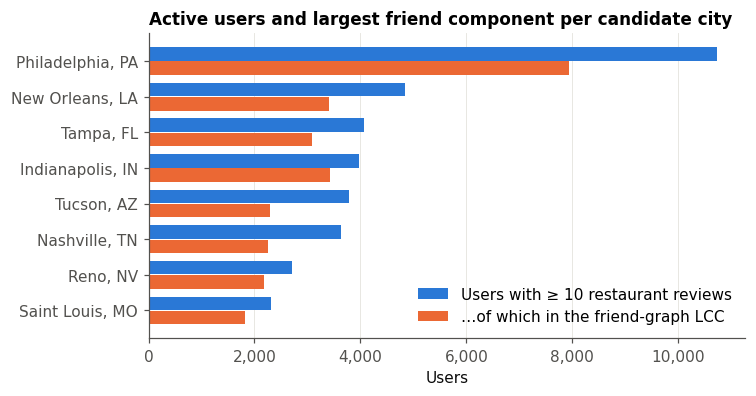

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.6))
order = candidates.sort_values("active_users")
y = np.arange(len(order))
ax.barh(y + 0.2, order.active_users, height=0.38, color=BLUE, label=f"Users with ≥ {MIN_REVIEWS} restaurant reviews")
ax.barh(y - 0.2, order.lcc_users, height=0.38, color=ORANGE, label="…of which in the friend-graph LCC")
ax.set_yticks(y, order.index)
ax.set_xlabel("Users")
ax.xaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax.set_title("Active users and largest friend component per candidate city")
ax.legend(frameon=False, loc="lower right")
ax.grid(axis="y", visible=False)
fig.savefig(FIGURES / "01_city_candidates.png")
plt.show()

The city with the **largest LCC** is selected in the cell below (`CITY`; it can be overridden there). **Misspelled variants** of its name in the same state that the normalisation did not merge are then merged.

In [11]:
CITY = candidates["lcc_users"].idxmax()   # override here, e.g. CITY = "Tampa, FL"
city_name, city_state = CITY.rsplit(", ", 1)
CITY_SLUG = f"{city_name}_{city_state}".lower().replace(" ", "_")
print(f"Chosen city: {CITY}   (file prefix: {CITY_SLUG})\n")

# spelling variants in the same state that normalisation did not merge
same_state = biz[biz.state == city_state]
variants = difflib.get_close_matches(city_name, same_state.city_norm.dropna().unique(), n=15, cutoff=0.75)
var_counts = same_state[same_state.city_norm.isin(variants)].groupby("city_norm").size().sort_values(ascending=False)
print("Close spellings in the same state (businesses):")
print(var_counts.to_string())

# All of these are the same city (typos, "Pa" suffix, a neighbourhood name), so we merge them.
# If you override CITY, inspect this list and remove any name that is really a different place.
CITY_NAMES = set(variants)
city_biz_df = biz[(biz.state == city_state) & biz.city_norm.isin(CITY_NAMES)]
city_biz = set(city_biz_df.business_id)
print(f"\nBusinesses in {CITY} after merging variants: {len(city_biz):,} "
      f"(+{len(city_biz) - (biz.city_key == CITY).sum()} from variant spellings)")

Chosen city: Philadelphia, PA   (file prefix: philadelphia_pa)



Close spellings in the same state (businesses):
city_norm
Philadelphia         14575
Philadephia              7
Philadelphia Pa          2
Philadelphila            1
Philiadelphia            1
Philiidelphia            1
West Philadelphia        1

Businesses in Philadelphia, PA after merging variants: 14,588 (+13 from variant spellings)


## 1.4 Filtering the chosen city

The filters are applied **in this order**, logging reviews / users / businesses after each one:

1. **City**: reviews of businesses in the chosen city (including the merged spelling variants).
2. **Restaurants**: reviews of businesses tagged `Restaurants` (see 1.1).
3. **One review per (user, restaurant)**: the **most recent** review is kept.
4. **Users with ≥ `MIN_REVIEWS` restaurant reviews.**
5. **Largest connected component of the friendship graph** among the remaining users.

The friend graph is built after the activity filter, so every node is an active restaurant reviewer. The LCC filter (5) only removes users, so every kept user still has ≥ `MIN_REVIEWS` reviews.

In [12]:
funnel = []
def log_step(step, reviews, n_edges=None):
    funnel.append({"step": step, "reviews": len(reviews), "users": reviews.user_id.nunique(),
                   "businesses": reviews.business_id.nunique(), "friend_edges": n_edges})

log_step("0. all reviews (whole dataset)", reviews_all)

# 1. city -------------------------------------------------------------
rv = reviews_all[reviews_all.business_id.isin(list(city_biz))].drop(columns="city_key").copy()
rv["user_id"] = rv["user_id"].astype(str)
rv["business_id"] = rv["business_id"].astype(str)
log_step(f"1. reviews in {CITY}", rv)

# 2. restaurants only ----------------------------------------------------
rv = rv[rv.business_id.isin(scope_ids)].reset_index(drop=True)
log_step(f"2. only '{BUSINESS_CATEGORY}'", rv)

# 3. one review per (user, business): keep the most recent --------------
dup_pairs = rv.duplicated(["user_id", "business_id"], keep=False)
print(f"Reviews that are repeats of the same (user, restaurant): {dup_pairs.sum():,} "
      f"in {rv[dup_pairs].groupby(['user_id', 'business_id']).ngroups:,} pairs")
rv = (rv.sort_values(["user_id", "business_id", "date"])
        .drop_duplicates(["user_id", "business_id"], keep="last")
        .reset_index(drop=True))
log_step("3. one review per (user, restaurant)", rv)

# 4. users with >= MIN_REVIEWS reviews -----------------------------------
n_per_user = rv.groupby("user_id").size()
active_users = set(n_per_user[n_per_user >= MIN_REVIEWS].index)
rv = rv[rv.user_id.isin(active_users)].reset_index(drop=True)
log_step(f"4. users with >= {MIN_REVIEWS} restaurant reviews", rv)

# Active users whose friend list we have not read yet (e.g. pushed over the threshold by the
# merged spelling variants, or a CITY override): stream the user file once more for them.
missing_profiles = active_users - set(users_cand.user_id)
if missing_profiles:
    extra, _ = stream_users(raw_file("user"), missing_profiles)
    users_cand = pd.concat([users_cand, extra], ignore_index=True)
    users_cand.to_parquet(USERS_CAND, index=False)
    friends_of.update(zip(extra.user_id, extra.friends))
print(f"Active users whose profile had to be fetched additionally: {len(missing_profiles):,}")

# 5. friendship graph + largest connected component ----------------------
G_all, recip = build_friend_graph(active_users, friends_of)
components = sorted(nx.connected_components(G_all), key=len, reverse=True)
lcc_nodes = components[0]
G = G_all.subgraph(lcc_nodes).copy()
rv = rv[rv.user_id.isin(lcc_nodes)].reset_index(drop=True)
log_step("5. largest connected component", rv, n_edges=G.number_of_edges())

funnel_df = pd.DataFrame(funnel).set_index("step")
funnel_df["users_kept_vs_prev"] = funnel_df.users / funnel_df.users.shift()
funnel_df.style.format({"reviews": "{:,}", "users": "{:,}", "businesses": "{:,}",
                        "friend_edges": lambda v: "" if pd.isna(v) else f"{int(v):,}",
                        "users_kept_vs_prev": lambda v: "" if pd.isna(v) else f"{v:.1%}"})

Reviews that are repeats of the same (user, restaurant): 40,876 in 19,331 pairs


Active users whose profile had to be fetched additionally: 0


,reviews,users,businesses,friend_edges,users_kept_vs_prev
step,,,,,
0. all reviews (whole dataset),"6,990,280","1,987,929","150,346",,
"1. reviews in Philadelphia, PA","968,388","280,107","14,588",,14.1%
2. only 'Restaurants',"687,827","209,694","5,856",,74.9%
"3. one review per (user, restaurant)","666,282","209,694","5,856",,100.0%
4. users with >= 10 restaurant reviews,"295,175","10,732","5,797",,5.1%
5. largest connected component,"251,375","7,947","5,759","67,622",74.0%


What the friend graph looked like **before** taking the LCC, i.e. which users the LCC filter removes:

In [13]:
sizes = pd.Series([len(c) for c in components])
print(f"Active users                 : {G_all.number_of_nodes():,}")
print(f"Friend edges among them      : {G_all.number_of_edges():,}")
print(f"Reciprocated friend links    : {recip:.1%}  (share of u->v links where v->u is also listed)")
print(f"Connected components         : {len(components):,}")
print(f"  of which isolated users    : {(sizes == 1).sum():,}")
print(f"  largest component          : {sizes.iloc[0]:,} users ({sizes.iloc[0] / sizes.sum():.1%})")
print(f"  second largest component   : {sizes.iloc[1] if len(sizes) > 1 else 0:,} users")
print("Component size distribution (size: count):", sizes.value_counts().sort_index().head(10).to_dict())

Active users                 : 10,732
Friend edges among them      : 67,653
Reciprocated friend links    : 100.0%  (share of u->v links where v->u is also listed)
Connected components         : 2,755
  of which isolated users    : 2,725
  largest component          : 7,947 users (74.0%)
  second largest component   : 3 users
Component size distribution (size: count): {1: 2725, 2: 27, 3: 2, 7947: 1}


## 1.5 Normalising star ratings per user

Each user's ratings are centred on their own mean:

$$\tilde r_{u,b} = r_{u,b} - \bar r_u ,\qquad \bar r_u = \frac{1}{|B_u|}\sum_{b\in B_u} r_{u,b}$$

where $B_u$ is the set of businesses user $u$ reviewed **in the cleaned data**. A positive $\tilde r$ means the user rated the business above their own average.

Each user's standard deviation is also stored. Users who give the **same rating to everything** (std = 0) have all-zero normalised ratings; they are flagged, not dropped.

In [14]:
stats_u = rv.groupby("user_id")["stars"].agg(n_reviews="size", mean_stars="mean", std_stars="std")
stats_u["std_stars"] = stats_u["std_stars"].fillna(0.0)
rv = rv.merge(stats_u[["mean_stars"]], left_on="user_id", right_index=True)
rv["stars_norm"] = (rv["stars"] - rv["mean_stars"]).astype("float32")
rv = rv.drop(columns="mean_stars")

flat = (stats_u.std_stars == 0).sum()
print(f"Users whose ratings are all identical (std = 0): {flat:,} ({flat / len(stats_u):.1%})")
print(f"Mean of per-user means: {stats_u.mean_stars.mean():.2f} stars "
      f"(range {stats_u.mean_stars.min():.2f} – {stats_u.mean_stars.max():.2f})")
print(f"Max |mean of normalised ratings| over users: "
      f"{rv.groupby('user_id').stars_norm.mean().abs().max():.2e}  (should be ~0)")

Users whose ratings are all identical (std = 0): 36 (0.5%)
Mean of per-user means: 3.88 stars (range 1.00 – 5.00)


Max |mean of normalised ratings| over users: 2.36e-07  (should be ~0)


### 1.5.1 Positive ratings (for the baskets in section 4)

$$\text{positive}(u,b) \iff r_{u,b} \ge 3.5 \quad(\texttt{POSITIVE\_MIN\_STARS})$$

Review stars are whole numbers, so this means **4 or 5 stars**. It is stored as the boolean column `is_positive` next to the raw and normalised stars. The cell also counts users with an empty basket (no positive review) and with a single positive review (no frequent *pair* possible).

In [15]:
rv["is_positive"] = rv["stars"] >= POSITIVE_MIN_STARS
pos_per_user = rv.groupby("user_id")["is_positive"].sum()

print(f"Positive reviews (stars >= {POSITIVE_MIN_STARS}): {rv.is_positive.sum():,} of {len(rv):,} ({rv.is_positive.mean():.1%})")
print(f"Positive restaurants per user: median {pos_per_user.median():.0f}, mean {pos_per_user.mean():.1f}")
print(f"Users with 0 positive reviews : {(pos_per_user == 0).sum():,}")
print(f"Users with < 2 positive reviews: {(pos_per_user < 2).sum():,} ({(pos_per_user < 2).mean():.1%})")
agree = (rv.is_positive == (rv.stars_norm > 0)).mean()
print(f"Agreement with the relative definition (stars_norm > 0): {agree:.1%} of reviews")

Positive reviews (stars >= 3.5): 174,738 of 251,375 (69.5%)
Positive restaurants per user: median 14, mean 22.0
Users with 0 positive reviews : 6
Users with < 2 positive reviews: 16 (0.2%)
Agreement with the relative definition (stars_norm > 0): 86.5% of reviews


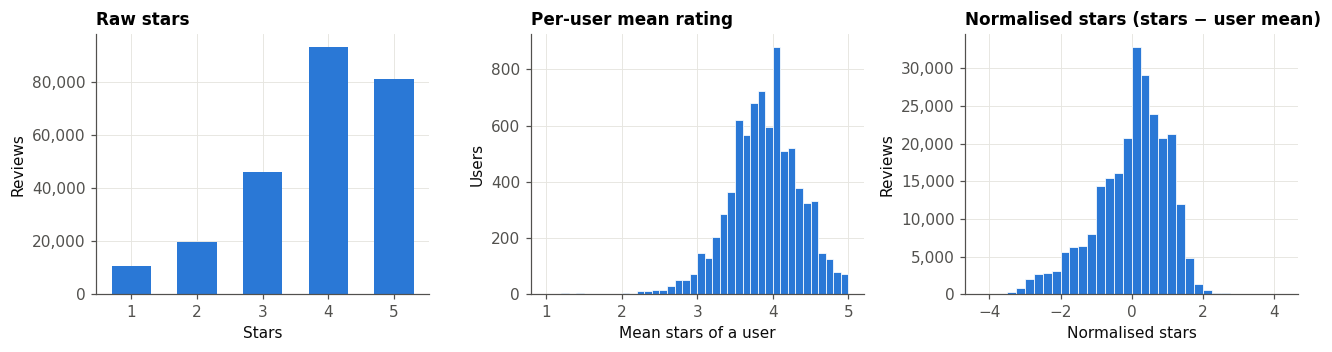

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
vc = rv.stars.value_counts().sort_index()
axes[0].bar(vc.index, vc.values, width=0.6, color=BLUE)
axes[0].set(title="Raw stars", xlabel="Stars", ylabel="Reviews")
axes[1].hist(stats_u.mean_stars, bins=40, color=BLUE, edgecolor="white", linewidth=0.5)
axes[1].set(title="Per-user mean rating", xlabel="Mean stars of a user", ylabel="Users")
axes[2].hist(rv.stars_norm, bins=np.arange(-4.25, 4.3, 0.25), color=BLUE, edgecolor="white", linewidth=0.5)
axes[2].set(title="Normalised stars (stars − user mean)", xlabel="Normalised stars", ylabel="Reviews")
for ax in axes:
    ax.yaxis.set_major_formatter(matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
fig.tight_layout()
fig.savefig(FIGURES / "01_star_normalisation.png")
plt.show()

## 1.6 A first look at the cleaned data

Distributions of:
- **reviews per user**: the size of each user's taste set (section 3);
- **friends per user**: the degree in the graph partitioned in section 2;
- **reviewers per restaurant**: how much the user–restaurant sets can overlap.

The second cell describes the **categories** of the kept restaurants: how many there are and the share of users reached by each.

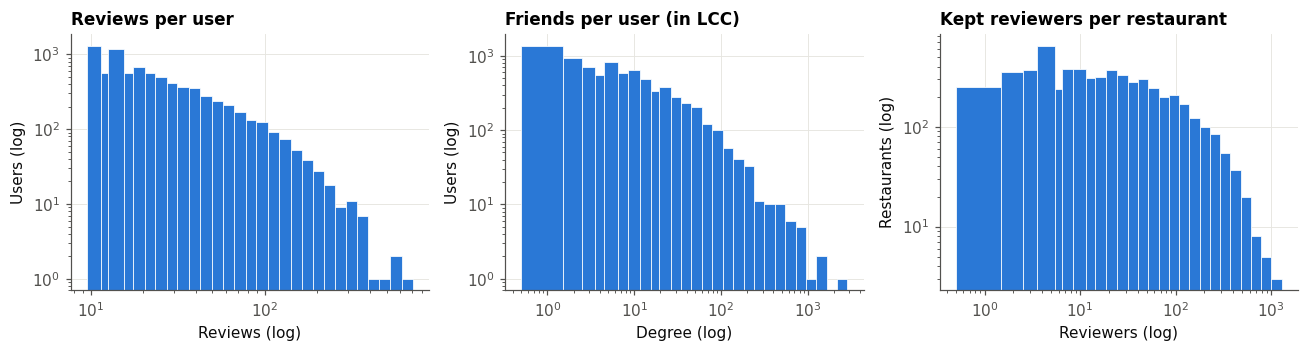

Reviews per user : median 19, mean 31.6, max 706
Friend degree    : median 5, mean 17.0, max 2,832; graph density 2.14e-03
Restaurants reviewed by exactly 1 kept user: 4.4% (they hold 0.1% of reviews)


In [17]:
def int_log_bins(max_value, start=1, n=30):
    # Log-spaced bin edges rounded to integers (avoids empty bins for small integer values).
    return np.unique(np.round(np.logspace(np.log10(start), np.log10(max_value + 1), n))) - 0.5

deg = pd.Series(dict(G.degree()), name="degree")
reviewers_per_biz = rv.groupby("business_id").size()

fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
axes[0].hist(stats_u.n_reviews, bins=int_log_bins(stats_u.n_reviews.max(), start=MIN_REVIEWS), color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].set(xscale="log", yscale="log", title="Reviews per user", xlabel="Reviews (log)", ylabel="Users (log)")
axes[1].hist(deg, bins=int_log_bins(deg.max()), color=BLUE, edgecolor="white", linewidth=0.5)
axes[1].set(xscale="log", yscale="log", title="Friends per user (in LCC)", xlabel="Degree (log)", ylabel="Users (log)")
axes[2].hist(reviewers_per_biz, bins=int_log_bins(reviewers_per_biz.max()), color=BLUE, edgecolor="white", linewidth=0.5)
axes[2].set(xscale="log", yscale="log", title="Kept reviewers per restaurant", xlabel="Reviewers (log)", ylabel="Restaurants (log)")
fig.tight_layout()
fig.savefig(FIGURES / "01_cleaned_distributions.png")
plt.show()

print(f"Reviews per user : median {stats_u.n_reviews.median():.0f}, "
      f"mean {stats_u.n_reviews.mean():.1f}, max {stats_u.n_reviews.max():,}")
print(f"Friend degree    : median {deg.median():.0f}, mean {deg.mean():.1f}, max {deg.max():,}; "
      f"graph density {nx.density(G):.2e}")
print(f"Restaurants reviewed by exactly 1 kept user: {(reviewers_per_biz == 1).mean():.1%} "
      f"(they hold {reviewers_per_biz[reviewers_per_biz == 1].sum() / len(rv):.1%} of reviews)")

In [18]:
# Categories of the kept restaurants (what steps 3–4 can use instead of restaurant IDs).
# The scope tag itself ("Restaurants") is on every business now, so it carries no information:
# `categories_taste` is the category list without it.
biz_city = biz[biz.business_id.isin(rv.business_id)].copy()
biz_city["categories_taste"] = biz_city["categories_list"].map(lambda cs: [c for c in cs if c != BUSINESS_CATEGORY])

user_cats = (rv[["user_id", "business_id"]]
             .merge(biz_city[["business_id", "categories_taste"]], on="business_id")
             .explode("categories_taste").dropna(subset=["categories_taste"])
             .drop_duplicates(["user_id", "categories_taste"]))
cats_per_user = user_cats.groupby("user_id").size()
cat_table = pd.DataFrame({
    "restaurants": Counter(c for cs in biz_city.categories_taste for c in cs),
    "share_of_users": user_cats.groupby("categories_taste").size() / rv.user_id.nunique(),
}).sort_values("share_of_users", ascending=False)

print(f"Distinct categories among kept restaurants (without '{BUSINESS_CATEGORY}'): {len(cat_table):,}")
print(f"Distinct categories per user: median {cats_per_user.median():.0f}, mean {cats_per_user.mean():.0f}")
print(f"Categories reached by > 50% of users: {(cat_table.share_of_users > 0.5).sum()}, "
      f"> 25%: {(cat_table.share_of_users > 0.25).sum()}")
closed = biz_city.loc[biz_city.is_open == 0, "business_id"]
print(f"Closed restaurants (is_open = 0): {len(closed) / len(biz_city):.1%} of restaurants, "
      f"{rv.business_id.isin(closed).mean():.1%} of reviews (kept: the reviews still show taste)")
cat_table.head(25).style.format({"restaurants": "{:,}", "share_of_users": "{:.1%}"})

Distinct categories among kept restaurants (without 'Restaurants'): 374
Distinct categories per user: median 48, mean 55
Categories reached by > 50% of users: 36, > 25%: 74
Closed restaurants (is_open = 0): 39.9% of restaurants, 28.6% of reviews (kept: the reviews still show taste)


,restaurants,share_of_users
Food,"1,864",99.3%
Nightlife,"1,025",97.7%
Bars,974,97.4%
American (New),744,95.6%
Breakfast & Brunch,682,94.0%
American (Traditional),652,91.9%
Sandwiches,916,89.9%
Italian,501,83.3%
Coffee & Tea,570,80.5%
Pizza,778,78.7%


## 1.7 Sanity checks and saving

The properties the later sections rely on are **asserted** before saving; the notebook stops if any of them fails.

In [19]:
kept_users = set(rv.user_id)
assert kept_users == set(G.nodes), "users in reviews and in the graph must be identical"
assert nx.is_connected(G), "the friendship graph must be one connected component"
assert rv.groupby("user_id").size().min() >= MIN_REVIEWS, "every user needs >= MIN_REVIEWS reviews"
assert not rv.duplicated(["user_id", "business_id"]).any(), "one review per (user, business)"
assert rv.business_id.isin(city_biz).all(), "all businesses are in the chosen city"
assert rv.business_id.isin(scope_ids).all(), "all businesses are restaurants"
assert (rv.is_positive == (rv.stars >= POSITIVE_MIN_STARS)).all(), "is_positive follows the threshold"
assert rv.stars.between(1, 5).all(), "stars are in 1..5"
assert np.allclose(rv.groupby("user_id").stars_norm.mean(), 0, atol=1e-5), "normalised ratings average 0 per user"
assert kept_users <= set(users_cand.user_id), "every kept user has a profile in the user file"
print("All checks passed.")

All checks passed.


We save four tables, prefixed with the city (`<city>` = the `CITY_SLUG` printed above):

| File | One row per | Columns |
|---|---|---|
| `<city>_users.parquet` | user in the LCC | `user_id`, `n_reviews`, `n_positive`, `mean_stars`, `std_stars` (from the cleaned reviews), `degree` (friends in the LCC), and profile fields from the user file: `yelp_review_count`, `yelping_since`, `fans`, `yelp_average_stars` |
| `<city>_friend_edges.parquet` | undirected friendship | `u`, `v` with `u < v` |
| `<city>_reviews.parquet` | (user, restaurant) | `user_id`, `business_id`, `stars`, `stars_norm`, `is_positive` (stars ≥ 3.5), `date` |
| `<city>_businesses.parquet` | restaurant with ≥ 1 kept review | `business_id`, `name`, `city`, `state`, `latitude`, `longitude`, `stars`, `review_count`, `is_open`, `categories` (full list), `categories_taste` (without `Restaurants`), `n_reviews_clean` |

`cleaning_summary.json` records the parameters and the counts after every filter.

In [20]:
users_out = (stats_u.loc[sorted(kept_users)]
             .join(pos_per_user.rename("n_positive"))
             .join(deg)
             .join(users_cand.set_index("user_id")[["review_count", "yelping_since", "fans", "average_stars"]]
                   .rename(columns={"review_count": "yelp_review_count", "average_stars": "yelp_average_stars"}))
             .reset_index().rename(columns={"index": "user_id"}))
users_out["yelping_since"] = pd.to_datetime(users_out["yelping_since"])

edges_out = pd.DataFrame([tuple(sorted(e)) for e in G.edges()], columns=["u", "v"]).sort_values(["u", "v"])

reviews_out = rv[["user_id", "business_id", "stars", "stars_norm", "is_positive", "date"]].sort_values(["user_id", "date"])

biz_out = (biz_city[["business_id", "name", "city_norm", "state", "latitude", "longitude",
                     "stars", "review_count", "is_open", "categories_list", "categories_taste"]]
           .rename(columns={"categories_list": "categories"})
           .assign(city=city_name)            # canonical name (merges the spelling variants)
           .drop(columns="city_norm")
           .merge(reviewers_per_biz.rename("n_reviews_clean"), left_on="business_id", right_index=True))

outputs = {"users": users_out, "friend_edges": edges_out, "reviews": reviews_out, "businesses": biz_out}
for name, df in outputs.items():
    path = DATA_PROCESSED / f"{CITY_SLUG}_{name}.parquet"
    df.to_parquet(path, index=False)
    print(f"{path.relative_to(ROOT)}: {len(df):,} rows x {df.shape[1]} cols, {path.stat().st_size / 1e6:.1f} MB")

summary = {
    "city": CITY, "business_category": BUSINESS_CATEGORY, "min_reviews": MIN_REVIEWS,
    "positive_min_stars": POSITIVE_MIN_STARS, "seed": SEED,
    "dedup_rule": "keep most recent review per (user, business)",
    "normalisation": "stars_norm = stars - mean stars of the user over the cleaned reviews",
    "positive": f"is_positive = stars >= {POSITIVE_MIN_STARS}",
    "funnel": (funnel_df.drop(columns="users_kept_vs_prev").reset_index()
               .astype(object).where(lambda d: d.notna(), None).to_dict(orient="records")),
    "final": {"users": len(users_out), "friend_edges": len(edges_out),
              "reviews": len(reviews_out), "businesses": len(biz_out)},
}
(DATA_PROCESSED / "cleaning_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("data/processed/cleaning_summary.json written")

data/processed/philadelphia_pa_users.parquet: 7,947 rows x 10 cols, 0.4 MB
data/processed/philadelphia_pa_friend_edges.parquet: 67,622 rows x 2 cols, 0.4 MB
data/processed/philadelphia_pa_reviews.parquet: 251,375 rows x 6 cols, 3.3 MB
data/processed/philadelphia_pa_businesses.parquet: 5,759 rows x 12 cols, 0.4 MB
data/processed/cleaning_summary.json written


In [21]:
# schema and row count of every table in data/processed/
for f in sorted(DATA_PROCESSED.glob("*.parquet")):
    pf = pq.ParquetFile(f)
    print(f"{f.name}: {pf.metadata.num_rows:,} rows")
    print("   ", pf.schema_arrow)
    print()

philadelphia_pa_businesses.parquet: 5,759 rows
    business_id: string
name: string
state: string
latitude: double
longitude: double
stars: double
review_count: int64
is_open: int64
categories: list<element: string>
  child 0, element: string
categories_taste: list<element: string>
  child 0, element: string
city: string
n_reviews_clean: int64
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 1493

philadelphia_pa_friend_communities.parquet: 7,947 rows
    user_id: string
friend_community: int64
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 318

philadelphia_pa_friend_communities_all_seeds.parquet: 7,947 rows
    user_id: string
seed_0: int64
seed_1: int64
seed_2: int64
seed_3: int64
seed_4: int64
seed_5: int64
seed_6: int64
seed_7: int64
seed_8: int64
seed_9: int64
seed_10: int64
seed_11: int64
seed_12: int64
seed_13: int64
seed_14: int64
seed_15: int64
seed_16: int64
seed_17: int64
s

## 1.8 Summary

**Final cleaned dataset (Philadelphia, PA)**

| | Count |
|---|---|
| Users (all with ≥ 10 restaurant reviews, all in one friend component) | 7,947 |
| Friendships (undirected) | 67,622 |
| Reviews (one per user–restaurant, with normalised stars and `is_positive`) | 251,375 |
| Restaurants | 5,759 |

# 2. Friend communities (Louvain, implemented from scratch)

*Code: Louvain is written in section 2.2; `src/louvain.py` holds the same code (plus edge weights) for reuse in section 3.*

**Plan**
- **2.1** Load the cleaned friendship graph from section 1.
- **2.2** **Louvain written from scratch** (local moving + aggregation), and the modularity formula.
- **2.3** Validation: Zachary's karate club, and our Louvain vs `networkx` on the real graph.
- **2.4** 20 random seeds: modularity, number of communities, **stability** between runs.
- **2.5** Effect of the **resolution parameter**.
- **2.6** The final communities: sizes, density, hubs, user profile, period of activity.
- **2.7** **Robustness**: hubs removed, and a degree-preserving random graph.
- **2.8** Save the partition to `data/processed/`.
- **2.9** Summary.

## 2.0 Parameters

`N_SEEDS` and `RESOLUTION` are set in 0.2. The random generators are re-seeded with `SEED`.

In [22]:
P = str(DATA_PROCESSED / "philadelphia_pa_")  # prefix of the files written by section 1

# ---------------- Parameters (N_SEEDS and RESOLUTION: see 0.2) ----------------
RESOLUTIONS = [0.5, 0.75, 1.0, 1.25, 1.5, 2.0]   # values compared in section 2.5
SEEDS_PER_RESOLUTION = 5
HUB_QUANTILE = 0.99                # "hub" = top 1% of users by number of friends
N_NULL_GRAPHS = 3                  # degree-preserving random graphs in section 2.7
random.seed(SEED)
np.random.seed(SEED)

## 2.1 Load the friendship graph

The edge list and user table of section 1 are loaded into an **undirected, unweighted** graph. The nodes are sorted, so the seeded runs are reproducible.

In [23]:
edges = pd.read_parquet(P + "friend_edges.parquet")
users = pd.read_parquet(P + "users.parquet").set_index("user_id")

G = nx.Graph()
G.add_nodes_from(sorted(users.index))
G.add_edges_from(sorted(zip(edges.u, edges.v)))

print(f"Nodes: {G.number_of_nodes():,}   Edges: {G.number_of_edges():,}")
print(f"Connected: {nx.is_connected(G)}   Self-loops: {nx.number_of_selfloops(G)}")
print(f"Mean degree: {2 * G.number_of_edges() / G.number_of_nodes():.1f}   density: {nx.density(G):.2e}")
assert set(G.nodes) == set(users.index) and nx.is_connected(G)
assert dict(G.degree()) == users.degree.to_dict(), "degrees must match the users table of step 1"

Nodes: 7,947   Edges: 67,622
Connected: True   Self-loops: 0
Mean degree: 17.0   density: 2.14e-03


## 2.2 Louvain from scratch

**Modularity** measures how much more densely the communities are connected inside than expected in a random graph with the same degrees:

$$Q=\sum_{C}\left[\frac{\Sigma_{in}(C)}{2m}-\gamma\left(\frac{\Sigma_{tot}(C)}{2m}\right)^2\right]$$

where $m$ is the number of edges, $\Sigma_{in}(C)$ is the sum of the degrees' internal part (every internal edge counted twice), $\Sigma_{tot}(C)$ is the sum of the degrees of the nodes in $C$, and $\gamma$ is the **resolution** ($\gamma=1$ is the standard definition).

**Louvain** repeats two phases until modularity stops improving:
1. **Local moving.** Visit the nodes in random order. Remove node $i$ from its community and put it in the neighbouring community (or back in its own) that gives the largest gain
$$\Delta Q \propto k_{i,C}-\gamma\,\frac{\Sigma_{tot}(C)\,k_i}{2m},$$
where $k_{i,C}$ is the weight of the links from $i$ to $C$ and $k_i$ is the degree of $i$. Repeat until no node moves.
2. **Aggregation.** Collapse every community into one super-node. Links between communities are summed, and the links inside a community become a self-loop. Go back to phase 1 on the smaller graph.

The result is a hierarchy of partitions; the last (coarsest) level is kept. The algorithm is greedy and the visiting order is random, so different seeds can give different partitions.

Implementation notes: the graph is stored as a list of dictionaries (`adj[i][j] = weight`). A self-loop `adj[c][c]` holds the weight of all links inside the community with each internal edge counted twice, so the degree of a super-node is the sum of its dictionary and $2m$ never changes. The code uses only the standard library.

**Connectivity fix.** Louvain can leave a community **internally disconnected** (Traag, Waltman & van Eck, 2019): when a node that bridges two parts of a community moves away, later aggregation steps can never split it again. `split_disconnected` replaces every disconnected community by its connected components. This can only **raise** $Q$: the internal edges stay the same, while $\sum_C \Sigma_{tot}(C)^2$ gets smaller. `louvain_connected` = Louvain + this step; it is used from section 2.4 on (section 2.3 validates plain Louvain).

In [24]:
def modularity(G, labels, gamma=1.0):
    # Modularity of a partition {node: community}, straight from the definition (independent of Louvain).
    m2 = 2 * G.number_of_edges()
    inside, total = Counter(), Counter()
    for u, v in G.edges():
        if labels[u] == labels[v]:
            inside[labels[u]] += 2
    for u, d in G.degree():
        total[labels[u]] += d
    return sum(inside[c] / m2 - gamma * (total[c] / m2) ** 2 for c in total)


def to_adjacency(G, index):
    adj = [dict() for _ in range(len(index))]
    for u, v in G.edges():
        if u != v:
            adj[index[u]][index[v]] = 1.0
            adj[index[v]][index[u]] = 1.0
    return adj


def local_moving(adj, gamma, rng):
    # Phase 1: move single nodes to the neighbouring community with the best gain until no node moves.
    n = len(adj)
    k = [sum(a.values()) for a in adj]          # degree of each (super-)node, self-loop included
    m2 = sum(k)                                  # 2m
    comm = list(range(n))                        # every node starts alone
    tot = k[:]                                   # sum of degrees of each community
    order = list(range(n))
    moved_any, improved = False, True
    while improved:
        improved = False
        rng.shuffle(order)
        for i in order:
            ci = comm[i]
            w = defaultdict(float)               # weight from i to each neighbouring community
            for j, wij in adj[i].items():
                if j != i:
                    w[comm[j]] += wij
            tot[ci] -= k[i]                      # take i out of its community
            best, best_gain = ci, w.get(ci, 0.0) - gamma * tot[ci] * k[i] / m2
            for c, wc in w.items():
                gain = wc - gamma * tot[c] * k[i] / m2
                if gain > best_gain + 1e-12:     # strict improvement, so ties keep the node where it is
                    best, best_gain = c, gain
            tot[best] += k[i]
            if best != ci:
                comm[i] = best
                improved = moved_any = True
    return comm, moved_any


def aggregate(adj, comm):
    # Phase 2: one super-node per community; parallel links are summed, internal links become a self-loop.
    ids = {c: x for x, c in enumerate(sorted(set(comm)))}
    c2 = [ids[c] for c in comm]
    new = [defaultdict(float) for _ in ids]
    for i, a in enumerate(adj):
        for j, w in a.items():
            new[c2[i]][c2[j]] += w
    return [dict(d) for d in new], c2


def louvain(G, gamma=1.0, seed=0):
    # Returns (partition {node: community}, list of partitions after each aggregation level).
    rng = random.Random(seed)
    nodes = list(G.nodes())
    index = {u: i for i, u in enumerate(nodes)}
    adj = to_adjacency(G, index)
    membership = list(range(len(nodes)))         # original node -> current super-node
    levels = []
    while True:
        comm, moved = local_moving(adj, gamma, rng)
        if not moved:
            break
        adj, c2 = aggregate(adj, comm)
        membership = [c2[m] for m in membership]
        levels.append({u: membership[index[u]] for u in nodes})
    if not levels:                               # nothing moved: every node is its own community
        levels.append({u: index[u] for u in nodes})
    return levels[-1], levels


def n_communities(part):
    return len(set(part.values()))


def split_disconnected(G, part):
    # Replace every internally disconnected community by its connected components.
    # Returns (new partition, number of communities that had to be split). Never lowers Q.
    groups = defaultdict(list)
    for u, c in part.items():
        groups[c].append(u)
    new, n_split, next_id = {}, 0, 0
    for c in sorted(groups):
        comps = list(nx.connected_components(G.subgraph(groups[c])))
        n_split += len(comps) > 1
        for comp in sorted(comps, key=lambda s: (-len(s), min(s))):   # deterministic order
            for u in comp:
                new[u] = next_id
            next_id += 1
    return new, n_split


def louvain_connected(G, gamma=1.0, seed=0):
    part, _ = louvain(G, gamma=gamma, seed=seed)
    return split_disconnected(G, part)[0]

## 2.3 Validating our implementation

The implementation is checked in three ways:
1. **Modularity formula:** our `modularity()` against `networkx` on the same partition.
2. **Zachary's karate club:** a 34-node graph where the best known Louvain modularity is about 0.419.
3. **The real graph:** the modularity of our Louvain against `networkx.community.louvain_communities`.

In [25]:
# 1+2. karate club
K = nx.Graph(nx.karate_club_graph().edges())   # drop the edge weights that newer networkx versions attach
q_ours = [modularity(K, louvain(K, seed=s)[0]) for s in range(30)]
p_ref = nx.community.louvain_communities(K, seed=0)
ref_labels = {u: i for i, c in enumerate(p_ref) for u in c}
assert abs(modularity(K, ref_labels) - nx.community.modularity(K, p_ref)) < 1e-12, "modularity() disagrees with networkx"
print(f"Karate club: our Louvain Q over 30 seeds = {np.mean(q_ours):.4f} (max {np.max(q_ours):.4f}); best known ~ 0.4198")
print("modularity() agrees with networkx on the reference partition: OK")

# 3. real graph, a quick comparison on 5 seeds
t0 = time.perf_counter()
ours = [modularity(G, louvain(G, seed=s)[0]) for s in range(5)]
t_ours = (time.perf_counter() - t0) / 5
t0 = time.perf_counter()
ref = [nx.community.modularity(G, nx.community.louvain_communities(G, seed=s)) for s in range(5)]
t_ref = (time.perf_counter() - t0) / 5
print(f"\nPhiladelphia graph, 5 seeds each:")
print(f"  ours     : Q = {np.mean(ours):.4f} +- {np.std(ours):.4f}   ({t_ours:.1f} s per run)")
print(f"  networkx : Q = {np.mean(ref):.4f} +- {np.std(ref):.4f}   ({t_ref:.1f} s per run)")

Karate club: our Louvain Q over 30 seeds = 0.4165 (max 0.4198); best known ~ 0.4198
modularity() agrees with networkx on the reference partition: OK



Philadelphia graph, 5 seeds each:
  ours     : Q = 0.3756 +- 0.0078   (0.3 s per run)
  networkx : Q = 0.3762 +- 0.0064   (0.6 s per run)


## 2.4 Many seeds: modularity and stability

Louvain is run with **`N_SEEDS` different seeds**. For each run: the modularity $Q$ and the number of communities. **Stability** between runs: the Adjusted Rand Index (ARI) and the Normalised Mutual Information (NMI) between every pair of partitions (both defined in 5.2).

Every run goes through the connectivity fix of section 2.2, and the number of communities it had to split is counted. The run with the highest modularity is **the** friend partition; all 20 partitions are saved (section 2.8).

In [26]:
runs = []
t0 = time.perf_counter()
for s in range(N_SEEDS):
    part_raw, levels = louvain(G, gamma=RESOLUTION, seed=s)
    part, n_split = split_disconnected(G, part_raw)
    runs.append({"seed": s, "Q": modularity(G, part), "Q_before_fix": modularity(G, part_raw),
                 "n_comm": n_communities(part), "split_communities": n_split,
                 "n_levels": len(levels), "part": part, "levels": levels})
print(f"{N_SEEDS} runs in {time.perf_counter() - t0:.0f} s")

runs_df = pd.DataFrame(runs).drop(columns=["part", "levels"]).set_index("seed")
print(runs_df.describe().loc[["mean", "std", "min", "max"]].round(4).to_string())
gain = runs_df.Q - runs_df.Q_before_fix
assert (gain >= -1e-12).all(), "splitting disconnected communities must never lower Q"
print(f"\nConnectivity fix: {(runs_df.split_communities > 0).sum()} of {N_SEEDS} runs had at least one disconnected community "
      f"({runs_df.split_communities.sum()} in total); Q gain at most {gain.max():.5f}")

order = list(G.nodes())
labels_mat = [[r["part"][u] for u in order] for r in runs]
ari = np.array([[adjusted_rand_score(a, b) for b in labels_mat] for a in labels_mat])
nmi = np.array([[normalized_mutual_info_score(a, b) for b in labels_mat] for a in labels_mat])
iu = np.triu_indices(N_SEEDS, k=1)
print(f"\nPairwise similarity between runs ({len(iu[0])} pairs):")
print(f"  ARI: mean {ari[iu].mean():.3f}   min {ari[iu].min():.3f}   max {ari[iu].max():.3f}")
print(f"  NMI: mean {nmi[iu].mean():.3f}   min {nmi[iu].min():.3f}   max {nmi[iu].max():.3f}")

best = max(runs, key=lambda r: r["Q"])
print(f"\nBest run: seed {best['seed']}  Q = {best['Q']:.4f}  communities = {best['n_comm']}")
print("Modularity after each aggregation level of the best run (before the fix):",
      [round(modularity(G, lv), 4) for lv in best["levels"]],
      "| communities:", [n_communities(lv) for lv in best["levels"]])

20 runs in 7 s
           Q  Q_before_fix  n_comm  split_communities  n_levels
mean  0.3724        0.3724  53.400             1.1500     4.500
std   0.0138        0.0138  14.009             0.8127     0.513
min   0.3384        0.3384  31.000             0.0000     4.000
max   0.3857        0.3857  83.000             2.0000     5.000

Connectivity fix: 15 of 20 runs had at least one disconnected community (23 in total); Q gain at most 0.00004



Pairwise similarity between runs (190 pairs):
  ARI: mean 0.538   min 0.300   max 0.841
  NMI: mean 0.522   min 0.360   max 0.756

Best run: seed 9  Q = 0.3857  communities = 51
Modularity after each aggregation level of the best run (before the fix): [0.3735, 0.3847, 0.3856, 0.3857, 0.3857] | communities: [529, 107, 63, 52, 51]


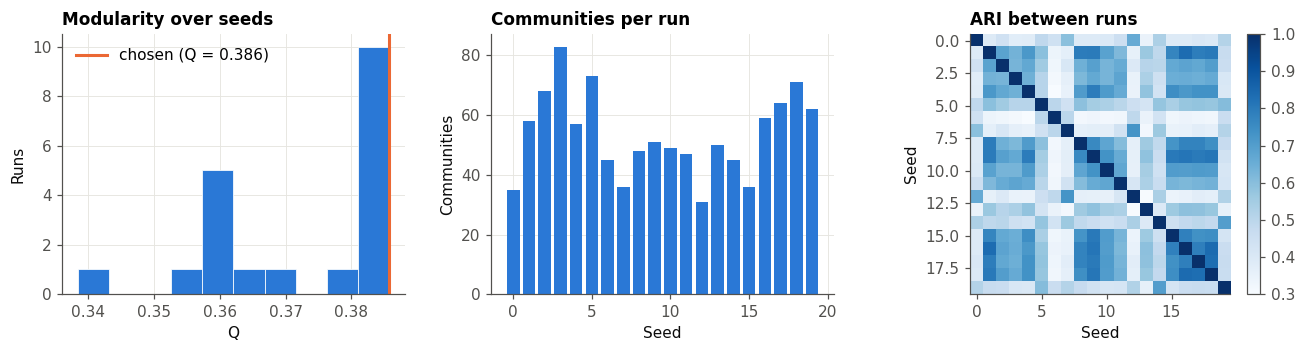

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
axes[0].hist(runs_df.Q, bins=10, color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].axvline(best["Q"], color=ORANGE, lw=2, label=f"chosen (Q = {best['Q']:.3f})")
axes[0].set(title="Modularity over seeds", xlabel="Q", ylabel="Runs")
axes[0].legend(frameon=False)
axes[1].bar(runs_df.index, runs_df.n_comm, color=BLUE)
axes[1].set(title="Communities per run", xlabel="Seed", ylabel="Communities")
im = axes[2].imshow(ari, cmap="Blues", vmin=ari[iu].min(), vmax=1)
axes[2].set(title="ARI between runs", xlabel="Seed", ylabel="Seed")
axes[2].grid(False)
fig.colorbar(im, ax=axes[2], fraction=0.046)
fig.tight_layout()
fig.savefig(FIGURES / "02_louvain_seeds.png")
plt.show()

## 2.5 The resolution parameter

Modularity has a known **resolution limit**: with $\gamma=1$ it can merge small communities or, on some graphs, split large ones. $\gamma$ moves the scale: larger values give more and smaller communities.

Louvain is run for every value in `RESOLUTIONS` (`SEEDS_PER_RESOLUTION` seeds each). Each partition is also scored with the **standard modularity** ($\gamma=1$), the only value comparable across rows. `RESOLUTION` = 1 is used everywhere else.

In [28]:
res_rows = []
t0 = time.perf_counter()
for g in RESOLUTIONS:
    for s in range(SEEDS_PER_RESOLUTION):
        part = louvain_connected(G, gamma=g, seed=100 + s)
        sizes = np.array(sorted(Counter(part.values()).values(), reverse=True))
        res_rows.append({"gamma": g, "seed": s, "n_comm": len(sizes), "Q_standard": modularity(G, part, 1.0),
                         "Q_gamma": modularity(G, part, g), "largest": sizes[0],
                         "communities_ge10": int((sizes >= 10).sum())})
print(f"{len(res_rows)} runs in {time.perf_counter() - t0:.0f} s")
res_df = pd.DataFrame(res_rows)
res_table = res_df.groupby("gamma").agg(n_comm=("n_comm", "mean"), communities_ge10=("communities_ge10", "mean"),
                                        largest=("largest", "mean"), Q_standard=("Q_standard", "mean"),
                                        Q_standard_sd=("Q_standard", "std"))
res_table.round(4)

30 runs in 12 s


,n_comm,communities_ge10,largest,Q_standard,Q_standard_sd
gamma,,,,,
0.50,51.2,4.8,5345.4,0.1979,0.1064
0.75,60.0,10.6,3123.2,0.3567,0.0133
1.00,53.8,12.0,2444.6,0.3800,0.0041
1.25,35.0,15.6,1819.8,0.3694,0.0061
1.50,28.6,21.4,1239.0,0.3480,0.0053
2.00,39.8,38.0,946.8,0.3184,0.0047


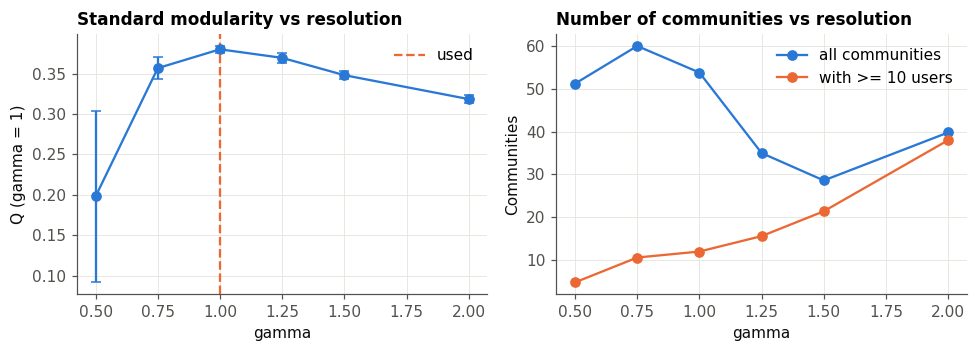

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.3))
axes[0].errorbar(res_table.index, res_table.Q_standard, yerr=res_table.Q_standard_sd, marker="o", color=BLUE, capsize=3)
axes[0].axvline(RESOLUTION, color=ORANGE, ls="--", label="used")
axes[0].set(title="Standard modularity vs resolution", xlabel="gamma", ylabel="Q (gamma = 1)")
axes[0].legend(frameon=False)
axes[1].plot(res_table.index, res_table.n_comm, marker="o", color=BLUE, label="all communities")
axes[1].plot(res_table.index, res_table.communities_ge10, marker="o", color=ORANGE, label="with >= 10 users")
axes[1].set(title="Number of communities vs resolution", xlabel="gamma", ylabel="Communities")
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "02_resolution.png")
plt.show()

## 2.6 Analysing the final communities

The partition is the best run of section 2.4; communities are renumbered by size (0 = largest). For each community:
- size, and **internal density** (internal edges over possible pairs);
- the **share of edge ends that stay inside** the community;
- its **contribution to $Q$**;
- the number of **hubs** (top 1% of users by number of friends) and the share of its internal edges that touch a hub;
- profile of the members: mean number of fans, median year of joining Yelp, mean rating.

In [30]:
part = best["part"]
size_rank = {c: r for r, (c, _) in enumerate(Counter(part.values()).most_common())}
part = {u: size_rank[c] for u, c in part.items()}        # renumber: 0 = largest community
assert abs(modularity(G, part) - best["Q"]) < 1e-9

U = users.copy()
U["community"] = pd.Series(part)
hub_cut = U.degree.quantile(HUB_QUANTILE)
U["is_hub"] = U.degree >= hub_cut
print(f"Hubs: users with >= {hub_cut:.0f} friends -> {U.is_hub.sum()} users ({U.is_hub.mean():.1%})")

E = edges.copy()
E["cu"], E["cv"] = E.u.map(part), E.v.map(part)
E["hub_edge"] = E.u.map(U.is_hub) | E.v.map(U.is_hub)
m = len(E)

rows = []
for c, grp in U.groupby("community"):
    n = len(grp)
    e_int = int(((E.cu == c) & (E.cv == c)).sum())
    e_cut = int(((E.cu == c) != (E.cv == c)).sum())     # edges with exactly one end inside
    tot = int(grp.degree.sum())
    rows.append({"community": c, "users": n, "internal_edges": e_int, "boundary_edges": e_cut,
                 "density": e_int / (n * (n - 1) / 2) if n > 1 else np.nan,
                 "ends_inside": 2 * e_int / tot if tot else np.nan,
                 "Q_contribution": 2 * e_int / (2 * m) - (tot / (2 * m)) ** 2,
                 "hubs": int(grp.is_hub.sum()),
                 "hub_edge_share": float(E.loc[(E.cu == c) & (E.cv == c), "hub_edge"].mean()) if e_int else np.nan,
                 "mean_fans": grp.fans.mean(), "median_join_year": grp.yelping_since.dt.year.median(),
                 "mean_stars": grp.mean_stars.mean()})
comm_df = pd.DataFrame(rows).set_index("community")
assert abs(comm_df.Q_contribution.sum() - best["Q"]) < 1e-9, "contributions must add up to Q"

sizes = comm_df.users
print(f"Communities: {len(comm_df)}   sizes: largest {sizes.max():,}, median {sizes.median():.0f}, smallest {sizes.min()}")
print(f"Communities with >= 50 users: {(sizes >= 50).sum()} (they hold {sizes[sizes >= 50].sum() / sizes.sum():.1%} of the users)")
print(f"Communities with < 10 users : {(sizes < 10).sum()} (they hold {sizes[sizes < 10].sum()} users)")
print(f"Edges inside communities: {(E.cu == E.cv).mean():.1%}")
comm_df.head(15).style.format({"users": "{:,}", "internal_edges": "{:,}", "boundary_edges": "{:,}", "density": "{:.3f}",
                               "ends_inside": "{:.1%}", "Q_contribution": "{:.4f}", "hub_edge_share": "{:.1%}",
                               "mean_fans": "{:.1f}", "median_join_year": "{:.0f}", "mean_stars": "{:.2f}"})

Hubs: users with >= 179 friends -> 81 users (1.0%)
Communities: 51   sizes: largest 2,460, median 3, smallest 2
Communities with >= 50 users: 9 (they hold 97.2% of the users)
Communities with < 10 users : 38 (they hold 132 users)
Edges inside communities: 63.6%


,users,internal_edges,boundary_edges,density,ends_inside,Q_contribution,hubs,hub_edge_share,mean_fans,median_join_year,mean_stars
community,,,,,,,,,,,
0,"2,460","15,563","14,040",0.005,68.9%,0.1186,24,52.1%,11.6,2014,4.00
1,"1,667","7,707","8,130",0.006,65.5%,0.0837,14,38.3%,9.8,2009,3.76
2,"1,607","12,916","16,245",0.010,61.4%,0.0942,38,46.8%,13.1,2011,3.80
3,818,"2,875","3,663",0.009,61.1%,0.0377,0,0.0%,6.0,2013,3.95
4,661,"3,136","5,090",0.014,55.2%,0.0393,5,15.0%,113.4,2010,3.89
5,196,241,650,0.013,42.6%,0.0035,0,0.0%,2.1,2012,3.84
6,123,134,319,0.018,45.7%,0.0020,0,0.0%,2.0,2012,3.88
7,98,107,329,0.023,39.4%,0.0016,0,0.0%,2.9,2012,3.96
8,96,161,318,0.035,50.3%,0.0024,0,0.0%,2.5,2012,3.96


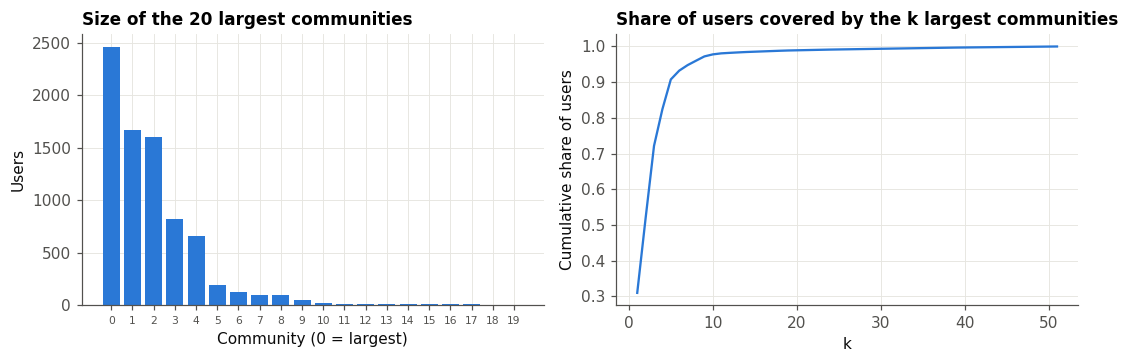

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
top = comm_df.head(20)
axes[0].bar(top.index.astype(str), top.users, color=BLUE)
axes[0].set(title="Size of the 20 largest communities", xlabel="Community (0 = largest)", ylabel="Users")
axes[0].tick_params(axis="x", labelsize=7)
cum = sizes.sort_values(ascending=False).cumsum() / sizes.sum()
axes[1].plot(np.arange(1, len(cum) + 1), cum.values, color=BLUE)
axes[1].set(title="Share of users covered by the k largest communities", xlabel="k", ylabel="Cumulative share of users")
fig.tight_layout()
fig.savefig(FIGURES / "02_community_sizes.png")
plt.show()

### 2.6.1 Do the communities reflect *when* users were active?

For every user: the **median year of their restaurant reviews**. For each community with at least 50 users: the distribution of that year, and the share of its reviews about restaurants closed today. The association between community and period (four bins) is measured with NMI, against the NMI with shuffled community labels.

In [32]:
reviews = pd.read_parquet(P + "reviews.parquet")
biz = pd.read_parquet(P + "businesses.parquet").set_index("business_id")
reviews["community"] = reviews.user_id.map(part)
reviews["closed_now"] = reviews.business_id.map(biz.is_open) == 0
U["median_review_year"] = reviews.groupby("user_id").date.median().dt.year

big_c = comm_df.index[comm_df.users >= 50]
B = U[U.community.isin(big_c)]
era = (B.groupby("community").median_review_year
         .describe()[["count", "25%", "50%", "75%"]]
         .rename(columns={"count": "users", "25%": "year_q25", "50%": "year_median", "75%": "year_q75"})
         .join(reviews[reviews.community.isin(big_c)].groupby("community").closed_now.mean().rename("reviews_of_closed")))

PERIOD_BINS = [0, 2010, 2013, 2016, 2100]           # <=2010, 2011-13, 2014-16, >=2017
period = pd.cut(B.median_review_year, PERIOD_BINS).astype(str)
nmi_era = normalized_mutual_info_score(B.community, period)
rng = np.random.default_rng(SEED)
nmi_shuffled = [normalized_mutual_info_score(rng.permutation(B.community.values), period) for _ in range(100)]
print(f"NMI(friend community, period of activity) = {nmi_era:.3f}   "
      f"shuffled labels: mean {np.mean(nmi_shuffled):.4f}, max {np.max(nmi_shuffled):.4f} (100 shuffles)")
era.style.format({"users": "{:,.0f}", "year_q25": "{:.0f}", "year_median": "{:.0f}", "year_q75": "{:.0f}",
                  "reviews_of_closed": "{:.1%}"})

NMI(friend community, period of activity) = 0.223   shuffled labels: mean 0.0010, max 0.0018 (100 shuffles)


,users,year_q25,year_median,year_q75,reviews_of_closed
community,,,,,
0,"2,460",2016,2018,2019,19.7%
1,"1,667",2009,2010,2012,39.3%
2,"1,607",2012,2013,2015,33.8%
3,818,2014,2016,2018,24.5%
4,661,2012,2015,2017,23.8%
5,196,2013,2014,2016,32.1%
6,123,2014,2015,2016,31.9%
7,98,2013,2015,2017,30.0%
8,96,2013,2015,2017,26.5%


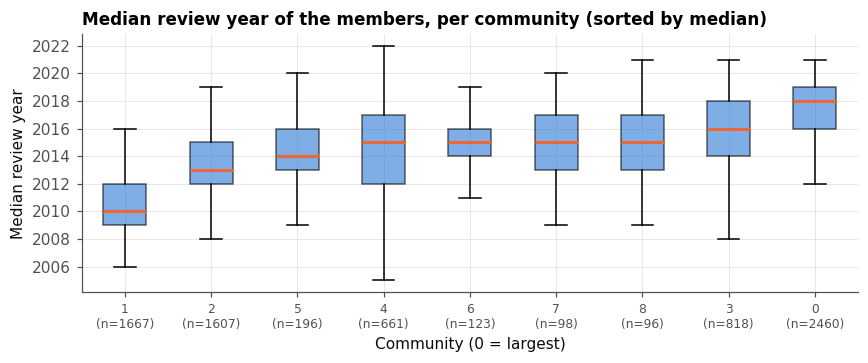

In [33]:
order_c = era.sort_values("year_median").index
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.boxplot([B.loc[B.community == c, "median_review_year"] for c in order_c], showfliers=False,
           patch_artist=True, boxprops=dict(facecolor=BLUE, alpha=0.6), medianprops=dict(color=ORANGE, lw=2))
ax.set_xticks(range(1, len(order_c) + 1), [f"{c}\n(n={int(era.users[c])})" for c in order_c], fontsize=8)
ax.set(title="Median review year of the members, per community (sorted by median)",
       xlabel="Community (0 = largest)", ylabel="Median review year")
ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
fig.tight_layout()
fig.savefig(FIGURES / "02_activity_period.png")
plt.show()

## 2.7 Robustness checks

1. **Hubs removed.** The hubs are removed, Louvain is run again on the largest connected component of what is left, and the result is compared with the full partition on the remaining users (ARI, NMI).
2. **Degree-preserving null model.** `N_NULL_GRAPHS` random graphs with **exactly the same degree for every user** (degree-preserving edge swaps) keep the hubs but destroy who is friends with whom. Their modularity is the chance reference for $Q$.

In [34]:
# 1. remove the hubs
G_nh = G.subgraph([u for u in G if not U.is_hub[u]]).copy()
lcc = max(nx.connected_components(G_nh), key=len)
G_nh = G_nh.subgraph(lcc).copy()
print(f"Without hubs: {G_nh.number_of_nodes():,} users in the largest component "
      f"({G_nh.number_of_nodes() / (G.number_of_nodes() - U.is_hub.sum()):.1%} of the non-hubs), {G_nh.number_of_edges():,} edges")

nh_runs = [louvain_connected(G_nh, seed=s) for s in range(5)]
nh_best = max(nh_runs, key=lambda p: modularity(G_nh, p))
common = list(G_nh.nodes())
a = [part[u] for u in common]
nh_ari = [adjusted_rand_score(a, [p[u] for u in common]) for p in nh_runs]
nh_nmi = [normalized_mutual_info_score(a, [p[u] for u in common]) for p in nh_runs]
print(f"Q without hubs: {np.mean([modularity(G_nh, p) for p in nh_runs]):.4f}   communities: {n_communities(nh_best)}")
print(f"Agreement with the full partition on the remaining users: ARI {np.mean(nh_ari):.3f}, NMI {np.mean(nh_nmi):.3f}")
print(f"(for reference, agreement between two runs on the full graph: ARI {ari[iu].mean():.3f}, NMI {nmi[iu].mean():.3f})")

Without hubs: 7,113 users in the largest component (90.4% of the non-hubs), 36,822 edges


Q without hubs: 0.4881   communities: 35
Agreement with the full partition on the remaining users: ARI 0.485, NMI 0.480
(for reference, agreement between two runs on the full graph: ARI 0.538, NMI 0.522)


In [35]:
# 2. degree-preserving random graphs
null_Q, null_n = [], []
t0 = time.perf_counter()
for s in range(N_NULL_GRAPHS):
    Gn = G.copy()
    nx.double_edge_swap(Gn, nswap=5 * G.number_of_edges(), max_tries=500 * G.number_of_edges(), seed=s)
    pn = louvain_connected(Gn, seed=s)
    null_Q.append(modularity(Gn, pn)); null_n.append(n_communities(pn))
    assert dict(Gn.degree()) == dict(G.degree())
print(f"{N_NULL_GRAPHS} random graphs in {time.perf_counter() - t0:.0f} s")
# Fair comparison: one Louvain run per random graph vs the AVERAGE run on the real graph (not the best of 20).
print(f"Random graphs with the same degrees: Q = {np.mean(null_Q):.4f} (values {np.round(null_Q, 4).tolist()}), "
      f"communities {null_n}")
print(f"Real friendship graph, mean run    : Q = {runs_df.Q.mean():.4f}  (best of {N_SEEDS} runs: {best['Q']:.4f})")

3 random graphs in 14 s
Random graphs with the same degrees: Q = 0.1706 (values [0.1717, 0.1705, 0.1695]), communities [23, 25, 25]
Real friendship graph, mean run    : Q = 0.3724  (best of 20 runs: 0.3857)


## 2.8 Saving the partition

| File | One row per | Columns |
|---|---|---|
| `philadelphia_pa_friend_communities.parquet` | user in the LCC (7,947) | `user_id`, `friend_community` (integer, 0 = largest community) |
| `philadelphia_pa_friend_communities_all_seeds.parquet` | user in the LCC | `user_id`, `seed_0` … `seed_19`: the partition of every run of section 2.4 (after the connectivity fix) |
| `friend_communities_summary.json` | | parameters and the main numbers |

The community ids are **arbitrary labels**; only the grouping matters.

In [36]:
out = (pd.Series(part, name="friend_community").rename_axis("user_id").reset_index()
         .sort_values("user_id").reset_index(drop=True))
assert len(out) == users.shape[0] and out.user_id.is_unique and set(out.user_id) == set(users.index)
out.to_parquet(P + "friend_communities.parquet", index=False)

all_seeds = (pd.DataFrame({f"seed_{r['seed']}": pd.Series(r["part"]) for r in runs})
               .rename_axis("user_id").reset_index().sort_values("user_id").reset_index(drop=True))
assert len(all_seeds) == len(out) and (all_seeds.user_id.values == out.user_id.values).all()
assert adjusted_rand_score(all_seeds[f"seed_{best['seed']}"], out.friend_community) == 1.0, "chosen run must match"
all_seeds.to_parquet(P + "friend_communities_all_seeds.parquet", index=False)

summary = {
    "algorithm": "Louvain, implemented from scratch (this notebook)", "resolution": RESOLUTION,
    "n_seeds": N_SEEDS, "chosen_seed": int(best["seed"]),
    "graph": {"users": G.number_of_nodes(), "edges": G.number_of_edges()},
    "modularity": {"chosen": best["Q"], "mean_over_seeds": float(runs_df.Q.mean()), "sd_over_seeds": float(runs_df.Q.std()),
                   "min": float(runs_df.Q.min()), "max": float(runs_df.Q.max())},
    "communities": {"chosen": int(best["n_comm"]), "mean_over_seeds": float(runs_df.n_comm.mean()),
                    "largest": int(sizes.max()), "with_at_least_50_users": int((sizes >= 50).sum())},
    "stability_between_seeds": {"ARI_mean": float(ari[iu].mean()), "ARI_min": float(ari[iu].min()),
                                "NMI_mean": float(nmi[iu].mean()), "NMI_min": float(nmi[iu].min())},
    "without_hubs": {"hub_definition": f"top {1 - HUB_QUANTILE:.0%} by degree (>= {hub_cut:.0f} friends)",
                     "ARI_with_full_partition": float(np.mean(nh_ari)), "NMI_with_full_partition": float(np.mean(nh_nmi))},
    "random_degree_preserving_graphs": {"modularity_mean": float(np.mean(null_Q)), "modularity_values": null_Q,
                                        "compare_with": "modularity.mean_over_seeds (one run per graph on both sides)"},
    "connectivity_fix": {"runs_with_disconnected_communities": int((runs_df.split_communities > 0).sum()),
                         "disconnected_communities_total": int(runs_df.split_communities.sum()),
                         "max_Q_gain": float(gain.max())},
    "activity_period": {"NMI_community_vs_period": float(nmi_era), "NMI_shuffled_mean": float(np.mean(nmi_shuffled)),
                        "period_bins": "<=2010, 2011-2013, 2014-2016, >=2017 (median review year of the user)",
                        "communities_used": "communities with >= 50 users"},
    "share_of_edges_inside_communities": float((E.cu == E.cv).mean()),
    "files": ["philadelphia_pa_friend_communities.parquet", "philadelphia_pa_friend_communities_all_seeds.parquet"],
}
(DATA_PROCESSED / "friend_communities_summary.json").write_text(json.dumps(summary, indent=2))
print(f"{(P + 'friend_communities.parquet')} written: {len(out):,} rows")
print(f"{(P + 'friend_communities_all_seeds.parquet')} written: {all_seeds.shape[0]:,} rows x {all_seeds.shape[1] - 1} partitions")
print("friend_communities_summary.json written")
out.friend_community.value_counts().head(10)

/Users/viktor/Desktop/masters/DTU_2026_27/1st_semester/Computational_Tools_for_Data_Science/Computational-tools-4-datasciense-main/data/processed/philadelphia_pa_friend_communities.parquet written: 7,947 rows
/Users/viktor/Desktop/masters/DTU_2026_27/1st_semester/Computational_Tools_for_Data_Science/Computational-tools-4-datasciense-main/data/processed/philadelphia_pa_friend_communities_all_seeds.parquet written: 7,947 rows x 20 partitions
friend_communities_summary.json written


friend_community
0    2460
1    1667
2    1607
3     818
4     661
5     196
6     123
7      98
8      96
9      45
Name: count, dtype: int64

## 2.9 Summary

| | Value |
|---|---|
| Users / friendships | 7,947 / 67,622 |
| Communities, chosen run (seed 9) | 51 (9 with ≥ 50 users; largest 2,460) |
| Modularity, chosen run | 0.386 |
| Modularity over 20 seeds, mean ± sd | 0.372 ± 0.014 |
| Modularity of degree-preserving random graphs | 0.171 |
| Stability between seeds, ARI / NMI mean (min) | 0.54 (0.30) / 0.52 (0.36) |
| Agreement with the partition without hubs, ARI / NMI | 0.49 / 0.48 |
| Share of friendships inside a community | 63.6 % |
| NMI community vs period of activity (shuffled) | 0.223 (0.001) |
| Runs with a disconnected community (communities split) | 15 of 20 (23) |

# 3. Taste communities

*Code: `src/taste.py` (functions), `src/lsh.py` (MinHash + LSH).*

**Plan**
- **3.1** For each user, the set of things they like (two versions: restaurants and categories).
- **3.2** MinHash + LSH (from scratch) to find pairs of users with similar sets.
- **3.3** Taste-similarity graph → Louvain communities.
- **3.4** Summary.

## 3.0 Parameters

Inputs are the files written by section 1 (`data/processed/philadelphia_pa_*.parquet`). The category filter (`GENERIC_MAX_FRAC`, `MAX_CATS_PER_BUSINESS`, `MIN_BUSINESSES_PER_CATEGORY`) and the Louvain settings (`N_SEEDS`, `RESOLUTION`) are set in 0.2.

In [37]:
import louvain, lsh, taste   # project modules (src/)

# ---------------- Parameters (category filter, N_SEEDS, RESOLUTION: see 0.2) ----------------
POSITIVE_COL = "is_positive"     # "liked" = stars >= 3.5, same definition as section 1
GENERIC_SWEEP = (0.3, 0.5, 0.7, 0.8, 0.9)

# 3.2 MinHash + LSH
N_HASHES = 240                   # signature length (b * r)
K_NEIGHBOURS = 10                # taste graph: each user is linked to its 10 most similar users
ROWS_RANGE = {"business": (2, 5), "category": (2, 6)}   # r values tried in the (b, r) sweep
MIN_RECALL = 0.90                # the chosen (b, r) must find >= 90 % of the true nearest neighbours
MAX_BUCKET = 1000                # skip LSH buckets with more users than this (reported)
FALLBACK_BRUTE_FORCE = True      # if no (b, r) reaches MIN_RECALL, use the exact neighbours (reported)

## 3.1 User sets

**Liked.** A user likes a restaurant if `is_positive` is true (4 or 5 stars, section 1.5.1).

**Two versions of each user's set**
1. **Restaurants**: the set of liked `business_id`s.
2. **Categories**: the set of categories of the liked restaurants.

The category version starts from `categories_taste` (section 1) and removes:
- **multi-purpose venues**: restaurants with more than `MAX_CATS_PER_BUSINESS` = 20 categories (only *Reading Terminal Market*, 35) are left out of the category version; they stay in the restaurant version;
- **rare categories**, present in fewer than `MIN_BUSINESSES_PER_CATEGORY` = 5 restaurants;
- **generic categories**, liked by more than `GENERIC_MAX_FRAC` = 80 % of the users.

In [38]:
reviews, businesses, users = taste.load_inputs(ROOT)
print(f"{len(reviews):,} reviews | {len(businesses):,} restaurants | {len(users):,} users")
print(f"share of reviews that are positive: {reviews[POSITIVE_COL].mean():.1%}")

251,375 reviews | 5,759 restaurants | 7,947 users
share of reviews that are positive: 69.5%


In [39]:
# categories per restaurant: most have a handful, a few venues have dozens
n_cats = businesses["categories_taste"].apply(len)
print("categories per restaurant, quantiles 50/90/99 %:", n_cats.quantile([.5, .9, .99]).tolist(), " max:", n_cats.max())
display(businesses.assign(n_categories=n_cats).nlargest(10, "n_categories")[["name", "n_categories"]])

_, CAT_INFO = taste.clean_business_categories(businesses, MAX_CATS_PER_BUSINESS, MIN_BUSINESSES_PER_CATEGORY)
print(f"venues left out of the category version (> {MAX_CATS_PER_BUSINESS} categories): {len(CAT_INFO['venues_dropped'])}")
print(f"rare categories dropped (< {MIN_BUSINESSES_PER_CATEGORY} restaurants): {CAT_INFO['rare_categories_dropped']}, e.g. {CAT_INFO['rare_categories_examples'][:12]}")

categories per restaurant, quantiles 50/90/99 %: [3.0, 7.0, 11.0]  max: 35


,name,n_categories
5458,Reading Terminal Market,35
3914,Avril 50,17
663,Hip Hemp Cafe,16
4340,Indian Kitchen Lovash,16
1426,Di Bruno Bros.,15
2426,Bistro Perrier,15
832,Johnny Brenda's,14
897,Milo - The Meeting House,14
2678,Garces Trading Company,14
4091,Philly Tacos,14


venues left out of the category version (> 20 categories): 1
rare categories dropped (< 5 restaurants): 170, e.g. ['Adult', 'Adult Education', 'Airport Lounges', 'Airport Shuttles', 'Apartments', 'Appliances', 'Arabic', 'Armenian', 'Art Classes', 'Art Museums', 'Australian', 'Austrian']


### 3.1.1 Generic-category threshold

Number of categories dropped, and of users left with an empty set, for each threshold in `GENERIC_SWEEP`. `GENERIC_MAX_FRAC` = 0.80 is used.

In [40]:
sweep = taste.generic_sweep(reviews, businesses, users, GENERIC_SWEEP, POSITIVE_COL,
                            MAX_CATS_PER_BUSINESS, MIN_BUSINESSES_PER_CATEGORY)
pd.set_option("display.max_colwidth", 120)
sweep

,max_frac,n_dropped,dropped,users_empty,set_size_mean
0,0.3,52,"Food, Nightlife, Bars, American (New), Breakfast & Brunch, American (Traditional), Sandwiches, Italian, Pizza, Coffe...",78,13.87
1,0.5,27,"Food, Nightlife, Bars, American (New), Breakfast & Brunch, American (Traditional), Sandwiches, Italian, Pizza, Coffe...",12,23.22
2,0.7,8,"Food, Nightlife, Bars, American (New), Breakfast & Brunch, American (Traditional), Sandwiches, Italian",6,34.16
3,0.8,7,"Food, Nightlife, Bars, American (New), Breakfast & Brunch, American (Traditional), Sandwiches",6,34.91
4,0.9,4,"Food, Nightlife, Bars, American (New)",6,37.45


In [41]:
sets_business = taste.build_user_sets(reviews, businesses, users, "business", POSITIVE_COL)
sets_category = taste.build_user_sets(reviews, businesses, users, "category", POSITIVE_COL, GENERIC_MAX_FRAC,
                                      MAX_CATS_PER_BUSINESS, MIN_BUSINESSES_PER_CATEGORY)

summary_51 = pd.DataFrame([sets_business.summary(), sets_category.summary()]).set_index("version")
summary_51

,users_kept,users_empty,n_items,set_size_mean,set_size_median,set_size_min,set_size_max,generic_dropped
version,,,,,,,,
business,7941,6,5414,22.00,14.0,1,542,[]
category,7941,6,196,34.91,29.0,1,157,"[Food, Nightlife, Bars, American (New), Breakfast & Brunch, American (Traditional), Sandwiches]"


In [42]:
print("Generic categories dropped (share of users who like them):")
for c, f in sets_category.dropped_items.items():
    print(f"  {c:<25} {f:.1%}")

print("\nMost frequent categories kept:")
taste.item_popularity(sets_category, top=10)

Generic categories dropped (share of users who like them):
  Food                      96.6%
  Nightlife                 93.9%
  Bars                      93.3%
  American (New)            90.2%
  Breakfast & Brunch        88.0%
  American (Traditional)    83.2%
  Sandwiches                82.8%

Most frequent categories kept:


,item,n_users,share_users
0,Italian,5910,0.744239
1,Pizza,5512,0.694119
2,Coffee & Tea,5506,0.693364
3,Specialty Food,5046,0.635436
4,Mexican,4809,0.605591
5,Chinese,4792,0.603450
6,Cafes,4741,0.597028
7,Seafood,4665,0.587457
8,Cocktail Bars,4626,0.582546
9,Asian Fusion,4483,0.564538


### 3.1.2 Period of activity (for section 5)

Median review year per user, in the same bins as section 2.6.1. It is not used to build the taste communities; it is saved for section 5.

In [43]:
period = taste.user_activity_period(reviews)
period["period"].value_counts().sort_index()

period
<=2010     1060
2011-13    1841
2014-16    2329
>=2017     2717
Name: count, dtype: int64

## 3.2 MinHash + LSH: each user's most similar users

**Taste graph = k-nearest-neighbour graph.** Each user is linked to the `K_NEIGHBOURS` = 10 users whose sets are most similar (highest Jaccard), and the edge weight is that Jaccard:

$$J(A,B) = \frac{|A\cap B|}{|A\cup B|}$$

**How LSH is used.** Finding each user's nearest neighbours exactly means comparing all 31.5 million pairs. LSH proposes **candidate pairs** instead:
1. **MinHash** turns each set into a signature of `N_HASHES` numbers; the share of equal positions in two signatures estimates their Jaccard.
2. **Banding** cuts the signature into `b` bands of `r` rows; two users are candidates if they are identical in at least one band. Probability $1-(1-s^r)^b$ (S-curve), threshold $t \approx (1/b)^{1/r}$.
3. For every candidate pair the **exact** Jaccard is computed and each user's top 10 are kept.

A pair is only a neighbour if its Jaccard is above the **median Jaccard of random pairs** (`min_jaccard`).

Everything is implemented from scratch with NumPy in `src/lsh.py` ($h(x) = (a x + b) \bmod p$, $p = 2^{31}-1$). The exact kNN (**brute force** over all pairs) is the ground truth for recall and runtime.

In [44]:
SETS = {"business": sets_business, "category": sets_category}
X, SIG = {}, {}
for v, S in SETS.items():
    X[v] = lsh.sets_to_csr(S.sets, len(S.item_ids))
    t = time.perf_counter()
    SIG[v] = lsh.minhash_signatures(S.sets, N_HASHES, SEED, len(S.item_ids))
    print(f"{v:<9} signatures {SIG[v].shape}  in {time.perf_counter() - t:.2f} s")

# sanity check: MinHash estimate vs exact Jaccard on 2,000 random pairs
rng = np.random.default_rng(SEED)
for v, S in SETS.items():
    p = rng.integers(0, len(S.sets), (2000, 2)); p = p[p[:, 0] != p[:, 1]]
    est = np.array([lsh.minhash_estimate(SIG[v], a, b) for a, b in p])
    exact = lsh.pair_jaccard(X[v], p)
    print(f"{v:<9} mean |MinHash estimate - exact Jaccard| = {np.abs(est - exact).mean():.4f}")

business  signatures (7941, 240)  in 0.32 s


category  signatures (7941, 240)  in 0.42 s
business  mean |MinHash estimate - exact Jaccard| = 0.0023
category  mean |MinHash estimate - exact Jaccard| = 0.0218


### 3.2.1 Similarity by chance and of the nearest neighbours

Jaccard of 200,000 random pairs (what "no particular similarity" looks like) versus the exact Jaccard of each user's 10th nearest neighbour (the similarity LSH has to detect).

In [45]:
rand_j = {v: lsh.random_pair_jaccard(X[v], 200_000, SEED) for v in SETS}
MIN_J = {v: float(np.median(rand_j[v])) for v in SETS}

TRUTH, T_BRUTE = {}, {}
for v in SETS:
    t = time.perf_counter()
    TRUTH[v] = lsh.brute_force_knn(X[v], K_NEIGHBOURS, MIN_J[v])
    T_BRUTE[v] = time.perf_counter() - t
KTH = {v: TRUTH[v].groupby("user")["jaccard"].min() for v in SETS}     # J of each user's k-th neighbour

pd.DataFrame({v: {"random pairs: median J (= min_jaccard)": MIN_J[v],
                  "random pairs: 99th pct": np.quantile(rand_j[v], .99),
                  "random pairs: share with J = 0": np.mean(rand_j[v] == 0),
                  f"{K_NEIGHBOURS}th neighbour: median J": KTH[v].median(),
                  f"{K_NEIGHBOURS}th neighbour: 10th pct J": KTH[v].quantile(.1),
                  "users with < k neighbours above min_jaccard": int((TRUTH[v].groupby('user').size() < K_NEIGHBOURS).sum()
                                                                    + len(SETS[v].sets) - TRUTH[v]['user'].nunique()),
                  "brute force kNN time (s)": T_BRUTE[v]} for v in SETS}).round(3)

,business,category
random pairs: median J (= min_jaccard),0.000,0.200
random pairs: 99th pct,0.071,0.476
random pairs: share with J = 0,0.737,0.007
10th neighbour: median J,0.100,0.435
10th neighbour: 10th pct J,0.075,0.350
users with < k neighbours above min_jaccard,2.000,11.000
brute force kNN time (s),1.066,2.741


### 3.2.2 Choosing (b, r)

For each version, several splits of the `N_HASHES` hash functions into `b` bands × `r` rows are tried, recording the number of candidates, the **recall** (share of the exact 10 nearest neighbours that LSH also finds) and the runtime. The **cheapest configuration (fewest candidates) with recall ≥ `MIN_RECALL`** is kept; if none reaches it, the exact neighbours from the brute force are used.

In [46]:
SWEEP, FOUND, CHOSEN = {}, {}, {}
for v, S in SETS.items():
    configs = lsh.band_configs(N_HASHES, ROWS_RANGE[v][1], ROWS_RANGE[v][0])
    SWEEP[v], FOUND[v] = lsh.knn_sweep(S.sets, len(S.item_ids), configs, K_NEIGHBOURS, TRUTH[v],
                                       MIN_J[v], SEED, MAX_BUCKET)
    best = lsh.choose_config(SWEEP[v], MIN_RECALL)
    reached = SWEEP[v].set_index(["bands", "rows"]).loc[best, "recall"] >= MIN_RECALL
    CHOSEN[v] = best if (reached or not FALLBACK_BRUTE_FORCE) else "brute force"

cols = ["bands", "rows", "t_approx", "n_candidates", "recall", "users_without_neighbour",
        "n_buckets_skipped", "max_bucket_seen", "time_total_s"]
for v in SETS:
    print(f"\n{v}: exact kNN (brute force) {T_BRUTE[v]:.1f} s -> chosen: {CHOSEN[v]}")
    display(SWEEP[v][cols])


business: exact kNN (brute force) 1.1 s -> chosen: brute force


,bands,rows,t_approx,n_candidates,recall,users_without_neighbour,n_buckets_skipped,max_bucket_seen,time_total_s
0,120,2,0.091,1146370,0.8209,2,0,369,3.80
1,80,3,0.232,53512,0.1594,811,0,102,0.96
2,60,4,0.359,2827,0.0209,5722,0,21,0.70
3,48,5,0.461,239,0.0036,7559,0,5,0.62



category: exact kNN (brute force) 2.7 s -> chosen: (80, 3)


,bands,rows,t_approx,n_candidates,recall,users_without_neighbour,n_buckets_skipped,max_bucket_seen,time_total_s
0,120,2,0.091,24155652,1.0000,1,76,3499,48.87
1,80,3,0.232,13297572,0.9936,2,2,1396,29.58
2,60,4,0.359,5187350,0.8872,5,0,872,11.01
3,48,5,0.461,1666893,0.6157,43,0,385,3.88
4,40,6,0.541,592754,0.3609,176,0,324,1.86


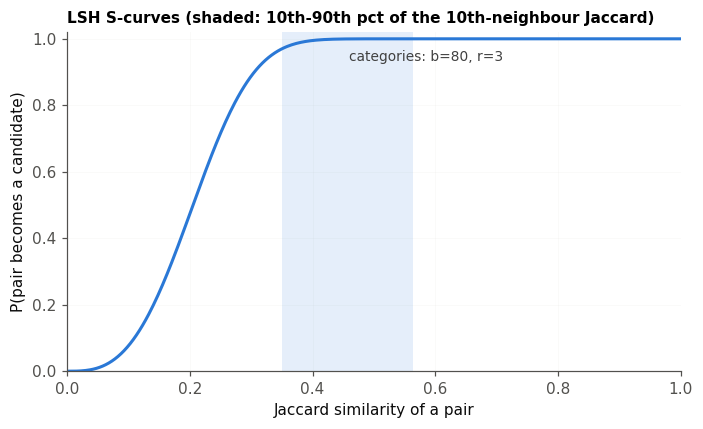

In [47]:
# S-curves of the chosen configurations, with the distribution of the 10th-neighbour Jaccard (figure for the report)
s = np.linspace(0, 1, 400)
colors = {"category": "#2a78d6", "business": "#eb6834"}
names = {"category": "categories", "business": "restaurants"}
fig, ax = plt.subplots(figsize=(6.5, 4))
for v in SETS:
    if CHOSEN[v] == "brute force":
        continue
    b, r = CHOSEN[v]
    ax.plot(s, lsh.s_curve(s, b, r), color=colors[v], lw=2)
    lo, med = KTH[v].quantile(.1), KTH[v].median()
    ax.axvspan(lo, KTH[v].quantile(.9), color=colors[v], alpha=0.12, lw=0)
    ax.annotate(f"{names[v]}: b={b}, r={r}", (med, lsh.s_curve(med, b, r)),
                xytext=(10, -14), textcoords="offset points", fontsize=9, color="0.25")
ax.set_xlabel("Jaccard similarity of a pair")
ax.set_ylabel("P(pair becomes a candidate)")
ax.set_title("LSH S-curves (shaded: 10th-90th pct of the 10th-neighbour Jaccard)", loc="left", fontsize=10)
ax.grid(alpha=0.25, lw=0.5); ax.spines[["top", "right"]].set_visible(False)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
fig.tight_layout(); fig.savefig(FIGURES / "03_lsh_s_curves.png", dpi=150)
plt.show()

### 3.2.3 Save the taste-graph edges

Undirected kNN graph: edge u–v if v is among u's 10 nearest neighbours **or** u among v's. One file per version with the original Yelp ids, plus a JSON with the numbers of 3.1 and 3.2.

In [48]:
EDGES = {}
for v, S in SETS.items():
    d = TRUTH[v] if CHOSEN[v] == "brute force" else FOUND[v][CHOSEN[v]]
    e = lsh.knn_edges(d)
    EDGES[v] = pd.DataFrame({"u": S.user_ids[e["u"].to_numpy()], "v": S.user_ids[e["v"].to_numpy()],
                             "jaccard": e["jaccard"].to_numpy()})
    EDGES[v].to_parquet(RESULTS / f"taste_edges_{v}.parquet", index=False)
    print(f"{v:<9} {len(EDGES[v]):,} edges saved")

def row(v):
    base = {"min_jaccard": round(MIN_J[v], 4), "kth_neighbour_median_j": round(float(KTH[v].median()), 4),
            "n_edges": len(EDGES[v]), "time_brute_force_s": round(T_BRUTE[v], 2)}
    if CHOSEN[v] == "brute force":
        best = SWEEP[v].loc[SWEEP[v]["recall"].idxmax()]
        return {**base, "method": "brute force (LSH recall too low)",
                "best_lsh": f"b={int(best['bands'])}, r={int(best['rows'])}: recall {best['recall']:.2f}"}
    r = SWEEP[v].set_index(["bands", "rows"]).loc[CHOSEN[v]]
    return {**base, "method": "LSH", "bands": CHOSEN[v][0], "rows": CHOSEN[v][1],
            "t_approx": float(r["t_approx"]), "n_candidates": int(r["n_candidates"]),
            "recall": float(r["recall"]), "time_lsh_s": float(r["time_total_s"]),
            "buckets_skipped": int(r["n_buckets_skipped"])}

summary = {"params": {"seed": SEED, "positive": POSITIVE_COL, "generic_max_frac": GENERIC_MAX_FRAC,
                      "max_cats_per_business": MAX_CATS_PER_BUSINESS,
                      "min_businesses_per_category": MIN_BUSINESSES_PER_CATEGORY,
                      "venues_dropped": CAT_INFO["venues_dropped"],
                      "rare_categories_dropped": CAT_INFO["rare_categories_dropped"],
                      "n_hashes": N_HASHES, "k_neighbours": K_NEIGHBOURS,
                      "min_recall": MIN_RECALL, "max_bucket": MAX_BUCKET},
           "user_sets": {v: S.summary() for v, S in SETS.items()},
           "lsh": {v: row(v) for v in SETS}}
(RESULTS / "taste_summary.json").write_text(json.dumps(summary, indent=2, default=str))
pd.DataFrame(summary["lsh"])

business  61,374 edges saved
category  65,063 edges saved


,business,category
min_jaccard,0.0,0.2
kth_neighbour_median_j,0.1,0.4348
n_edges,61374,65063
time_brute_force_s,1.07,2.74
method,brute force (LSH recall too low),LSH
best_lsh,"b=120, r=2: recall 0.82",NaN
bands,NaN,80
rows,NaN,3
t_approx,NaN,0.232
n_candidates,NaN,13297572


## 3.3 Taste-similarity graph and communities

**Graph.** One node per user (all 7,947, as in the friend graph), one edge per kNN pair from 3.2, **weight = Jaccard**. Users without neighbours (empty set) stay as isolated nodes; each becomes its own community and is flagged (`isolated_*`).

**Algorithm.** The Louvain of section 2 (`src/louvain.py`), extended to edge weights (with `weight=None` it gives the same results as before). As in section 2: `N_SEEDS` seeds, the run with the highest modularity is kept, internally disconnected communities are split (`split_disconnected`), and stability between seeds is measured.

In [49]:
# check of the weighted extension: our modularity equals networkx's on a weighted graph
import networkx as nx
K = nx.karate_club_graph()                      # has edge weights
p, _ = louvain.louvain(K, seed=0, weight="weight")
groups = [{u for u in p if p[u] == c} for c in set(p.values())]
print("weighted modularity, ours:", round(louvain.modularity(K, p, weight="weight"), 4),
      " networkx:", round(nx.community.modularity(K, groups, weight="weight"), 4))

weighted modularity, ours: 0.4439  networkx: 0.4439


In [50]:
ALL_USERS = users["user_id"].to_numpy()
G_TASTE, RUNS, PARTS, BEST = {}, {}, {}, {}
for v in SETS:
    G = taste.build_taste_graph(ALL_USERS, EDGES[v])
    G_TASTE[v] = G
    t = time.perf_counter()
    RUNS[v], PARTS[v] = taste.louvain_seeds(G, N_SEEDS, RESOLUTION, weight="weight")
    BEST[v] = int(RUNS[v].loc[RUNS[v]["modularity"].idxmax(), "seed"])
    n_iso = sum(1 for _, d in G.degree() if d == 0)
    n_comp = nx.number_connected_components(G.subgraph([u for u, d in G.degree() if d > 0]))
    print(f"{v:<9} {G.number_of_nodes():,} users, {G.number_of_edges():,} edges, {n_iso} isolated, "
          f"{n_comp} connected components (without isolated) | {N_SEEDS} Louvain runs in {time.perf_counter() - t:.0f} s")

business  7,947 users, 61,374 edges, 6 isolated, 1 connected components (without isolated) | 20 Louvain runs in 14 s


category  7,947 users, 65,063 edges, 8 isolated, 1 connected components (without isolated) | 20 Louvain runs in 22 s


In [51]:
# diagnostic: are the isolated users the ones with small sets? (degree vs set size)
rows = []
for v, S in SETS.items():
    deg = dict(G_TASTE[v].degree())
    d = pd.DataFrame({"size": S.sizes, "degree": [deg[u] for u in S.user_ids]})
    d["size group"] = pd.qcut(d["size"], 4, labels=["Q1 (smallest sets)", "Q2", "Q3", "Q4 (largest sets)"])
    g = d.groupby("size group", observed=True).agg(set_size=("size", "median"), mean_degree=("degree", "mean"),
                                                   isolated=("degree", lambda x: (x == 0).mean()))
    g["version"] = v
    rows.append(g.reset_index())
pd.concat(rows).set_index(["version", "size group"]).round(2)

set_size  mean_degree  isolated
version  size group                                         
business Q1 (smallest sets)       8.0        17.65       0.0
         Q2                      12.0        15.08       0.0
         Q3                      18.0        14.52       0.0
         Q4 (largest sets)       40.0        14.24       0.0
category Q1 (smallest sets)      16.0        13.30       0.0
         Q2                      25.0        14.67       0.0
         Q3                      35.0        16.79       0.0
         Q4 (largest sets)       59.0        21.03       0.0

In [52]:
def describe_runs(v):
    r, best = RUNS[v], RUNS[v].set_index("seed").loc[BEST[v]]
    sizes = pd.Series(PARTS[v][BEST[v]]).value_counts()
    non_iso = [u for u, d in G_TASTE[v].degree() if d > 0]
    stab = taste.pairwise_stability(PARTS[v], non_iso)
    return {"modularity (best run)": round(best["modularity"], 4),
            "modularity (mean ± sd, 20 seeds)": f"{r['modularity'].mean():.3f} ± {r['modularity'].std():.3f}",
            "best seed": BEST[v],
            "communities (best run)": int(best["n_communities"]),
            "communities with >= 50 users": int(best["n_communities_ge_50"]),
            "share of users in 5 largest": f"{best['share_users_in_5_largest']:.0%}",
            "5 largest sizes": " / ".join(str(x) for x in sizes.iloc[:5]),
            "disconnected communities fixed (all runs)": int(r["n_disconnected_fixed"].sum()),
            "runs with a disconnected community": int((r["n_disconnected_fixed"] > 0).sum()),
            "stability ARI mean (min)": f"{stab['ARI_mean']:.2f} ({stab['ARI_min']:.2f})",
            "stability NMI mean (min)": f"{stab['NMI_mean']:.2f} ({stab['NMI_min']:.2f})"}

COMM_SUMMARY = pd.DataFrame({v: describe_runs(v) for v in SETS})
COMM_SUMMARY

,business,category
modularity (best run),0.4508,0.4886
"modularity (mean ± sd, 20 seeds)",0.442 ± 0.004,0.478 ± 0.006
best seed,0,18
communities (best run),17,17
communities with >= 50 users,11,9
share of users in 5 largest,69%,80%
5 largest sizes,1319 / 1198 / 1059 / 1007 / 938,1539 / 1303 / 1248 / 1163 / 1087
disconnected communities fixed (all runs),0,0
runs with a disconnected community,0,0
stability ARI mean (min),0.38 (0.29),0.32 (0.19)


### 3.3.1 Null model

Modularity of Louvain on random graphs with the **same degrees** (and the same edge weights, shuffled), as in section 2.7.

In [53]:
null_q = {}
for v in SETS:
    G = G_TASTE[v]
    qs = []
    for s in range(3):
        R = nx.Graph(nx.configuration_model([d for _, d in G.degree()], seed=s))
        R.remove_edges_from(nx.selfloop_edges(R))
        R = nx.relabel_nodes(R, dict(enumerate(G.nodes())))
        w = np.random.default_rng(s).permutation(EDGES[v]["jaccard"].to_numpy())
        for (a, b), x in zip(R.edges(), w):
            R[a][b]["weight"] = x
        p, _ = louvain.louvain(R, RESOLUTION, seed=s, weight="weight")
        qs.append(louvain.modularity(R, p, RESOLUTION, "weight"))
    null_q[v] = np.mean(qs)
    print(f"{v:<9} modularity: real {RUNS[v]['modularity'].max():.3f}   random graphs with same degrees {null_q[v]:.3f}")

business  modularity: real 0.451   random graphs with same degrees 0.228


category  modularity: real 0.489   random graphs with same degrees 0.201


### 3.3.2 Profile of each taste community

For each community with at least 50 users, the categories that are most **over-represented**: liked by ≥ 25 % of its members, ranked by lift = share in the community / share among all users. The same description is given for the restaurant-based communities (using their members' categories).

In [54]:
pd.set_option("display.max_colwidth", 200)
taste.community_profile(sets_category, PARTS["category"][BEST["category"]], min_size=50)

,community,size,"top categories (share in community, lift)"
0,0,1539,"Japanese (66%, ×1.3); Sushi Bars (58%, ×1.2); Asian Fusion (63%, ×1.1); Chinese (64%, ×1.1); Thai (37%, ×1.0)"
1,1,1303,"Cheesesteaks (37%, ×1.0); Pizza (66%, ×1.0); Delis (34%, ×0.9); Italian (68%, ×0.9); Burgers (43%, ×0.8)"
2,2,1248,"Music Venues (41%, ×2.4); Irish (28%, ×2.3); Arts & Entertainment (57%, ×1.9); Sports Bars (54%, ×1.8); Dive Bars (26%, ×1.8)"
3,3,1163,"Bubble Tea (37%, ×2.9); Taiwanese (28%, ×2.9); Ramen (46%, ×2.6); Cantonese (27%, ×2.6); Shanghainese (28%, ×2.5)"
4,4,1087,"Arts & Crafts (25%, ×3.4); German (33%, ×3.2); Street Vendors (30%, ×3.2); Butcher (25%, ×3.1); Malaysian (25%, ×3.1)"
5,5,855,"Iberian (39%, ×3.1); Tapas Bars (69%, ×3.0); Spanish (64%, ×2.9); Modern European (43%, ×2.3); Cuban (30%, ×1.9)"
6,6,366,"Art Galleries (36%, ×8.6); Seafood Markets (46%, ×7.8); Meat Shops (52%, ×7.1); Museums (36%, ×6.5); Fruits & Veggies (57%, ×6.5)"
7,7,324,"Beer Gardens (58%, ×3.3); Active Life (56%, ×3.0); Grocery (57%, ×2.5); Middle Eastern (69%, ×1.8); Cafes (85%, ×1.4)"
8,8,54,"Kebab (81%, ×27.7); Filipino (80%, ×25.3); Falafel (89%, ×9.1); Tacos (87%, ×5.3); Beer Bar (89%, ×2.8)"


In [55]:
# same description for the restaurant-based communities (described with their members' categories)
taste.community_profile(sets_category, PARTS["business"][BEST["business"]], min_size=50)

,community,size,"top categories (share in community, lift)"
0,0,1319,"Beer Gardens (27%, ×1.5); Active Life (29%, ×1.5); Tapas/Small Plates (49%, ×1.4); Middle Eastern (51%, ×1.4); Wine Bars (60%, ×1.3)"
1,1,1198,"Whiskey Bars (35%, ×2.9); Street Vendors (27%, ×2.9); Cheese Shops (41%, ×2.9); German (29%, ×2.9); Karaoke (28%, ×2.8)"
2,2,1059,"Cheesesteaks (60%, ×1.6); Shopping (28%, ×1.3); Delis (45%, ×1.2); Local Flavor (36%, ×1.1); Bakeries (47%, ×1.0)"
3,3,1007,"Tapas Bars (32%, ×1.4); Lounges (54%, ×1.2); Spanish (27%, ×1.2); French (46%, ×1.2); Latin American (33%, ×1.1)"
4,4,938,"Ramen (28%, ×1.6); Dim Sum (37%, ×1.5); Korean (43%, ×1.4); Vietnamese (48%, ×1.4); Chicken Wings (38%, ×1.4)"
5,5,715,"Music Venues (27%, ×1.6); Arts & Entertainment (42%, ×1.4); Pubs (68%, ×1.3); Gastropubs (60%, ×1.3); Southern (28%, ×1.3)"
6,6,503,"Vegan (42%, ×1.0); Vegetarian (55%, ×1.0); Coffee & Tea (65%, ×0.9); Italian (70%, ×0.9); Pizza (65%, ×0.9)"
7,7,389,"Kosher (27%, ×2.1); Halal (33%, ×1.9); Indian (47%, ×1.7); Vegan (70%, ×1.7); Vegetarian (83%, ×1.5)"
8,8,380,"Breweries (30%, ×1.7); Delis (57%, ×1.6); Beer Bar (41%, ×1.3); Cheesesteaks (49%, ×1.3); Beer (68%, ×1.2)"
9,9,223,"Ethnic Food (55%, ×1.4); Middle Eastern (54%, ×1.4); Vegetarian (62%, ×1.1); Tapas Bars (25%, ×1.1); Specialty Food (68%, ×1.1)"


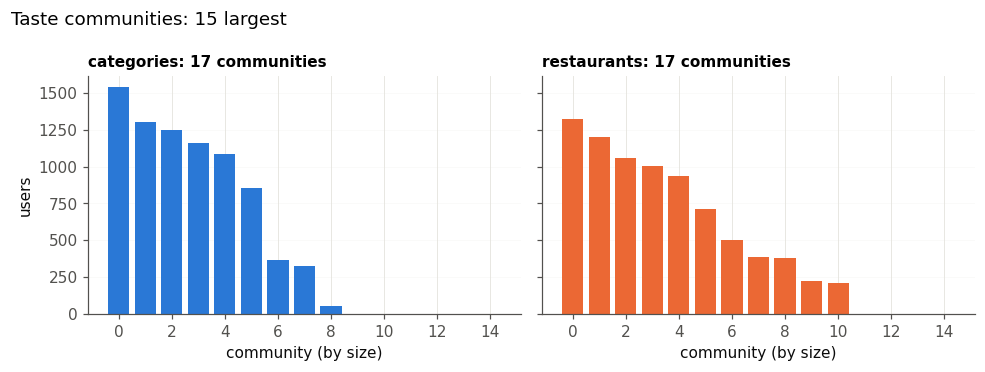

In [56]:
# figure: community sizes of the chosen partitions
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=True)
for ax, v in zip(axes, ["category", "business"]):
    sizes = pd.Series(PARTS[v][BEST[v]]).value_counts().to_numpy()
    top = sizes[:15]
    ax.bar(range(len(top)), top, color=colors[v], width=0.8)
    ax.set_title(f"{names[v]}: {len(sizes)} communities", loc="left", fontsize=10)
    ax.set_xlabel("community (by size)")
    ax.set_xticks(range(0, len(top), 2))
    ax.grid(axis="y", alpha=0.25, lw=0.5); ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("users")
fig.suptitle("Taste communities: 15 largest", x=0.01, ha="left")
fig.tight_layout(); fig.savefig(FIGURES / "03_taste_community_sizes.png", dpi=150)
plt.show()

### 3.3.3 Save the taste communities (contract with section 5)

`data/results/taste_communities.parquet`, one row per user of `philadelphia_pa_users.parquet` (7,947):

| column | meaning |
|---|---|
| `user_id` | original Yelp id |
| `louvain_business`, `louvain_category` | community of the chosen run (0 = largest; labels are arbitrary, compare groupings only) |
| `isolated_business`, `isolated_category` | True if the user has no similar pair (singleton community) |
| `median_year`, `period` | user's median review year and period bin (same bins as section 2), to control for the period-of-activity confounder |

Plus `taste_communities_all_seeds_{business,category}.parquet` (columns `seed_0` … `seed_19`) for the robustness check over the 20 runs, like section 2.

In [57]:
out = pd.DataFrame({"user_id": ALL_USERS})
for v in SETS:
    out[f"louvain_{v}"] = out["user_id"].map(PARTS[v][BEST[v]]).astype("int64")
    deg = dict(G_TASTE[v].degree())
    out[f"isolated_{v}"] = out["user_id"].map(lambda u: deg[u] == 0)
    seeds = pd.DataFrame({"user_id": ALL_USERS})
    for s, p in PARTS[v].items():
        seeds[f"seed_{s}"] = seeds["user_id"].map(p).astype("int64")
    seeds.to_parquet(RESULTS / f"taste_communities_all_seeds_{v}.parquet", index=False)
out = out.merge(period.reset_index(), on="user_id", how="left")
out["period"] = out["period"].astype(str)
out.to_parquet(RESULTS / "taste_communities.parquet", index=False)

summary["communities"] = {v: {**COMM_SUMMARY[v].to_dict(), "modularity_null": round(null_q[v], 4)} for v in SETS}
summary["params"].update({"n_seeds": N_SEEDS, "resolution": RESOLUTION})
(RESULTS / "taste_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(out.shape); out.head()

(7947, 7)


,user_id,louvain_business,isolated_business,louvain_category,isolated_category,median_year,period
0,--pMssoWlOqX0pLiPMiZZw,5,False,0,False,2012.0,2011-13
1,-0vutwuE36iYMqM2wHaStQ,4,False,0,False,2009.0,<=2010
2,-1MF2tosrw2WcCxeVNk81Q,4,False,7,False,2017.0,>=2017
3,-2cKJFFNJ9XVyWBt62mWvA,1,False,6,False,2019.0,>=2017
4,-33OBttPeyt_pUozPxkFEg,7,False,3,False,2019.0,>=2017


## 3.4 Summary

| | Categories | Restaurants |
|---|---|---|
| Items (after the filters) | 196 | 5,414 |
| Liked items per user (mean / median) | 34.9 / 29 | 22.0 / 14 |
| Jaccard of the 10th nearest neighbour (median) vs random pairs | 0.43 vs 0.19 | 0.10 vs 0.00 |
| Nearest neighbours found with | LSH, b = 80, r = 3 (recall 99.4 %) | brute force (best LSH recall 0.82) |
| Modularity, chosen run (random graphs) | 0.489 (0.201) | 0.451 (0.228) |
| Communities, chosen run | 17 = 9 + 8 isolated | 17 = 11 + 6 isolated |
| Communities with ≥ 50 users / share of users in the 5 largest | 9 / 80 % | 11 / 69 % |
| Stability between seeds, ARI mean (min) | 0.32 (0.19) | 0.38 (0.29) |

# 4. Frequent itemsets and association rules (A-priori vs. PCY)

*Code: `src/itemsets.py` (A-priori, PCY), `src/rules.py` (rules, comparison, null model), `src/benchmark.py` (runtime and memory). Tests: `tests/`.*

**Plan**
- **4.1** Baskets: restaurants liked, and categories of restaurants liked.
- **4.2** A-priori and PCY from scratch, and a check that they give identical results.
- **4.3** A-priori vs. PCY: runtime, memory, candidate pairs.
- **4.4** Association rules per community, for 3 community systems × 2 basket types.
- **4.5** Comparison of the rules across systems, against a null model, with the activity-period partition.
- **4.6** Robustness over the 20 saved Louvain seeds.
- **4.7** Saved outputs.
- **4.8** Summary.

## 4.0 Parameters

Inputs are the files written by sections 1–3; no community is re-detected. The baskets use the category filter of section 3 (set in 0.2).

In [58]:
import benchmark as BM, itemsets as I, rules as R, taste   # project modules (src/)

# ---------------- Parameters (category filter: see 0.2) ----------------
MIN_BASKET_ITEMS = 2              # skip baskets that cannot contain a pair

# mining (one support / confidence per basket type, the same for every community system)
MIN_SUPPORT = {"business": 0.01, "category": 0.15}
MIN_CONFIDENCE = {"business": 0.25, "category": 0.50}
MIN_LIFT = 1.0                    # keep only positively associated rules
MAX_K = 3                         # largest itemset size
MIN_COUNT_FLOOR = 5               # min_count = max(ceil(min_support * n), 5)
MIN_COMMUNITY_SIZE = 100          # mining transactions needed to mine a community

# comparison
LIFT_RATIO_MIN = 1.5              # "community-specific" rule: lift >= 1.5 x population lift
TAG_SHARE_MAX = 0.5               # category rule flagged as a Yelp-tag artefact above this share
N_SHUFFLES = 20                   # null model: random partitions with the same sizes

# A-priori vs PCY
N_BUCKETS = 100_003               # prime; ~4x the number of distinct category pairs seen
BUCKET_SWEEP = (1_009, 10_007, 100_003, 1_000_003)
TIMING_REPS = 5

VERSIONS = ("business", "category")

## 4.1 Baskets

One basket per user. Items are either the **restaurants** the user liked or the **categories** of those restaurants ("liked" = `is_positive`, section 1.5.1).

The baskets are the liked sets of section 3 (`taste.build_user_sets` with the same parameters). The category filter removes:
- categories liked by more than 80% of users;
- categories present in fewer than 5 restaurants;
- the one venue with more than 20 categories (Reading Terminal Market).

Users with fewer than `MIN_BASKET_ITEMS` = 2 items are not mining transactions (they cannot contain a pair). They stay in the community files and are simply absent when a community's baskets are collected.

In [59]:
reviews, businesses, users = taste.load_inputs(ROOT)
friend = pd.read_parquet(DATA_PROCESSED / "philadelphia_pa_friend_communities.parquet").set_index("user_id")["friend_community"]
taste_c = pd.read_parquet(RESULTS / "taste_communities.parquet").set_index("user_id")
ALL_USERS = users["user_id"]

# every community file must describe the same population
for name, idx in [("friend", friend.index), ("taste", taste_c.index)]:
    assert set(idx) == set(ALL_USERS) and idx.is_unique, f"{name} population differs"
assert reviews.duplicated(["user_id", "business_id"]).sum() == 0, "duplicate user-restaurant pairs"
assert reviews[["user_id", "business_id"]].notna().all().all(), "missing ids"

USER_SETS, BASKETS = {}, {}
for v in VERSIONS:
    USER_SETS[v] = taste.build_user_sets(reviews, businesses, users, v,
                                         generic_max_frac=GENERIC_MAX_FRAC,
                                         max_cats_per_business=MAX_CATS_PER_BUSINESS,
                                         min_businesses_per_category=MIN_BUSINESSES_PER_CATEGORY)
    BASKETS[v] = I.baskets_from_user_sets(USER_SETS[v], ALL_USERS, MIN_BASKET_ITEMS)

cat_long, cat_info = taste.clean_business_categories(businesses, MAX_CATS_PER_BUSINESS, MIN_BUSINESSES_PER_CATEGORY)
basket_summary = pd.DataFrame([{
    "basket_type": v, "users": len(ALL_USERS), "users_empty": len(USER_SETS[v].empty_users),
    "users_excluded_lt2": len(BASKETS[v].excluded_users), "mining_transactions": len(BASKETS[v].sets),
    "unique_items": BASKETS[v].n_items,
    "size_median": float(np.median([len(s) for s in BASKETS[v].sets])),
    "size_mean": round(float(np.mean([len(s) for s in BASKETS[v].sets])), 1),
    "size_p90": float(np.percentile([len(s) for s in BASKETS[v].sets], 90)),
    "size_max": int(max(len(s) for s in BASKETS[v].sets))} for v in VERSIONS])
display(basket_summary)
print("generic categories dropped:", USER_SETS["category"].dropped_items)
print("venues dropped from the category version:", cat_info["venues_dropped"])
print("rare categories dropped:", cat_info["rare_categories_dropped"])

,basket_type,users,users_empty,users_excluded_lt2,mining_transactions,unique_items,size_median,size_mean,size_p90,size_max
0,business,7947,6,16,7931,5414,14.0,22.0,45.0,542
1,category,7947,6,9,7938,196,29.0,34.9,64.0,157


generic categories dropped: {'Food': 0.966, 'Nightlife': 0.939, 'Bars': 0.933, 'American (New)': 0.902, 'Breakfast & Brunch': 0.88, 'American (Traditional)': 0.832, 'Sandwiches': 0.828}
venues dropped from the category version: {'Reading Terminal Market': 35}
rare categories dropped: 170


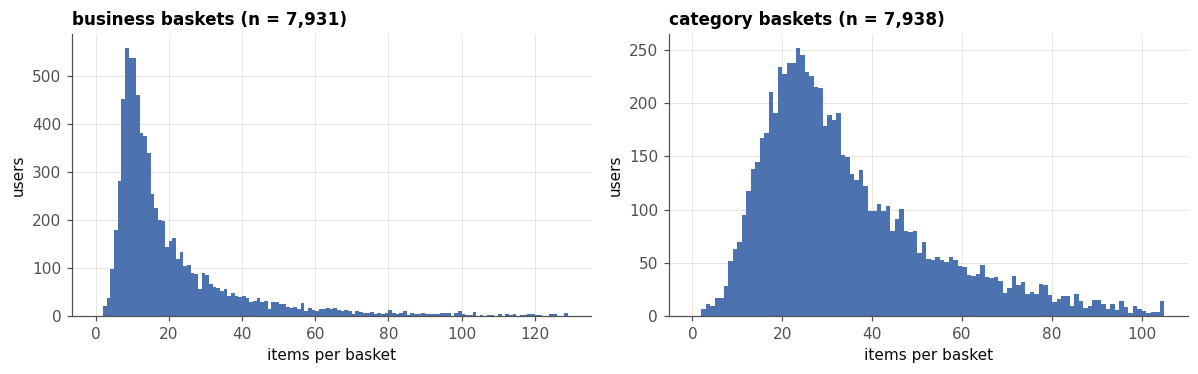

In [60]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for ax, v in zip(axes, VERSIONS):
    sizes = [len(s) for s in BASKETS[v].sets]
    ax.hist(sizes, bins=np.arange(0, np.percentile(sizes, 99) + 2), color="#4c72b0")
    ax.set(title=f"{v} baskets (n = {len(sizes):,})", xlabel="items per basket", ylabel="users")
fig.tight_layout(); fig.savefig(FIGURES / "04_basket_sizes.png", dpi=150); plt.show()

In [61]:
# lookup tables: readable item names, and the business -> category table for the tag check
NAMES = {"business": businesses.set_index("business_id")["name"].reindex(BASKETS["business"].item_ids).to_numpy(),
         "category": BASKETS["category"].item_ids}
cat_index = pd.Series(np.arange(BASKETS["category"].n_items), index=BASKETS["category"].item_ids)
biz_rows = (cat_long[cat_long.category.isin(cat_index.index)]
            .assign(i=lambda d: cat_index.reindex(d.category).to_numpy())
            .groupby("business_id")["i"].apply(lambda s: np.sort(s.to_numpy())))
BIZ_INDEX = R.SupportIndex(list(biz_rows), BASKETS["category"].n_items)
POP = {v: R.SupportIndex(list(BASKETS[v].sets), BASKETS[v].n_items) for v in VERSIONS}
print(f"business-category table: {BIZ_INDEX.n:,} restaurants")

business-category table: 5,478 restaurants


## 4.2 A-priori and PCY

Both are written from scratch in `src/itemsets.py`. Items are integer indices and itemsets are sorted tuples, so outputs are deterministic and can be compared exactly.

**A-priori**
1. Pass 1 counts every item.
2. Pass 2 counts pairs of frequent items in a **triangular array** of m(m−1)/2 counters, m = number of frequent items.
3. Sizes k ≥ 3 join frequent (k−1)-itemsets that share their first k−2 items, prune every candidate with an infrequent (k−1)-subset, and count the survivors against the transactions.

**PCY**
1. Pass 1 also hashes every pair of every basket into `N_BUCKETS` counters. The pair is packed into a 64-bit key (i << 32 | j), scrambled with the fixed MurmurHash3 finaliser, and reduced modulo `N_BUCKETS` (Python's salted `hash()` is not used, so results are reproducible).
2. The bucket counts become a **bitmap** (1 bit per bucket, `np.packbits`) and the counter array is freed.
3. Pass 2 counts, in a **hash table** (dict), only pairs of frequent items whose bucket is frequent.
4. Sizes k ≥ 3 use the same A-priori extension as above.

A collision can only make a bucket *look* frequent (a false positive), never hide a frequent pair. The bitmap is a filter, and exact supports are always counted afterwards.

**Support threshold.** `min_count = max(ceil(min_support × n), 5)` for each collection of n transactions.

The first cell runs the unit tests in `tests/`; the second runs both algorithms on the full population and asserts that they return identical itemsets.

In [62]:
# unit tests: toy data with known answers, brute-force agreement, edge cases, forced collisions
out = subprocess.run([sys.executable, "-m", "pytest", "-q", str(ROOT / "tests")], capture_output=True, text=True, cwd=ROOT)
print(out.stdout.strip().splitlines()[-1])

63 passed, 1 warning in 3.53s


In [63]:
# the two algorithms on the full population: identical itemsets?
FULL = {}
for v in VERSIONS:
    T = list(BASKETS[v].sets)
    mc = I.min_support_count(MIN_SUPPORT[v], len(T), MIN_COUNT_FLOOR)
    a = I.apriori(T, BASKETS[v].n_items, mc, MAX_K)
    p = I.pcy(T, BASKETS[v].n_items, mc, N_BUCKETS, MAX_K)
    assert a.itemsets == p.itemsets, f"{v}: A-priori and PCY disagree"
    FULL[v] = a
    print(f"{v:<9} min_support {MIN_SUPPORT[v]:.0%} -> min_count {mc}: identical itemsets, by size {a.by_size()}")

business  min_support 1% -> min_count 80: identical itemsets, by size {1: 579, 2: 293, 3: 7}


category  min_support 15% -> min_count 1191: identical itemsets, by size {1: 80, 2: 1390, 3: 9568}


## 4.3 A-priori vs. PCY: runtime, memory, candidate pairs

Both algorithms run on **identical** inputs: the same transactions, item encoding and min_count. The benchmark covers the **pair stage** (`max_k = 2`), where the two algorithms differ; the k ≥ 3 stage is the same code for both. The inputs are the full population and the largest eligible community of each system, for both basket types.

- **Runtime:** median of `TIMING_REPS` runs, timed per pass with `time.perf_counter` inside the algorithms. Loading, plotting and rule generation are excluded.
- **Memory:** one extra run under `tracemalloc` (peak Python allocation; NumPy arrays are included because NumPy allocates through Python's tracer). Next to it, the theoretical size of each structure: 4 bytes per counter and 12 bytes per hash-table entry.
- **Candidate pairs:** separate, defined counts (table below).

`benchmark.benchmark` stops with an error if the two algorithms ever disagree.

In [64]:
def largest_eligible(labels, v):
    for c in labels.value_counts().index:
        if len(BASKETS[v].subset(labels[labels == c].index)) >= MIN_COMMUNITY_SIZE:
            return c

SYSTEMS = {"friend": friend, "taste_business": taste_c["louvain_business"], "taste_category": taste_c["louvain_category"]}
bench_rows, cand_rows = [], []
for v in VERSIONS:
    colls = {"population": list(BASKETS[v].sets)}
    for s, lab in SYSTEMS.items():
        c = largest_eligible(lab, v)
        colls[f"{s} #{c}"] = BASKETS[v].subset(lab[lab == c].index)
    for name, T in colls.items():
        mc = I.min_support_count(MIN_SUPPORT[v], len(T), MIN_COUNT_FLOOR)
        rows, cand = BM.benchmark(T, BASKETS[v].n_items, mc, 2, N_BUCKETS, TIMING_REPS)
        bench_rows.append(rows.assign(basket_type=v, collection=name))
        cand_rows.append({"basket_type": v, "collection": name, "n_transactions": len(T), "min_count": mc, **cand})
BENCH = pd.concat(bench_rows, ignore_index=True)
CAND = pd.DataFrame(cand_rows)
cols = ["basket_type", "collection", "algorithm", "n_transactions", "min_count", "pass1_s", "pass2_pairs_s", "total_s", "total_s_min", "total_s_max", "peak_mem_mb"]
display(BENCH[cols].round(3))

,basket_type,collection,algorithm,n_transactions,min_count,pass1_s,pass2_pairs_s,total_s,total_s_min,total_s_max,peak_mem_mb
0,business,population,apriori,7931,80,0.001,0.117,0.118,0.118,0.121,2.601
1,business,population,pcy,7931,80,0.296,0.161,0.457,0.455,0.459,10.037
2,business,friend #0,apriori,2456,25,0.000,0.053,0.054,0.054,0.054,4.106
3,business,friend #0,pcy,2456,25,0.121,0.078,0.200,0.197,0.201,10.436
4,business,taste_business #0,apriori,1318,14,0.000,0.013,0.013,0.013,0.014,1.178
5,business,taste_business #0,pcy,1318,14,0.025,0.023,0.047,0.047,0.048,2.929
6,business,taste_category #0,apriori,1534,16,0.000,0.007,0.007,0.007,0.007,0.258
7,business,taste_category #0,pcy,1534,16,0.016,0.018,0.034,0.033,0.034,1.094
8,category,population,apriori,7938,1191,0.001,0.248,0.250,0.249,0.252,4.338
9,category,population,pcy,7938,1191,0.395,0.347,0.740,0.737,0.748,10.447


In [65]:
cand_cols = ["basket_type", "collection", "pairs_hashed_pass1", "nonempty_buckets", "frequent_buckets",
             "frequent_items", "apriori_candidate_pairs", "pcy_candidate_pairs", "removed_by_bitmap",
             "candidate_reduction_pct", "pcy_pairs_counted", "frequent_pairs"]
display(CAND[cand_cols].round(1))
mem_cols = ["basket_type", "collection", "triangular_bytes", "bucket_array_bytes", "bitmap_bytes", "hash_table_bytes_course"]
display((CAND[mem_cols].set_index(["basket_type", "collection"]) / 1024).round(1).add_suffix(" [KB]"))

,basket_type,collection,pairs_hashed_pass1,nonempty_buckets,frequent_buckets,frequent_items,apriori_candidate_pairs,pcy_candidate_pairs,removed_by_bitmap,candidate_reduction_pct,pcy_pairs_counted,frequent_pairs
0,business,population,4521167,100003,5463,579,167331,18634,148697,88.9,18405,293
1,business,friend #0,1895174,100001,21094,717,256686,82289,174397,67.9,72048,964
2,business,taste_business #0,279864,86283,906,429,91806,1990,89816,97.8,1565,489
3,business,taste_category #0,79595,51070,2,180,16110,3,16107,100.0,2,1
4,category,population,6393958,17306,1455,80,3160,1505,1655,52.4,1505,1390
5,category,friend #0,2445929,17190,1987,86,3655,2041,1614,44.2,2041,1919
6,category,taste_business #0,920100,15586,1327,74,2701,1362,1339,49.6,1362,1294
7,category,taste_category #0,316681,11964,211,47,1081,215,866,80.1,215,204


triangular_bytes [KB]  bucket_array_bytes [KB]  bitmap_bytes [KB]  hash_table_bytes_course [KB]
basket_type collection                                                                                                        
business    population                         653.6                    390.6               12.2                         215.7
            friend #0                         1002.7                    390.6               12.2                         844.3
            taste_business #0                  358.6                    390.6               12.2                          18.3
            taste_category #0                   62.9                    390.6               12.2                           0.0
category    population                          12.3                    390.6               12.2                          17.6
            friend #0                           14.3                    390.6               12.2                          23.9
            taste_business #0                   10.6                    390.6               12.2                          16.0
            taste_category #0                    4.2                    390.6               12.2                           2.5

**What the candidate-pair columns mean**

| Column | Definition |
|---|---|
| `pairs_hashed_pass1` | pair occurrences hashed by PCY in pass 1 (every pair of every basket) |
| `nonempty_buckets`, `frequent_buckets` | buckets with count > 0, and with count ≥ min_count |
| `apriori_candidate_pairs` | all pairs of frequent items, m(m−1)/2: what A-priori allocates and counts |
| `pcy_candidate_pairs` | pairs of frequent items whose bucket is frequent: PCY's candidate set |
| `removed_by_bitmap` | the difference; `candidate_reduction_pct` is it as a percentage |
| `pcy_pairs_counted` | candidates that actually occur in a basket, i.e. the hash-table entries |
| `frequent_pairs` | pairs with support ≥ min_count (identical for both algorithms) |

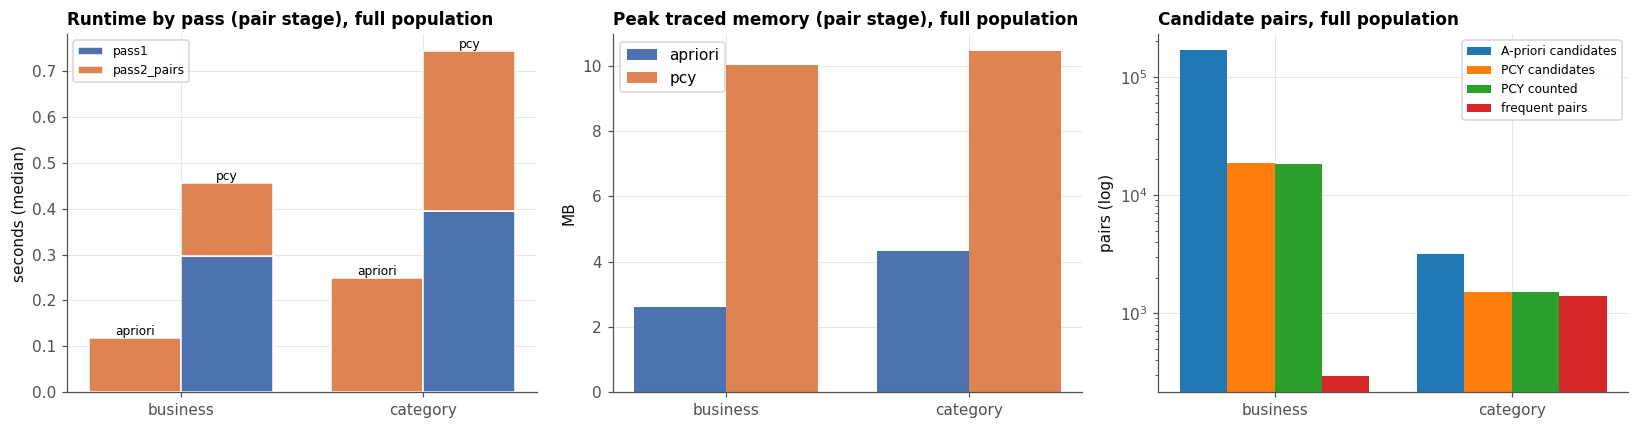

In [66]:
pop_b = BENCH[BENCH.collection == "population"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
w = 0.38
for k, v in enumerate(VERSIONS):
    for j, algo in enumerate(("apriori", "pcy")):
        r = pop_b[(pop_b.basket_type == v) & (pop_b.algorithm == algo)].iloc[0]
        bottom = 0
        for part, col in [("pass1_s", "#4c72b0"), ("pass2_pairs_s", "#dd8452")]:
            axes[0].bar(k + (j - .5) * w, r[part], w, bottom=bottom, color=col,
                        label=part.replace("_s", "") if (k, j) == (0, 0) else None, edgecolor="white")
            bottom += r[part]
        axes[0].text(k + (j - .5) * w, bottom, algo, ha="center", va="bottom", fontsize=8)
        axes[1].bar(k + (j - .5) * w, r.peak_mem_mb, w, color=["#4c72b0", "#dd8452"][j], label=algo if k == 0 else None)
axes[0].set(xticks=range(2), xticklabels=VERSIONS, ylabel="seconds (median)", title="Runtime by pass (pair stage), full population"); axes[0].legend(fontsize=8)
axes[1].set(xticks=range(2), xticklabels=VERSIONS, ylabel="MB", title="Peak traced memory (pair stage), full population"); axes[1].legend()
cp = CAND[CAND.collection == "population"].set_index("basket_type")
x = np.arange(2)
for j, (col, lab) in enumerate([("apriori_candidate_pairs", "A-priori candidates"), ("pcy_candidate_pairs", "PCY candidates"),
                                ("pcy_pairs_counted", "PCY counted"), ("frequent_pairs", "frequent pairs")]):
    axes[2].bar(x + (j - 1.5) * 0.2, cp.loc[list(VERSIONS), col], 0.2, label=lab)
axes[2].set(xticks=x, xticklabels=VERSIONS, yscale="log", ylabel="pairs (log)", title="Candidate pairs, full population"); axes[2].legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "04_apriori_vs_pcy.png", dpi=150); plt.show()

,n_buckets,frequent_buckets,share_frequent_buckets,pcy_candidate_pairs,candidate_reduction_pct,pcy_pairs_counted,bucket_array_kb,bitmap_kb,hash_table_kb_course,peak_mem_mb,pass1_s,pass2_s,basket_type
0,1009,1009,1.000,167331,0.000,163030,3.941,0.124,1910.508,15.735,0.320,0.303,business
1,10007,10007,1.000,167331,0.000,163030,39.090,1.222,1910.508,15.736,0.293,0.253,business
2,100003,5463,0.055,18634,88.864,18405,390.637,12.208,215.684,10.037,0.300,0.160,business
3,1000003,387,0.000,480,99.713,477,3906.262,122.071,5.590,13.471,0.313,0.138,business
4,1009,1002,0.993,3159,0.032,3159,3.941,0.124,37.020,14.556,0.392,0.402,category
5,10007,1828,0.183,2204,30.253,2204,39.090,1.222,25.828,11.975,0.394,0.389,category
6,100003,1455,0.015,1505,52.373,1505,390.637,12.208,17.637,10.447,0.391,0.345,category
7,1000003,1398,0.001,1403,55.601,1403,3906.262,122.071,16.441,13.880,0.396,0.341,category


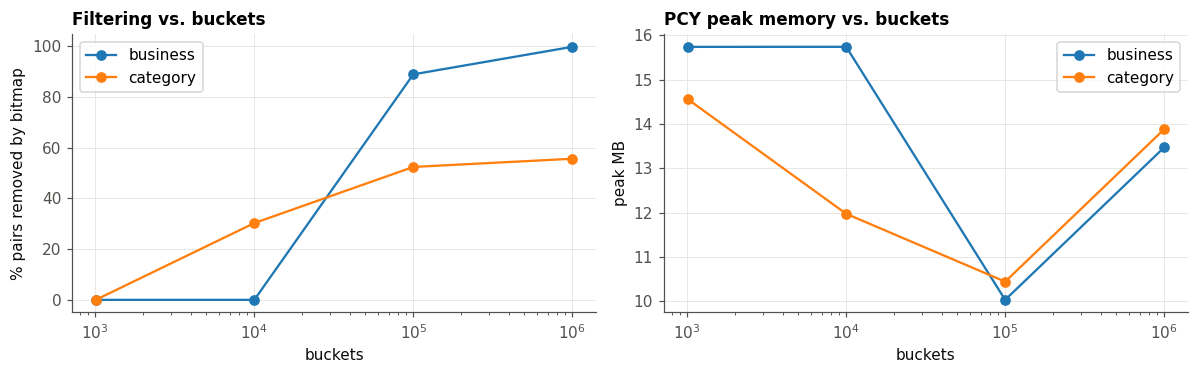

In [67]:
# effect of the number of buckets (pairs only, full population)
SWEEP = pd.concat([BM.bucket_sweep(list(BASKETS[v].sets), BASKETS[v].n_items,
                                   I.min_support_count(MIN_SUPPORT[v], len(BASKETS[v].sets), MIN_COUNT_FLOOR),
                                   BUCKET_SWEEP).assign(basket_type=v) for v in VERSIONS], ignore_index=True)
display(SWEEP.round(3))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for v in VERSIONS:
    s = SWEEP[SWEEP.basket_type == v]
    axes[0].plot(s.n_buckets, s.candidate_reduction_pct, "o-", label=v)
    axes[1].plot(s.n_buckets, s.peak_mem_mb, "o-", label=v)
axes[0].set(xscale="log", xlabel="buckets", ylabel="% pairs removed by bitmap", title="Filtering vs. buckets")
axes[1].set(xscale="log", xlabel="buckets", ylabel="peak MB", title="PCY peak memory vs. buckets")
for a in axes: a.legend()
fig.tight_layout(); fig.savefig(FIGURES / "04_pcy_bucket_sweep.png", dpi=150); plt.show()

## 4.4 Association rules per community

For a rule X → Y (X, Y non-empty and disjoint, X ∪ Y frequent):

$$\text{support} = \frac{s(X\cup Y)}{n},\qquad \text{confidence} = \frac{s(X\cup Y)}{s(X)},\qquad \text{lift} = \frac{\text{confidence}}{s(Y)/n}$$

All of these use the exact counts from mining. A rule describes **co-occurrence among liked items**, not causation.

**Two extra columns per rule**
- **`lift_pop`, `lift_ratio`**: the same rule's lift on the whole population, and lift in the community ÷ lift in the population. A rule is **community-specific** when `lift_ratio ≥ 1.5`.
- **`same_business_share`** (category rules only): the share of restaurants tagged with all of X that are also tagged with all of Y. Rules above 0.5 are flagged as Yelp-tag artefacts (e.g. *Sushi Bars → Japanese*).

**Thresholds** (4.0): one support and one confidence per basket type, the same for all three community systems: support 1 % / 15 % and confidence 0.25 / 0.50 (restaurants / categories), lift > 1. Communities with fewer than `MIN_COMMUNITY_SIZE` = 100 mining transactions (including the singleton communities of isolated users) are listed as excluded. Communities are mined with A-priori.

In [68]:
SYSTEMS_ALL = {**SYSTEMS, "period": taste_c["period"].astype(str)}   # period: confounder check (4.5)

def params(v, max_k=MAX_K):
    return R.MiningParams(MIN_SUPPORT[v], MIN_CONFIDENCE[v], MIN_LIFT, max_k, MIN_COUNT_FLOOR,
                          MIN_COMMUNITY_SIZE, LIFT_RATIO_MIN)

SUMMARY, RULES = {}, {}
t0 = time.perf_counter()
for v in VERSIONS:
    for s, lab in SYSTEMS_ALL.items():
        SUMMARY[s, v], RULES[s, v] = R.mine_partition(BASKETS[v], lab, params(v), POP[v],
                                                      BIZ_INDEX if v == "category" else None)
print(f"mined 4 systems x 2 basket types in {time.perf_counter() - t0:.0f} s")

comm = pd.concat([d.assign(community_system=s, basket_type=v) for (s, v), d in SUMMARY.items()], ignore_index=True)
excl = (comm.groupby(["community_system", "basket_type"])
            .agg(communities=("community_id", "size"), eligible=("eligible", "sum"),
                 users_in_eligible=("n_assigned", lambda x: int(x[comm.loc[x.index, "eligible"]].sum())))
            .assign(excluded=lambda d: d.communities - d.eligible))
display(excl)

mined 4 systems x 2 basket types in 34 s


communities  eligible  users_in_eligible  excluded
community_system basket_type                                                    
friend           business              51         7               7532        44
                 category              51         7               7532        44
period           business               4         4               7947         0
                 category               4         4               7947         0
taste_business   business              17        11               7941         6
                 category              17        11               7941         6
taste_category   business              17         8               7885         9
                 category              17         8               7885         9

In [69]:
show = ["community_system", "basket_type", "community_id", "n_assigned", "n_transactions", "n_items", "min_count",
        "frequent_k1", "frequent_k2", "frequent_k3", "rules_before_filter", "rules", "rules_specific"]
display(comm[comm.eligible & (comm.community_system != "period")][show])

,community_system,basket_type,community_id,n_assigned,n_transactions,n_items,min_count,frequent_k1,frequent_k2,frequent_k3,rules_before_filter,rules,rules_specific
0,friend,business,0,2460,2456,4372.0,25.0,717.0,964.0,124.0,2672.0,894.0,0.0
1,friend,business,1,1667,1664,3606.0,17.0,532.0,345.0,0.0,690.0,136.0,7.0
2,friend,business,2,1607,1606,3944.0,17.0,694.0,1997.0,300.0,5794.0,2193.0,64.0
3,friend,business,3,818,818,2623.0,9.0,500.0,744.0,86.0,2004.0,732.0,115.0
4,friend,business,4,661,661,1932.0,7.0,336.0,216.0,18.0,540.0,179.0,17.0
5,friend,business,5,196,195,1374.0,5.0,125.0,5.0,0.0,10.0,8.0,4.0
6,friend,business,6,123,122,1092.0,5.0,45.0,0.0,0.0,0.0,0.0,0.0
51,taste_business,business,0,1319,1318,3054.0,14.0,429.0,489.0,67.0,1380.0,413.0,1.0
52,taste_business,business,1,1198,1198,4440.0,12.0,1443.0,29380.0,41199.0,305954.0,114483.0,2.0
53,taste_business,business,2,1059,1057,3077.0,11.0,261.0,151.0,19.0,416.0,152.0,1.0


In [70]:
def readable(rules, v):
    n = NAMES[v]
    fmt = lambda t: " + ".join(str(n[i]) for i in t)
    return rules.assign(rule=[f"{fmt(a)} → {fmt(c)}" for a, c in zip(rules.antecedent, rules.consequent)])

def top_rules(s, v, k=3, specific=True):
    r = RULES[s, v]
    r = r[r.specific] if specific else r
    if v == "category":
        r = r[~(r.same_business_share >= TAG_SHARE_MAX)]
    r = r.sort_values(["community_id", "lift_ratio", "lift"], ascending=[True, False, False]).groupby("community_id").head(k)
    cols = ["community_id", "rule", "support", "confidence", "lift", "lift_pop", "lift_ratio"]
    return readable(r, v)[cols].round(3)

for v in VERSIONS:
    for s in SYSTEMS:
        print(f"\n=== {s} x {v}: top community-specific rules (max 3 per community{', tag rules removed' if v == 'category' else ''})")
        display(top_rules(s, v))


=== friend x business: top community-specific rules (max 3 per community)


,community_id,rule,support,confidence,lift,lift_pop,lift_ratio
953,1,Sang Kee Peking Duck House → Amada,0.010,0.309,3.475,1.728,2.012
993,1,North Bowl → Reading Terminal Market,0.014,0.291,2.850,1.606,1.774
941,1,New Delhi Indian Restaurant → Reading Terminal Market,0.010,0.386,3.782,2.189,1.727
1124,2,Bud & Marilyn's → Dizengoff,0.011,0.288,7.230,3.263,2.216
1125,2,Dizengoff → Bud & Marilyn's,0.011,0.266,7.230,3.263,2.216
1257,2,Jong Ka Jib → Cafe La Maude,0.011,0.383,6.030,2.951,2.044
3285,3,Tria Cafe Wash West → Little Nonna's,0.012,0.385,7.317,2.474,2.958
3296,3,Nan Zhou Hand Drawn Noodle House + Oyster House → El Vez,0.012,0.500,7.175,2.661,2.696
3572,3,Sabrina's Café → Reading Terminal Market,0.011,0.391,3.679,1.424,2.584
3957,4,Tom's Dim Sum → Terakawa Ramen,0.011,0.700,15.955,4.720,3.380



=== taste_business x business: top community-specific rules (max 3 per community)


,community_id,rule,support,confidence,lift,lift_pop,lift_ratio
37,0,Pat's King of Steaks → Zahav,0.012,0.593,2.675,1.233,2.169
37765,1,Lucky's Last Chance → Fogo de Chao,0.010,0.333,2.894,1.741,1.662
52002,1,Lloyd Whiskey Bar → Reading Terminal Market,0.012,0.636,2.584,1.611,1.604
114902,2,Barbuzzo → Monk's Cafe,0.012,0.295,4.056,2.230,1.819
115078,4,Steve's Prince of Steaks → Reading Terminal Market,0.013,0.293,4.419,1.757,2.515
115093,4,Zahav → Nan Zhou Hand Drawn Noodle House,0.014,0.433,2.982,1.780,1.676
115103,4,The Dandelion → Nan Zhou Hand Drawn Noodle House,0.012,0.379,2.611,1.650,1.583
115206,5,Dalessandro’s Steaks & Hoagies → Standard Tap,0.011,0.400,4.333,1.631,2.657
115143,5,Stock → Zahav,0.011,0.320,6.729,2.768,2.431
115182,5,Nan Zhou Hand Drawn Noodle House → Cafe La Maude,0.013,0.692,4.901,2.129,2.302



=== taste_category x business: top community-specific rules (max 3 per community)


,community_id,rule,support,confidence,lift,lift_pop,lift_ratio
1,1,Tommy DiNic's → Beiler's Bakery,0.013,0.293,6.923,3.783,1.830
0,1,Beiler's Bakery → Tommy DiNic's,0.013,0.309,6.923,3.783,1.830
6,1,John's Roast Pork → Reading Terminal Market,0.018,0.377,2.915,1.765,1.652
29,2,Morimoto → Reading Terminal Market,0.010,0.394,2.793,1.565,1.785
54,3,Osteria → Zahav,0.010,0.545,4.146,2.692,1.540
147110,5,Gran Caffe L'Aquila → Reading Terminal Market,0.012,0.357,2.801,1.538,1.821
147075,5,Estia → Max Brenner - Philadelphia,0.011,0.250,4.548,2.569,1.770
147072,5,Hawthornes Biercafé → Little Fish,0.011,0.250,5.625,3.241,1.736
147357,6,Vernick Food & Drink → HipCityVeg,0.014,0.417,8.472,2.359,3.591
147358,6,HipCityVeg → Vernick Food & Drink,0.014,0.278,8.472,2.359,3.591


... (2 outputs left out)


=== taste_business x category: top community-specific rules (max 3 per community, tag rules removed)


,community_id,rule,support,confidence,lift,lift_pop,lift_ratio
509687,4,Beer → Event Planning & Services + Wine & Spirits,0.175,0.524,2.997,1.813,1.653
509688,4,Wine & Spirits → Beer + Event Planning & Services,0.175,0.524,2.997,1.813,1.653
509689,4,Beer → Vegetarian + Wine & Spirits,0.170,0.508,2.997,1.813,1.653
527685,6,Pizza + Sushi Bars → Japanese,0.169,0.867,2.607,1.716,1.519
527686,6,Japanese → Pizza + Sushi Bars,0.169,0.509,2.607,1.716,1.519
527684,6,Sushi Bars + Vegetarian → Japanese,0.157,0.868,2.610,1.726,1.512
548458,8,Specialty Food + Vegetarian → Ethnic Food,0.164,0.626,2.887,1.790,1.613
548459,8,Ethnic Food → Specialty Food + Vegetarian,0.164,0.756,2.887,1.790,1.613
548462,8,Ethnic Food → Chinese + Specialty Food,0.156,0.720,2.720,1.783,1.525
564006,9,Caterers → Event Planning & Services + Vegetarian,0.175,0.867,3.514,1.948,1.804



=== taste_category x category: top community-specific rules (max 3 per community, tag rules removed)


,community_id,rule,support,confidence,lift,lift_pop,lift_ratio
4,0,Beer → Japanese + Wine & Spirits,0.160,0.746,4.650,1.813,2.565
5,0,Wine & Spirits → Beer + Japanese,0.160,0.746,4.650,1.813,2.565
13,0,Specialty Food → Ethnic Food,0.192,0.567,2.948,1.573,1.874
511,1,Ethnic Food → Specialty Food + Vegetarian,0.167,0.753,3.044,1.790,1.701
512,1,Specialty Food + Vegetarian → Ethnic Food,0.167,0.674,3.044,1.790,1.701
642256,6,Japanese → Sushi Bars + Wine Bars,0.189,0.590,2.767,1.741,1.589
642257,6,Sushi Bars + Wine Bars → Japanese,0.189,0.885,2.767,1.741,1.589
642268,6,Japanese → Salad + Sushi Bars,0.189,0.590,2.732,1.730,1.579


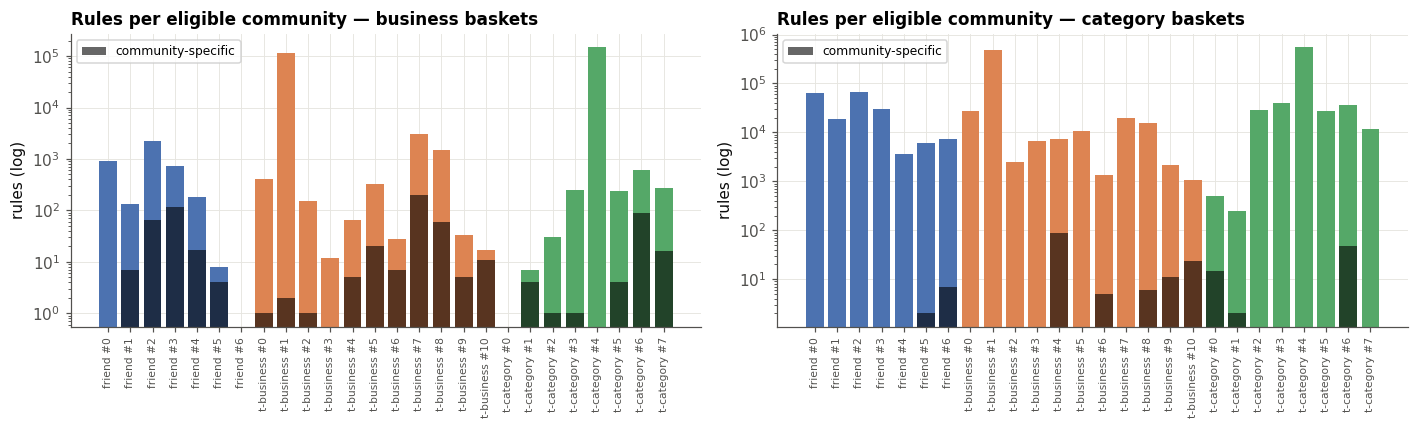

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, v in zip(axes, VERSIONS):
    d = comm[comm.eligible & (comm.basket_type == v) & (comm.community_system != "period")]
    lab = d.community_system.str.replace("taste_", "t-") + " #" + d.community_id.astype(str)
    colors = d.community_system.map({"friend": "#4c72b0", "taste_business": "#dd8452", "taste_category": "#55a868"})
    ax.bar(range(len(d)), d.rules, color=colors)
    ax.bar(range(len(d)), d.rules_specific, color="black", alpha=.6, label="community-specific")
    ax.set(yscale="log", title=f"Rules per eligible community — {v} baskets", ylabel="rules (log)")
    ax.set_xticks(range(len(d))); ax.set_xticklabels(lab, rotation=90, fontsize=7); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "04_rules_per_community.png", dpi=150); plt.show()

In [72]:
# same-business tag artefacts among category rules
tag = pd.DataFrame([{"community_system": s, "rules": len(RULES[s, "category"]),
                     "tag_flagged": int((RULES[s, "category"].same_business_share >= TAG_SHARE_MAX).sum()),
                     "pair_rules": len(R.pair_rules(RULES[s, "category"])),
                     "pair_tag_flagged": int((R.pair_rules(RULES[s, "category"]).same_business_share >= TAG_SHARE_MAX).sum())}
                    for s in SYSTEMS]).assign(share_flagged=lambda d: (d.tag_flagged / d.rules).round(3))
display(tag)
ex = readable(R.pair_rules(RULES["friend", "category"]), "category").drop_duplicates("rule")
display(ex.sort_values("same_business_share", ascending=False)[["rule", "same_business_share", "lift"]].head(8).round(2))

,community_system,rules,tag_flagged,pair_rules,pair_tag_flagged,share_flagged
0,friend,196274,6709,9855,122,0.034
1,taste_business,567226,11084,15319,197,0.020
2,taste_category,689898,12609,15437,172,0.018


,rule,same_business_share,lift
0,Music Venues → Arts & Entertainment,1.0,3.16
1574,Ramen → Japanese,1.0,1.66
1098,Wine & Spirits → Beer,1.0,1.70
968,Beer → Wine & Spirits,1.0,1.70
1679,Caterers → Event Planning & Services,1.0,1.65
1761,Venues & Event Spaces → Event Planning & Services,1.0,1.65
159691,Cantonese → Chinese,1.0,1.34
455,Falafel → Mediterranean,1.0,1.79


## 4.5 Comparing rules across community systems

Comparisons use **pair rules** (one item on each side); the direction of a rule is kept (A → B ≠ B → A). Triple rules are still mined and saved (4.4).

**Measures, per system and basket type**
- `median_lift_ratio`, `share_lift_ratio_lt1`: how much the partition **absorbs** the population's associations. If a partition groups users who like the same things, a population-wide association is partly explained by community membership, so inside a community the lift drops towards 1 (`lift_ratio` < 1).
- `rules_specific`: rules with `lift_ratio ≥ 1.5`.
- `all_/specific_mean_pairwise_jaccard`: average Jaccard between the rule sets of two communities.
- `all_/specific_share_unique`: share of rules found in only one community.
- `jaccard_vs_*`: Jaccard between the union of a system's specific rules and another system's.

**Null model.** Each number is compared with `N_SHUFFLES` random partitions with exactly the same community sizes (labels shuffled over users); z = (real − null mean) / null sd.

**Activity period.** The 4 period bins of `taste_communities.parquet` are added as a fourth "partition".

Category rules flagged as Yelp-tag artefacts are excluded from the comparison.

In [73]:
REAL, NULL = [], []
t0 = time.perf_counter()
for v in VERSIONS:
    tag_cut = TAG_SHARE_MAX if v == "category" else None
    spec = {s: R.union(R.rule_sets(R.pair_rules(RULES[s, v]), specific_only=True, exclude_tag=tag_cut)) for s in SYSTEMS_ALL}
    for s, lab in SYSTEMS_ALL.items():
        ref = {o: spec[o] for o in SYSTEMS_ALL if o != s}
        REAL.append({"basket_type": v, "community_system": s, **R.partition_measures(RULES[s, v], tag_cut, ref)})
        nm = R.null_model(BASKETS[v], lab, params(v, max_k=2), POP[v], N_SHUFFLES, SEED,
                          BIZ_INDEX if v == "category" else None, ref, tag_cut)
        NULL.append(nm.assign(basket_type=v, community_system=s))
REAL, NULL = pd.DataFrame(REAL), pd.concat(NULL, ignore_index=True)
print(f"null model: {N_SHUFFLES} shuffles x 4 systems x 2 basket types in {time.perf_counter() - t0:.0f} s")

null model: 20 shuffles x 4 systems x 2 basket types in 43 s


In [74]:
MEASURES = ["pair_rules", "median_lift_ratio", "share_lift_ratio_lt1", "rules_specific",
            "all_mean_pairwise_jaccard", "all_share_unique", "specific_share_unique"]

def vs_null(measures):
    rows = []
    for (v, s), g in NULL.groupby(["basket_type", "community_system"]):
        real = REAL[(REAL.basket_type == v) & (REAL.community_system == s)].iloc[0]
        for m in measures:
            if m not in g: continue
            mu, sd = g[m].mean(), g[m].std()
            rows.append({"basket_type": v, "community_system": s, "measure": m, "real": real[m],
                         "null_mean": mu, "null_sd": sd, "z": (real[m] - mu) / sd if sd > 0 else np.nan})
    return pd.DataFrame(rows)

CMP = vs_null(MEASURES)
order = list(SYSTEMS_ALL)
for v in VERSIONS:
    print(f"\n=== {v} baskets: real partition vs. {N_SHUFFLES} same-size random partitions")
    t = CMP[CMP.basket_type == v].pivot(index="measure", columns="community_system", values=["real", "null_mean", "z"])
    display(t.reindex(MEASURES).swaplevel(axis=1).reindex(columns=order, level=0).round(3))


=== business baskets: real partition vs. 20 same-size random partitions


community_system             friend                   taste_business                    taste_category                      period                  
                               real null_mean       z           real null_mean        z           real null_mean       z      real null_mean       z
measure                                                                                                                                             
pair_rules                 2534.000  1615.300   4.190      14279.000  3814.950   37.692      15401.000  2608.450  42.339  1437.000   808.450  12.286
median_lift_ratio             1.030     1.268  -5.049          0.595     1.433  -26.230          0.609     1.339 -18.021     1.039     1.134 -10.785
share_lift_ratio_lt1          0.445     0.113  20.795          0.952     0.072  122.082          0.976     0.095  86.359     0.440     0.173  28.369
rules_specific              151.000   466.950  -2.040        240.000  1702.500   -6.878        106.000   935.050  -3.577    41.000    67.000  -1.732
all_mean_pairwise_jaccard     0.033     0.100  -7.646          0.002     0.098  -17.235          0.019     0.135 -19.396     0.065     0.222 -19.134
all_share_unique              0.824     0.711   3.439          0.966     0.705   13.461          0.963     0.690  10.771     0.834     0.655   7.392
specific_share_unique         1.000     0.985   1.875          1.000     0.934   12.081          1.000     0.966   3.508     1.000     0.999   0.224


=== category baskets: real partition vs. 20 same-size random partitions


community_system             friend                    taste_business                     taste_category                        period                  
                               real  null_mean       z           real  null_mean        z           real  null_mean        z      real null_mean       z
measure                                                                                                                                                 
pair_rules                 9733.000  12066.750  -7.256      15122.000  18830.000  -11.102      15265.000  13632.500    8.211  6897.000  6796.650   1.515
median_lift_ratio             0.993      1.002  -6.927          0.889      1.003 -160.677          0.845      1.002 -228.245     1.002     1.001   4.760
share_lift_ratio_lt1          0.556      0.465   4.775          0.858      0.468   47.607          0.954      0.473   49.478     0.475     0.487  -1.485
rules_specific                0.000      0.950  -0.700          3.000      0.000      NaN          1.000      0.000      NaN     0.000     0.000     NaN
all_mean_pairwise_jaccard     0.431      0.797 -37.662          0.259      0.806  -46.366          0.184      0.839  -86.740     0.690     0.894 -17.090
all_share_unique              0.252      0.166   2.578          0.677      0.130   26.753          0.628      0.101   38.927     0.190     0.075   6.219
specific_share_unique           NaN      1.000     NaN          1.000        NaN      NaN          1.000        NaN      NaN       NaN       NaN     NaN

In [75]:
# overlap of community-specific rules between systems, with the null for comparison
J = vs_null([f"jaccard_vs_{o}" for o in SYSTEMS_ALL])
J = J.dropna(subset=["real"]).assign(other=lambda d: d.measure.str.replace("jaccard_vs_", ""))
display(J[J.community_system == "friend"][["basket_type", "community_system", "other", "real", "null_mean", "null_sd", "z"]].round(4))

,basket_type,community_system,other,real,null_mean,null_sd,z
1,business,friend,taste_business,0.0000,0.0070,0.0041,-1.7004
2,business,friend,taste_category,0.0039,0.0097,0.0049,-1.1908
3,business,friend,period,0.0213,0.0056,0.0026,6.1444
17,category,friend,taste_business,0.0000,0.0000,0.0000,NaN
18,category,friend,taste_category,0.0000,0.0000,0.0000,NaN
19,category,friend,period,0.0000,0.0000,0.0000,NaN


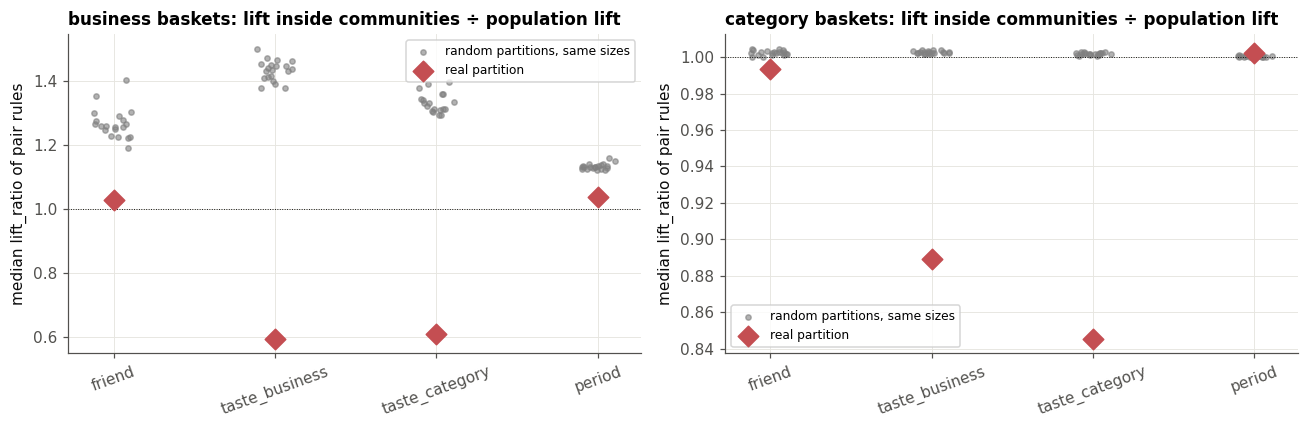

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, v in zip(axes, VERSIONS):
    for k, s in enumerate(order):
        g = NULL[(NULL.basket_type == v) & (NULL.community_system == s)]["median_lift_ratio"]
        real = REAL[(REAL.basket_type == v) & (REAL.community_system == s)]["median_lift_ratio"].iloc[0]
        ax.scatter(np.full(len(g), k) + np.random.default_rng(k).uniform(-.12, .12, len(g)), g, s=12, color="grey", alpha=.6,
                   label="random partitions, same sizes" if k == 0 else None)
        ax.scatter([k], [real], s=90, marker="D", color="#c44e52", label="real partition" if k == 0 else None, zorder=3)
    ax.axhline(1, color="black", lw=.6, ls=":")
    ax.set(xticks=range(len(order)), xticklabels=order, ylabel="median lift_ratio of pair rules",
           title=f"{v} baskets: lift inside communities ÷ population lift")
    ax.tick_params(axis="x", rotation=20); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(FIGURES / "04_lift_ratio_vs_null.png", dpi=150); plt.show()

In [77]:
# rules shared by several friend communities, and specific friend rules that are also period rules
for v in VERSIONS:
    pr = R.pair_rules(RULES["friend", v])
    if v == "category":
        pr = pr[pr.same_business_share < TAG_SHARE_MAX]
    k = R.rule_keys(pr)
    n_comm = k.groupby(k).transform("size")
    shared = readable(pr[n_comm >= 3], v).groupby("rule").agg(communities=("community_id", "nunique"),
                                                             lift_min=("lift", "min"), lift_max=("lift", "max"))
    print(f"{v}: {len(set(k))} distinct friend pair rules; {int((k.value_counts() >= 3).sum())} appear in >= 3 friend communities")
    display(shared.sort_values(["communities", "lift_max"], ascending=False).head(5).round(2))

business: 2081 distinct friend pair rules; 71 appear in >= 3 friend communities


,communities,lift_min,lift_max
rule,,,
Talula's Garden → Zahav,5,2.59,4.05
Amada → Zahav,5,2.15,3.51
Vernick Food & Drink → Zahav,4,2.92,6.09
Abe Fisher → Zahav,4,3.38,5.06
Philadelphia Museum of Art → Reading Terminal Market,4,1.60,3.95


category: 2893 distinct friend pair rules; 1651 appear in >= 3 friend communities


,communities,lift_min,lift_max
rule,,,
Vegetarian → Vegan,7,1.40,2.02
French → Wine Bars,7,1.51,1.97
Middle Eastern → Mediterranean,7,1.34,1.85
Thai → Asian Fusion,7,1.27,1.81
Ethnic Food → Middle Eastern,7,1.42,1.80


In [78]:
# period composition of the eligible friend communities (confounder)
elig_f = comm[(comm.community_system == "friend") & comm.eligible & (comm.basket_type == "business")].community_id
mix = pd.crosstab(friend.reindex(taste_c.index), taste_c["period"], normalize="index").loc[elig_f]
display((mix * 100).round(0).astype(int).add_suffix(" %"))

period,2011-13 %,2014-16 %,<=2010 %,>=2017 %
friend_community,,,,
0,4,24,0,72
1,30,13,52,5
2,48,42,3,7
3,18,37,4,41
4,23,32,12,32
5,28,46,5,20
6,20,51,3,25


## 4.6 Robustness over the 20 Louvain seeds

For every saved Louvain seed (sections 2 and 3), the pair-level measures of 4.5 are recomputed (`MAX_K = 2`, which gives exactly the same pair rules), together with the Jaccard between that seed's specific rules and the chosen partition's. Communities are matched **by rule content, never by label**.

In [79]:
SEED_FILES = {"friend": (DATA_PROCESSED / "philadelphia_pa_friend_communities_all_seeds.parquet", 9),
              "taste_business": (RESULTS / "taste_communities_all_seeds_business.parquet", None),
              "taste_category": (RESULTS / "taste_communities_all_seeds_category.parquet", None)}
taste_summary = json.loads((RESULTS / "taste_summary.json").read_text())
ROB = []
t0 = time.perf_counter()
for s, (path, chosen) in SEED_FILES.items():
    seeds = pd.read_parquet(path).set_index("user_id")
    if chosen is None:
        chosen = int(taste_summary["communities"][s.replace("taste_", "")]["best seed"])
    for v in VERSIONS:
        tag_cut = TAG_SHARE_MAX if v == "category" else None
        ref = R.union(R.rule_sets(R.pair_rules(RULES[s, v]), specific_only=True, exclude_tag=tag_cut))
        for col in seeds.columns:
            _, r = R.mine_partition(BASKETS[v], seeds[col], params(v, max_k=2), POP[v], BIZ_INDEX if v == "category" else None)
            m = R.partition_measures(r, tag_cut, {"chosen": ref})
            ROB.append({"community_system": s, "basket_type": v, "seed": int(col.split("_")[1]),
                        "is_chosen": int(col.split("_")[1]) == chosen, **m})
ROB = pd.DataFrame(ROB)
print(f"{len(ROB)} partitions mined in {time.perf_counter() - t0:.0f} s")
rob = (ROB[~ROB.is_chosen].groupby(["community_system", "basket_type"])
       [["median_lift_ratio", "share_lift_ratio_lt1", "rules_specific", "jaccard_vs_chosen"]]
       .agg(["mean", "min", "max"]).round(3))
display(rob)

120 partitions mined in 49 s


median_lift_ratio               share_lift_ratio_lt1               rules_specific            jaccard_vs_chosen              
                                          mean    min    max                 mean    min    max           mean  min   max              mean    min    max
community_system basket_type                                                                                                                             
friend           business                1.035  0.986  1.114                0.444  0.328  0.526        330.737  126   629             0.165  0.042  0.307
                 category                0.992  0.985  1.002                0.572  0.482  0.640          0.526    0     4             0.000  0.000  0.000
taste_business   business                0.602  0.568  0.633                0.911  0.863  0.960        409.684  176  1115             0.131  0.055  0.224
                 category                0.891  0.871  0.910                0.865  0.834  0.898          5.000    1    16             0.022  0.000  0.154
taste_category   business                0.628  0.564  0.700                0.958  0.903  0.990        127.421   15   281             0.201  0.027  0.441
                 category                0.842  0.814  0.863                0.953  0.933  0.970          1.368    0     4             0.158  0.000  1.000

## 4.7 Saved outputs

| File | One row per | Content |
|---|---|---|
| `data/results/step4_basket_summary.parquet` | basket type | users, exclusions, items, basket sizes |
| `data/results/step4_frequent_itemsets.parquet` | itemset (full population) | `basket_type`, `itemset_ids`, `itemset_names`, `size`, `support_count`, `support` |
| `data/results/step4_rules.parquet` | rule × community | `community_system`, `basket_type`, `community_id`, `antecedent_ids/names`, `consequent_ids/names`, `support_count`, `support`, `confidence`, `lift`, `confidence_pop`, `lift_pop`, `lift_ratio`, `specific`, `same_business_share`, `same_business_tag` |
| `data/results/step4_community_metrics.parquet` | community | sizes, threshold (fraction + count), itemsets by size, rule counts, eligibility + reason |
| `data/results/step4_benchmark.parquet` | algorithm × collection | runtime per pass (median), peak memory |
| `data/results/step4_candidates.parquet` | collection | candidate-pair counts and structure sizes |
| `data/results/step4_bucket_sweep.parquet` | bucket count | PCY filtering vs. memory |
| `data/results/step4_comparison.parquet`, `step4_null.parquet` | measure / shuffle | 4.5 real vs. null |
| `data/results/step4_seed_robustness.parquet` | seed | 4.6 |
| `data/results/step4_summary.json` | — | parameters, environment, headline numbers |

In [80]:
def ids_names(t, v):
    return [str(BASKETS[v].item_ids[i]) for i in t], [str(NAMES[v][i]) for i in t]

def export_rules(r, v):
    a = [ids_names(t, v) for t in r.antecedent]; c = [ids_names(t, v) for t in r.consequent]
    out = r.drop(columns=["antecedent", "consequent"]).assign(
        antecedent_ids=[x[0] for x in a], antecedent_names=[x[1] for x in a],
        consequent_ids=[x[0] for x in c], consequent_names=[x[1] for x in c], basket_type=v)
    if "same_business_share" in out:
        out = out.assign(same_business_tag=out.same_business_share >= TAG_SHARE_MAX)
    return out

rules_out = pd.concat([export_rules(r, v).assign(community_system=s, community_id=lambda d: d.community_id.astype(str))
                       for (s, v), r in RULES.items() if not r.empty], ignore_index=True)
itemsets_out = pd.concat([pd.DataFrame([{"basket_type": v, "itemset_ids": ids_names(k, v)[0], "itemset_names": ids_names(k, v)[1],
                                         "size": len(k), "support_count": c, "support": c / FULL[v].n_transactions,
                                         "min_count": FULL[v].min_count} for k, c in FULL[v].itemsets.items()]) for v in VERSIONS],
                         ignore_index=True)
CAND_OUT = CAND.drop(columns=["candidates_k", "itemsets_by_size"]).assign(
    itemsets_by_size=CAND.itemsets_by_size.map(json.dumps), candidates_k=CAND.candidates_k.map(json.dumps))
outputs = {"step4_basket_summary": basket_summary, "step4_frequent_itemsets": itemsets_out, "step4_rules": rules_out,
           "step4_community_metrics": comm.assign(community_id=comm.community_id.astype(str)),
           "step4_benchmark": BENCH, "step4_candidates": CAND_OUT, "step4_bucket_sweep": SWEEP,
           "step4_comparison": pd.concat([CMP, J.drop(columns="other")], ignore_index=True), "step4_null": NULL,
           "step4_seed_robustness": ROB}
for name, df in outputs.items():
    df.to_parquet(RESULTS / f"{name}.parquet", index=False)
    print(f"{name}.parquet: {len(df):,} rows")

summary = {
    "params": {"seed": SEED, "positive": "is_positive (stars >= 3.5)", "generic_max_frac": GENERIC_MAX_FRAC,
               "max_cats_per_business": MAX_CATS_PER_BUSINESS, "min_businesses_per_category": MIN_BUSINESSES_PER_CATEGORY,
               "min_basket_items": MIN_BASKET_ITEMS, "min_support": MIN_SUPPORT, "min_confidence": MIN_CONFIDENCE,
               "min_lift": MIN_LIFT, "max_k": MAX_K, "min_count_rule": f"max(ceil(min_support * n), {MIN_COUNT_FLOOR})",
               "min_community_size": MIN_COMMUNITY_SIZE, "lift_ratio_min": LIFT_RATIO_MIN, "tag_share_max": TAG_SHARE_MAX,
               "n_shuffles": N_SHUFFLES, "n_buckets": N_BUCKETS, "timing_reps": TIMING_REPS,
               "comparison_rules": "pair rules (1 item -> 1 item)"},
    "environment": BM.environment(),
    "baskets": basket_summary.to_dict("records"),
    "full_population_itemsets": {v: FULL[v].by_size() for v in VERSIONS},
    "communities": excl.reset_index().to_dict("records"),
    "benchmark_population": BENCH[BENCH.collection == "population"][["basket_type", "algorithm", "total_s", "pass1_s", "pass2_pairs_s", "peak_mem_mb"]].to_dict("records"),
    "comparison_real_vs_null": CMP.round(4).to_dict("records"),
}
(RESULTS / "step4_summary.json").write_text(json.dumps(summary, indent=2, default=str))
print("step4_summary.json written")

step4_basket_summary.parquet: 2 rows
step4_frequent_itemsets.parquet: 11,917 rows


step4_rules.parquet: 1,859,393 rows
step4_community_metrics.parquet: 178 rows
step4_benchmark.parquet: 16 rows
step4_candidates.parquet: 8 rows
step4_bucket_sweep.parquet: 8 rows
step4_comparison.parquet: 80 rows
step4_null.parquet: 160 rows
step4_seed_robustness.parquet: 120 rows
step4_summary.json written


## 4.8 Summary

A-priori and PCY return identical frequent itemsets on every collection (4.2).

**Pair rules: share with a lower lift inside the community than in the population** (`share_lift_ratio_lt1`; random partitions with the same sizes in brackets)

| Community system | Restaurant baskets | Category baskets |
|---|---|---|
| friend | 0.445 (0.113) | 0.556 (0.465) |
| period of activity | 0.440 (0.173) | 0.475 (0.487) |
| restaurant taste | 0.952 (0.072) | 0.858 (0.468) |
| category taste | 0.976 (0.095) | 0.954 (0.473) |

**Median `lift_ratio`** (random partitions in brackets)

| Community system | Restaurant baskets | Category baskets |
|---|---|---|
| friend | 1.030 (1.268) | 0.993 (1.002) |
| period of activity | 1.039 (1.134) | 1.002 (1.001) |
| restaurant taste | 0.595 (1.433) | 0.889 (1.003) |
| category taste | 0.609 (1.339) | 0.845 (1.002) |

# 5. Comparison of friend and taste communities

*Code: `src/comparison.py` (functions, tested in `tests/test_comparison.py`). The same analysis can be run from the command line with `python src/comparison.py`.*

**Plan**
- **5.1** Inputs and sanity check.
- **5.2** The measures: NMI, ARI (and AMI), noise ceiling, permutation tests.
- **5.3** Partition level: friend vs taste partition (chosen runs and the 20 × 20 saved runs), noise ceiling, period baselines, sensitivity to isolated users and tiny communities.
- **5.4** Pair level: friend pairs against other pairs.
- **5.5** Restaurant-based vs category-based taste partitions.
- **5.6** Figures.
- **5.7** Save.
- **5.8** Summary.

## 5.0 Parameters

Inputs are the files written by sections 1–3 (nothing is recomputed from the raw data): `data/processed/philadelphia_pa_friend_communities*.parquet`, `philadelphia_pa_friend_edges.parquet`, `philadelphia_pa_{reviews,businesses,users}.parquet` and `data/results/taste_communities*.parquet`. Outputs: `data/results/comparison_*.json/csv` (not in git) and `figures/05_*.png`.

In [81]:
import comparison as C   # project module (src/)

# ---------------- Parameters ----------------
N_PERM_MAIN = 10_000    # permutations for the chosen pair of partitions (smallest possible p = 1/10,001)
N_PERM_GRID = 1_000     # permutations for each of the 20 x 20 grid cells
N_PERM_OTHER = 1_000    # period baselines, sensitivity variants, friend-pair share
N_PERM_PAIRS = 1_000    # friend-pair Jaccard test (the report uses P = 1000)
STRICT = True           # stop if the regenerated partitions differ from the numbers in the report

## 5.1 Inputs and sanity check

`load_inputs` reads the files of sections 1–3 and aligns them on the same users. `check_against_report` compares what was loaded with the reference numbers (7,947 users; 51 friend communities; 17 category and 17 restaurant taste communities in the chosen runs, including the singleton communities of isolated users). With `STRICT = True` the notebook stops if anything differs.

In [82]:
inp = C.load_inputs(ROOT)
sanity = C.check_against_report(inp, STRICT)
print("found:", sanity["found"])
print("matches the report:", sanity["ok"])

print(f"\n{len(inp.edge_u):,} friend pairs; {inp.friend_seeds.shape[1]} friend runs; "
      f"{ {v: inp.taste_seeds[v].shape[1] for v in C.VERSIONS} } taste runs")
pd.DataFrame({"users": np.bincount(inp.period)}, index=inp.period_labels).T

found: {'n_users': 7947, 'friend_communities': 51, 'taste_communities': {'category': 17, 'business': 17}, 'n_isolated_users': {'category': 8, 'business': 6}, 'n_friend_pairs': 67622, 'n_friend_runs': 20, 'n_taste_runs': {'category': 20, 'business': 20}}
matches the report: True

67,622 friend pairs; 20 friend runs; {'category': 20, 'business': 20} taste runs


,<=2010,2011-13,2014-16,>=2017
users,1060,1841,2329,2717


In [83]:
# community sizes of the chosen partitions (largest first)
def sizes(x, k=8):
    s = pd.Series(x).value_counts().to_numpy()
    return f"{len(s)} communities; largest {', '.join(map(str, s[:k]))} ..."

print("friends:          ", sizes(inp.friend_main))
for v in C.VERSIONS:
    print(f"taste, {v:<9}:", sizes(inp.taste_main[v]), f"| isolated users: {int(inp.isolated[v].sum())}")

friends:           51 communities; largest 2460, 1667, 1607, 818, 661, 196, 123, 98 ...
taste, category : 17 communities; largest 1539, 1303, 1248, 1163, 1087, 855, 366, 324 ... | isolated users: 8
taste, business : 17 communities; largest 1319, 1198, 1059, 1007, 938, 715, 503, 389 ... | isolated users: 6


## 5.2 The measures

* **NMI** (normalised mutual information): how much knowing a user's friend community tells about their taste community; 0 = nothing, 1 = identical partitions. Arithmetic-mean normalisation (the scikit-learn default). With many small clusters NMI is **inflated by chance**, so it is always shown with its null.
* **ARI** (adjusted Rand index): fraction of user pairs on which the two partitions agree, corrected for chance; 0 = random, 1 = identical. Dominated by the large communities.
* **AMI**: NMI corrected for chance with the exact expected value; computed for the headline pairs only (too slow for thousands of permutations).
* Community labels are arbitrary: only the grouping matters.

**Noise ceiling.** The agreement between two Louvain runs of the *same* method (friend vs friend runs, taste vs taste runs). Two partitions cannot agree with each other more than each agrees with itself, so this is the upper reference for every result.

**Permutation test, controlling for the period.** The friend partition stays fixed; taste labels are shuffled **among users of the same period bin** (≤ 2010, 2011–13, 2014–16, ≥ 2017; the median year of each user's reviews). This keeps the link between taste and period but destroys the link between taste and friends, so the null distribution is the agreement the period alone produces. p = (1 + #{null ≥ observed}) / (1 + P). The **plain** shuffle (all users together) is reported as well.

The first cell checks our NMI/ARI against scikit-learn on the chosen partitions (it raises an error if they differ).

In [84]:
for v in C.VERSIONS:
    view = C.make_view(inp, v)
    print(v, {k: round(x, 6) for k, x in C.verify_against_sklearn(view.f_main, view.t_main).items()})

category {'nmi': 0.041685, 'ari': 0.013278, 'sklearn_nmi': 0.041685, 'sklearn_ari': 0.013278}
business {'nmi': 0.053982, 'ari': 0.033947, 'sklearn_nmi': 0.053982, 'sklearn_ari': 0.033947}


## 5.3 Partition level: category taste (main) and restaurant taste

For each taste version, `analyse_version` runs: the chosen pair with `N_PERM_MAIN` permutations, the 20 × 20 grid of saved runs (each cell with its own within-period null), the noise ceilings, the period baselines, the sensitivity variants and the friend-pair share. The category version is the main one.

Users with no similar pair in the taste graph (6–8 users) are singleton "communities" and are **excluded** from the main analysis; 5.3.4 includes them as a variant.

In [85]:
res_cat, tab_cat = C.analyse_version(inp, "category", N_PERM_MAIN, N_PERM_GRID, N_PERM_OTHER, SEED)

[category] 7,939 users (8 isolated excluded), 67,591 friend pairs


[category] chosen partitions, 10,000 permutations


[category] 20 x 20 grid, 1,000 permutations


    grid permutations 250/1000


    grid permutations 500/1000


    grid permutations 750/1000


... (2 outputs left out)

    edge-share permutations 250/1000


    edge-share permutations 500/1000


    edge-share permutations 750/1000


    edge-share permutations 1000/1000


In [86]:
res_bus, tab_bus = C.analyse_version(inp, "business", N_PERM_MAIN, N_PERM_GRID, N_PERM_OTHER, SEED)

[business] 7,941 users (6 isolated excluded), 67,595 friend pairs


[business] chosen partitions, 10,000 permutations


[business] 20 x 20 grid, 1,000 permutations


    grid permutations 250/1000


    grid permutations 500/1000


    grid permutations 750/1000


... (2 outputs left out)

    edge-share permutations 250/1000


    edge-share permutations 500/1000


    edge-share permutations 750/1000


    edge-share permutations 1000/1000


In [87]:
results = {"parameters": {"n_perm_main": N_PERM_MAIN, "n_perm_grid": N_PERM_GRID, "n_perm_other": N_PERM_OTHER,
                          "n_perm_pairs": N_PERM_PAIRS, "seed": SEED, "min_community": C.MIN_COMMUNITY,
                          "period_bins": inp.period_labels},
           "sanity": sanity, "versions": {"category": res_cat, "business": res_bus}}
tables = {"category": tab_cat, "business": tab_bus}

### 5.3.1 Chosen partitions against both null models

In [88]:
C.main_table(results).round(4)

,taste version,measure,observed,"chance, shuffled within period",excess,z,p (within period),"chance, plain shuffle",p (plain shuffle)
0,category taste,NMI,0.0417,0.0214,0.0203,19.8296,0.0001,0.0112,0.0001
1,category taste,ARI,0.0133,0.0054,0.0079,9.3799,0.0001,-0.0000,0.0001
2,category taste,NMI inside period bins,0.0475,0.0251,0.0224,23.6732,0.0001,NaN,NaN
3,category taste,ARI inside period bins,0.0072,-0.0000,0.0072,6.5214,0.0001,NaN,NaN
4,category taste,AMI,0.0308,NaN,NaN,NaN,NaN,NaN,NaN
5,restaurant taste,NMI,0.0540,0.0283,0.0257,22.5892,0.0001,0.0129,0.0001
6,restaurant taste,ARI,0.0339,0.0170,0.0169,12.2848,0.0001,0.0000,0.0001
7,restaurant taste,NMI inside period bins,0.0583,0.0288,0.0295,28.4871,0.0001,NaN,NaN
8,restaurant taste,ARI inside period bins,0.0212,-0.0000,0.0212,12.2225,0.0001,NaN,NaN
9,restaurant taste,AMI,0.0416,NaN,NaN,NaN,NaN,NaN,NaN


Columns: *observed* agreement, the null mean, `excess` = observed − null mean, `z` and `p`. Rows: within-period shuffle and plain shuffle. *Inside period bins* compares friends and tastes only among users active in the same period.

### 5.3.2 Robustness over the 20 × 20 saved runs

In [89]:
C.grid_table(results).round(4)

,taste version,measure,observed mean,sd,min,max,chance mean,mean excess,share of cells with p<0.05,largest p
0,category taste,NMI,0.0421,0.0039,0.0334,0.0533,0.0216,0.0205,1.0000,0.001
1,category taste,ARI,0.0153,0.0038,0.0036,0.0249,0.0072,0.0081,0.9575,0.975
2,restaurant taste,NMI,0.0673,0.0104,0.0415,0.0853,0.0349,0.0325,1.0000,0.001
3,restaurant taste,ARI,0.0394,0.0064,0.0225,0.0562,0.0188,0.0206,1.0000,0.001


Each cell is one friend run against one taste run, with its own within-period null (same permutations for all cells). `share of cells with p<0.05` is the fraction of the 400 comparisons in which the result is not explained by the period.

### 5.3.3 Noise ceiling and period baselines

In [90]:
C.build_table_v(results)

,taste version,comparison,NMI,ARI
0,category taste,chosen runs,0.042,0.013
1,category taste,"20x20 runs, mean [min, max]","0.042 [0.033, 0.053]","0.015 [0.004, 0.025]"
2,category taste,"chance, shuffled within period","0.022 [0.013, 0.032]","0.007 [0.004, 0.013]"
3,category taste,friend vs period (20 runs),"0.200 [0.156, 0.233]","0.196 [0.126, 0.235]"
4,category taste,taste vs period (20 runs),"0.028 [0.018, 0.036]","0.016 [0.009, 0.026]"
5,category taste,ceiling: friend vs friend runs,"0.522 [0.360, 0.756]","0.538 [0.300, 0.841]"
6,category taste,ceiling: taste vs taste runs,"0.423 [0.352, 0.521]","0.315 [0.193, 0.471]"
7,restaurant taste,chosen runs,0.054,0.034
8,restaurant taste,"20x20 runs, mean [min, max]","0.067 [0.042, 0.085]","0.039 [0.022, 0.056]"
9,restaurant taste,"chance, shuffled within period","0.035 [0.018, 0.051]","0.019 [0.009, 0.024]"


Rows: **friend vs taste**, against **taste vs period** and **friend vs period**, and the two noise ceilings (friend vs friend runs, taste vs taste runs).

### 5.3.4 Sensitivity: isolated users and tiny communities

In [91]:
C.sensitivity_table(results).round(4)

,taste version,variant,users,friend comm.,taste comm.,NMI,NMI chance,NMI p,ARI,ARI chance,ARI p,"mean NMI, 20 friend runs"
0,category taste,main: users isolated in the taste graph excluded,7939,51,9,0.0417,0.0214,0.001,0.0133,0.0054,0.001,0.0418
1,category taste,isolated users included (each is a singleton community),7947,51,17,0.0430,0.0222,0.001,0.0133,0.0053,0.001,0.0429
2,category taste,tiny communities (< 10 users) merged into one group,7939,14,9,0.0351,0.0138,0.001,0.0134,0.0054,0.001,0.0347
3,category taste,users in tiny communities (< 10) dropped,7808,13,9,0.0347,0.0138,0.001,0.0141,0.0055,0.001,0.0345
4,restaurant taste,main: users isolated in the taste graph excluded,7941,51,11,0.0540,0.0284,0.001,0.0339,0.0170,0.001,0.0530
5,restaurant taste,isolated users included (each is a singleton community),7947,51,17,0.0551,0.0289,0.001,0.0340,0.0170,0.001,0.0539
6,restaurant taste,tiny communities (< 10 users) merged into one group,7941,14,11,0.0446,0.0198,0.001,0.0339,0.0170,0.001,0.0430
7,restaurant taste,users in tiny communities (< 10) dropped,7810,13,11,0.0452,0.0200,0.001,0.0337,0.0172,0.001,0.0437


Variants: the isolated users included (each a singleton community); every community with fewer than 10 users merged into one group; the users of those communities dropped.

## 5.4 Pair level: friend pairs against other pairs

The 67,622 friend pairs are compared with other pairs of users, without communities. Two statistics:

* the share of friend pairs whose two users are in the **same taste community** (all 20 taste runs);
* the **mean Jaccard similarity** of the two users' liked sets (and the share of pairs with at least one liked item in common).

Two null models: **random user pairs** (as many as friend pairs), and **within period** (every user's taste data is swapped with a random user of the same period bin while the friend edges stay fixed, so each friend pair is compared with pairs active in the same periods).

The liked sets are rebuilt with `taste.build_user_sets` using the parameters section 3 saved in `taste_summary.json` (the function's own defaults differ: 0.30 vs 0.80 for the generic-category threshold and 10 vs 20 for the maximum number of categories per restaurant), and checked against the sizes section 3 reports. Only users with a non-empty set enter the Jaccard test.

In [92]:
mats, set_info = C.build_taste_matrices(ROOT, inp.users, STRICT)
results["sets"] = set_info
results["jaccard"], pair_nulls = C.analyse_pairs(inp, mats, N_PERM_PAIRS, SEED + 6)
set_info

[category] Jaccard test: 7,941 users, 67,595 friend pairs, 1,000 permutations


    Jaccard permutations 250/1000


    Jaccard permutations 500/1000


    Jaccard permutations 750/1000


    Jaccard permutations 1000/1000


[business] Jaccard test: 7,941 users, 67,595 friend pairs, 1,000 permutations


    Jaccard permutations 250/1000


    Jaccard permutations 500/1000


    Jaccard permutations 750/1000


    Jaccard permutations 1000/1000


{'params': {'positive': 'is_positive',
  'generic_max_frac': 0.8,
  'max_cats_per_business': 20,
  'min_businesses_per_category': 5},
 'category': {'users_with_set': 7941,
  'n_items': 196,
  'mean_set_size': 34.90907946102506,
  'problems': []},
 'business': {'users_with_set': 7941,
  'n_items': 5414,
  'mean_set_size': 22.00453343407631,
  'problems': []}}

In [93]:
C.pair_table(results).round(4)

,taste version,statistic,friend pairs,random pairs,p (random pairs),same-period pairs,p (within period)
0,category taste,share of friend pairs in the same taste community,0.2654,0.1448,0.001,0.1495,0.001
1,category taste,mean Jaccard of the liked sets,0.3056,0.2086,0.001,0.2100,0.001
2,category taste,share of friend pairs with a liked item in common,0.9982,0.9928,0.001,0.9927,0.001
3,restaurant taste,share of friend pairs in the same taste community,0.2722,0.1164,0.001,0.1251,0.001
4,restaurant taste,mean Jaccard of the liked sets,0.0234,0.0082,0.001,0.0091,0.001
5,restaurant taste,share of friend pairs with a liked item in common,0.6837,0.2647,0.001,0.2844,0.001


## 5.5 Restaurant-based vs category-based taste partitions

NMI and ARI between the two taste partitions (chosen runs, users isolated in neither version).

In [94]:
results["taste_vs_taste"] = C.taste_vs_taste(inp)
results["taste_vs_taste"]

{'n_users': 7939,
 'nmi': 0.11484259231555236,
 'ari': np.float64(0.08192942505926483)}

## 5.6 Figures

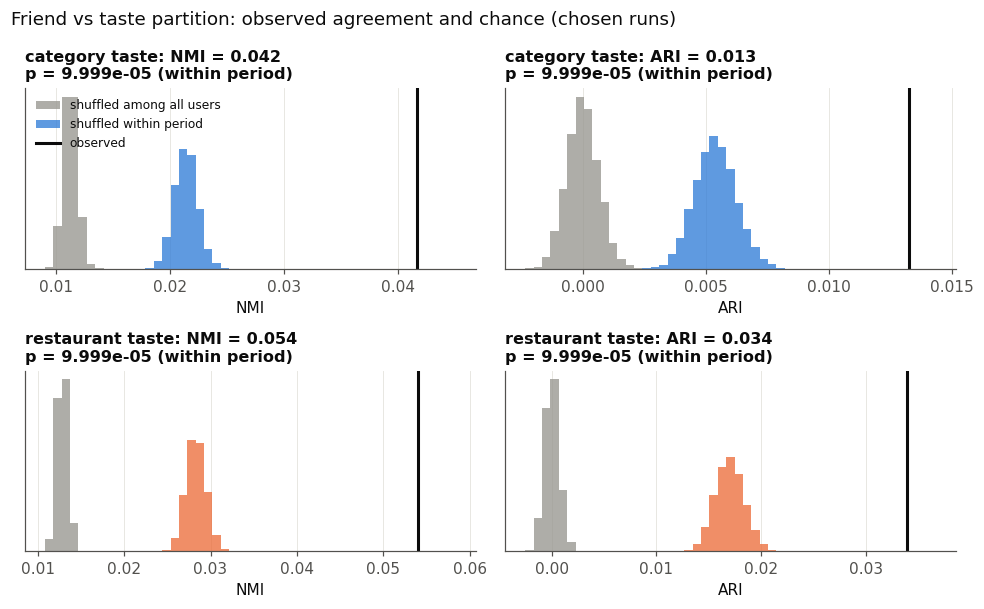

In [95]:
C.plot_main_vs_null(results, tables, FIGURES / "05_main_vs_null.png")
plt.show()

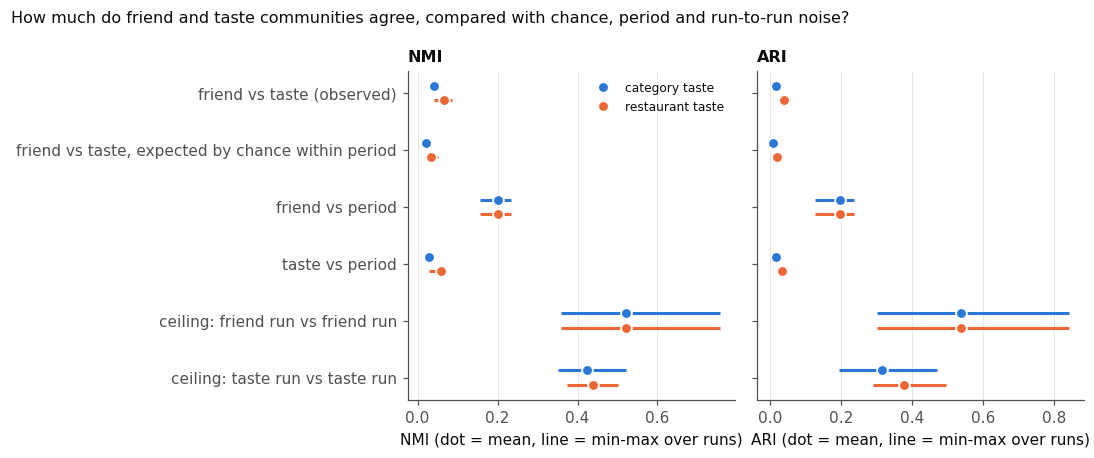

In [96]:
C.plot_agreement_levels(results, FIGURES / "05_agreement_levels.png")
plt.show()

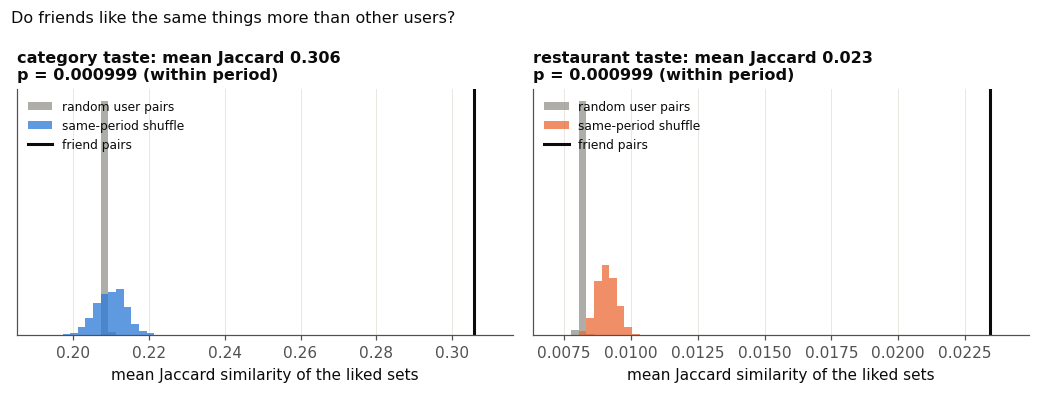

In [97]:
C.plot_pair_tests(results, pair_nulls, FIGURES / "05_pair_tests_report.png", column=True)   # one-column version for the report
plt.close()
C.plot_pair_tests(results, pair_nulls, FIGURES / "05_pair_tests.png")
plt.show()

## 5.7 Save

`data/results/comparison_summary.json` has every number of this section; the CSV files have the 20 × 20 grids and the null distributions.

In [98]:
results["table_v"] = C.build_table_v(results).to_dict(orient="records")
written = C.save_results(ROOT, results, tables, pair_nulls)
print("\n".join(str(p.relative_to(ROOT)) for p in written))

data/results/comparison_summary.json
data/results/comparison_grid_category.csv
data/results/comparison_main_nulls_category.csv
data/results/comparison_grid_business.csv
data/results/comparison_main_nulls_business.csv
data/results/comparison_jaccard_nulls_category.csv
data/results/comparison_jaccard_nulls_business.csv
data/results/comparison_table_v.csv


## 5.8 Summary

*Numbers from `data/results/comparison_summary.json`.*

**Partition level** (chosen runs, isolated users excluded)

| | NMI | chance, within period | chance, plain shuffle | ARI | chance, within period | AMI |
|---|---|---|---|---|---|---|
| category taste | 0.042 | 0.021 | 0.011 | 0.013 | 0.005 | 0.031 |
| restaurant taste | 0.054 | 0.028 | 0.013 | 0.034 | 0.017 | 0.042 |

**Noise ceiling and period baselines** (20 runs; mean)

| | NMI | ARI |
|---|---|---|
| friend vs taste, 20 × 20 runs (category / restaurant) | 0.042 / 0.067 | 0.015 / 0.039 |
| friend vs friend runs | 0.522 | 0.538 |
| taste vs taste runs (category / restaurant) | 0.423 / 0.440 | 0.315 / 0.377 |
| friend vs period | 0.200 | 0.196 |
| taste vs period (category / restaurant) | 0.028 / 0.059 | 0.016 / 0.033 |

**Pair level** (chosen taste partitions and liked sets)

| | friend pairs | same-period pairs | random pairs |
|---|---|---|---|
| same category taste community | 0.265 | 0.149 | 0.145 |
| same restaurant taste community | 0.272 | 0.125 | 0.116 |
| mean Jaccard, liked categories | 0.306 | 0.210 | 0.209 |
| mean Jaccard, liked restaurants | 0.023 | 0.009 | 0.008 |
| share with a liked restaurant in common | 0.684 | 0.284 | 0.265 |

**Restaurant vs category taste partitions:** NMI 0.115, ARI 0.082 (7,939 users).